In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#to ignore warnings
import warnings
warnings.filterwarnings('ignore')
from fredapi import Fred 
import pandas as pd


In [ ]:
from datetime import datetime
import MetaTrader5 as mt5
import pandas as pd
import numpy as np
import pytz
import seaborn as sns
import matplotlib.pyplot as plt
import mplfinance as mpf
import ta

In [5]:
"""
Fundamental Feature Engineering Pipeline
==========================================
Single entry point:
    macro_daily = build_fundamental_features(api_key, start_date, end_date)

Mirrors your notebook exactly — all logic preserved, wrapped into
one callable function.

What it does:
  1. Pulls all 8 series from FRED using get_series_all_releases()
  2. Filters to date window
  3. Standardises each series:
       - First release = actual (what market saw on release day)
       - Previous = latest revision of prior month available BEFORE release
       - Surprise = actual - previous
       - NFP also gets Jobs_Added, Previous_FF, NFP_Surprise
  4. Computes MoM, YoY, Prev, Surprise, Direction for CPI/Core CPI/PCE/Core PCE
  5. Adds Surprise Direction for UNRATE and NFP
  6. Merges all series on 'date' (outer join)
  7. Expands to a daily calendar using merge_asof (backward fill)
     — each daily bar only sees values available on that date (no lookahead)
  8. Computes days_since_* for each release

Output columns match your notebook exactly — same column names,
same prefix convention (UNRATE_, NFP_, CPI_, CORE_CPI_, PCE_, CORE_PCE_).

Usage
-----
    from fundamental_features import build_fundamental_features, FUNDAMENTAL_FEATURE_COLS

    macro_daily = build_fundamental_features(
        api_key    = "YOUR_FRED_KEY",
        start_date = "2010-01-01",
        end_date   = "2023-12-31",
    )
"""

import numpy as np
import pandas as pd
from functools import reduce
from fredapi import Fred


# ═══════════════════════════════════════════════════════════════
# INTERNAL HELPERS
# ═══════════════════════════════════════════════════════════════

def _filter_series(df: pd.DataFrame, start_date: str, end_date: str) -> pd.DataFrame:
    """
    Keep only observation months within [start_date, end_date].
    Sorts by (date, realtime_start) so first release is always first.
    """
    df = df.copy()
    df["date"]           = pd.to_datetime(df["date"])
    df["realtime_start"] = pd.to_datetime(df["realtime_start"])
    df = df[
        (df["date"] >= start_date) &
        (df["date"] <= end_date)
    ].sort_values(["date", "realtime_start"])
    return df.reset_index(drop=True)


def _standardise(df: pd.DataFrame, name: str) -> pd.DataFrame:
    """
    Standardise a FRED all-releases DataFrame for non-NFP series.

    Returns columns:
        date
        {name}_release_date   — realtime_start of first release
        actual                — first release value (what market saw)
        previous              — latest revision of prior month
                                available BEFORE this release date
        surprise              — actual - previous  (current - prior)
    """
    df = df.copy()
    df["date"]           = pd.to_datetime(df["date"])
    df["realtime_start"] = pd.to_datetime(df["realtime_start"])
    df["value"]          = pd.to_numeric(df["value"])
    df = df.sort_values(["date", "realtime_start"])

    # First release of each observation month
    first_release = (
        df.groupby("date", as_index=False)
          .first()[["date", "realtime_start", "value"]]
          .rename(columns={
              "realtime_start": f"{name}_release_date",
              "value":          "actual",
          })
    )

    previous = []
    for _, row in first_release.iterrows():
        prev_month = row["date"] - pd.DateOffset(months=1)
        candidates = df[
            (df["date"] == prev_month) &
            (df["realtime_start"] <= row[f"{name}_release_date"])
        ]
        if len(candidates):
            prev_val = candidates.sort_values("realtime_start").iloc[-1]["value"]
        else:
            prev_val = np.nan
        previous.append(prev_val)

    first_release["previous"] = previous
    first_release["surprise"] = first_release["actual"] - first_release["previous"]

    return first_release


def _standardise_nfp(df: pd.DataFrame, name: str = "NFP") -> pd.DataFrame:
    """
    Standardise FRED all-releases for NFP specifically.

    NFP is a cumulative level series — the headline number traders
    watch is the monthly change (jobs added), not the level.

    Returns columns:
        date
        {name}_release_date
        actual
        previous          — latest revision of prior month level
        Jobs_Added        — actual - previous  (month's job change)
        Previous_FF       — prior month change (prev_level - prev2_level)
                            mirrors the Forex Factory "Previous" field
        NFP_Surprise      — Jobs_Added - Previous_FF
                            (did this month beat last month's pace?)
    """
    df = df.copy()
    df["date"]           = pd.to_datetime(df["date"])
    df["realtime_start"] = pd.to_datetime(df["realtime_start"])
    df["value"]          = pd.to_numeric(df["value"])
    df = df.sort_values(["date", "realtime_start"])

    first_release = (
        df.groupby("date", as_index=False)
          .first()[["date", "realtime_start", "value"]]
          .rename(columns={
              "realtime_start": f"{name}_release_date",
              "value":          "actual",
          })
    )

    previous    = []
    previous_ff = []

    for _, row in first_release.iterrows():
        release_date = row[f"{name}_release_date"]
        prev_month   = row["date"] - pd.DateOffset(months=1)
        prev2_month  = row["date"] - pd.DateOffset(months=2)

        # Latest revision of previous month available before release
        prev_cands = df[
            (df["date"] == prev_month) &
            (df["realtime_start"] <= release_date)
        ]
        prev_latest = (
            prev_cands.sort_values("realtime_start").iloc[-1]["value"]
            if len(prev_cands) else np.nan
        )
        previous.append(prev_latest)

        # Latest revision of two months ago (for FF-style Previous)
        prev2_cands = df[
            (df["date"] == prev2_month) &
            (df["realtime_start"] <= release_date)
        ]
        if len(prev_cands) and len(prev2_cands):
            prev2_latest = prev2_cands.sort_values("realtime_start").iloc[-1]["value"]
            previous_ff.append(prev_latest - prev2_latest)
        else:
            previous_ff.append(np.nan)

    first_release["previous"]    = previous
    first_release["Jobs_Added"]  = first_release["actual"] - first_release["previous"]
    first_release["Previous_FF"] = previous_ff
    first_release["NFP_Surprise"] = first_release["Jobs_Added"] - first_release["Previous_FF"]

    return first_release


def _add_mom_yoy(df: pd.DataFrame, name: str) -> pd.DataFrame:
    """
    Add MoM %, YoY %, Prev, Surprise and Direction columns.
    Used for CPI, Core CPI, PCE, Core PCE.
    All computed on observation order — no future data used.
    """
    df = df.copy().sort_values("date").reset_index(drop=True)

    df[f"{name}_MoM"]          = df["actual"].pct_change(1)  * 100
    df[f"{name}_YoY"]          = df["actual"].pct_change(12) * 100

    df[f"{name}_MoM_Prev"]     = df[f"{name}_MoM"].shift(1)
    df[f"{name}_YoY_Prev"]     = df[f"{name}_YoY"].shift(1)

    df[f"{name}_MoM_Surprise"] = df[f"{name}_MoM"] - df[f"{name}_MoM_Prev"]
    df[f"{name}_YoY_Surprise"] = df[f"{name}_YoY"] - df[f"{name}_YoY_Prev"]

    # Round to 1dp — matches notebook
    mom_yoy_cols = [c for c in df.columns if "_MoM" in c or "_YoY" in c]
    df[mom_yoy_cols] = df[mom_yoy_cols].round(1)

    df[f"{name}_MoM_Direction"] = np.where(
        df[f"{name}_MoM_Surprise"] > 0,  1,
        np.where(df[f"{name}_MoM_Surprise"] < 0, -1, 0)
    )
    df[f"{name}_YoY_Direction"] = np.where(
        df[f"{name}_YoY_Surprise"] > 0,  1,
        np.where(df[f"{name}_YoY_Surprise"] < 0, -1, 0)
    )

    return df


def _add_prefix(df: pd.DataFrame, prefix: str) -> pd.DataFrame:
    """Prefix all columns except 'date'."""
    df = df.copy()
    df.columns = [
        col if col == "date" else f"{prefix}_{col}"
        for col in df.columns
    ]
    return df


def _merge_asof_series(
    macro_daily: pd.DataFrame,
    series_df: pd.DataFrame,
    release_date_col: str,
    value_cols: list[str],
) -> pd.DataFrame:
    """
    Merge one series onto the daily calendar using merge_asof backward.
    Each daily bar only receives values released ON or BEFORE that date.
    No lookahead bias — the direction='backward' guarantees this.
    """
    cols = [release_date_col] + value_cols
    available = [c for c in cols if c in series_df.columns]

    return pd.merge_asof(
        macro_daily.sort_values("date"),
        series_df[available].sort_values(release_date_col),
        left_on  = "date",
        right_on = release_date_col,
        direction= "backward",
    )


# ═══════════════════════════════════════════════════════════════
# MASTER PIPELINE — single entry point
# ═══════════════════════════════════════════════════════════════

def build_fundamental_features(
    api_key:    str,
    start_date: str = "2010-01-01",
    end_date:   str = "2023-12-31",
    verbose:    bool = True,
) -> pd.DataFrame:
    """
    Pull all macro series from FRED and return a daily DataFrame
    with all fundamental features, release-date aligned (no lookahead).

    Parameters
    ----------
    api_key    : your FRED API key
    start_date : start of observation window
    end_date   : end of observation window
    verbose    : print progress

    Returns
    -------
    macro_daily : DataFrame indexed by calendar day with columns:
                  date, all UNRATE/NFP/CPI/CORE_CPI/PCE/CORE_PCE features,
                  and days_since_* for each series.

    Lookahead guarantee:
        merge_asof with direction='backward' ensures each daily bar
        only sees values whose release_date <= that bar's date.
        A value released on Feb 12 is invisible to bars before Feb 12.
    """

    fred = Fred(api_key=api_key)

    # ────────────────────────────────────────────────────────
    # STEP 1 — Pull raw series from FRED
    # ────────────────────────────────────────────────────────
    if verbose:
        print("=" * 60)
        print("  FRED Pull")
        print(f"  Period : {start_date}  →  {end_date}")
        print("=" * 60)

    SERIES_IDS = {
        "cpi"      : "CPIAUCSL",
        "core_cpi" : "CPILFESL",
        "pce"      : "PCEPI",
        "core_pce" : "PCEPILFE",
        "ppi"      : "PPIACO",
        "core_ppi" : "PPIFIS",
        "nfp"      : "PAYEMS",
        "unrate"   : "UNRATE",
    }

    raw = {}
    for name, sid in SERIES_IDS.items():
        if verbose:
            print(f"  Pulling {sid:<12} ({name})...")
        raw[name] = fred.get_series_all_releases(
            sid,
            realtime_start=start_date,
            realtime_end=end_date,
        )

    # ────────────────────────────────────────────────────────
    # STEP 2 — Filter to date window
    # ────────────────────────────────────────────────────────
    if verbose:
        print("\n  Filtering to date window...")

    for name in raw:
        raw[name] = _filter_series(raw[name], start_date, end_date)

    # ────────────────────────────────────────────────────────
    # STEP 3 — Standardise each series
    # ────────────────────────────────────────────────────────
    if verbose:
        print("  Standardising series...")

    unrate_std   = _standardise(raw["unrate"],   "Unrate")
    cpi_std      = _standardise(raw["cpi"],      "CPI")
    core_cpi_std = _standardise(raw["core_cpi"], "Core_CPI")
    pce_std      = _standardise(raw["pce"],      "PCE")
    core_pce_std = _standardise(raw["core_pce"], "Core_PCE")
    nfp_ff       = _standardise_nfp(raw["nfp"],  "NFP")

    # ────────────────────────────────────────────────────────
    # STEP 4 — MoM / YoY / Surprise / Direction
    # ────────────────────────────────────────────────────────
    if verbose:
        print("  Computing MoM, YoY, Surprise, Direction...")

    cpi_std      = _add_mom_yoy(cpi_std,      "CPI")
    core_cpi_std = _add_mom_yoy(core_cpi_std, "Core_CPI")
    pce_std      = _add_mom_yoy(pce_std,      "PCE")
    core_pce_std = _add_mom_yoy(core_pce_std, "Core_PCE")

    # UNRATE surprise direction
    unrate_std["Surprise_Direction"] = np.where(
        unrate_std["surprise"] > 0,  1,
        np.where(unrate_std["surprise"] < 0, -1, 0)
    )

    # NFP surprise direction
    nfp_ff["Surprise_Direction"] = np.where(
        nfp_ff["NFP_Surprise"] > 0,  1,
        np.where(nfp_ff["NFP_Surprise"] < 0, -1, 0)
    )

    # ────────────────────────────────────────────────────────
    # STEP 5 — Add prefixes
    # ────────────────────────────────────────────────────────
    unrate_std   = _add_prefix(unrate_std,   "UNRATE")
    nfp_ff       = _add_prefix(nfp_ff,       "NFP")
    cpi_std      = _add_prefix(cpi_std,      "CPI")
    core_cpi_std = _add_prefix(core_cpi_std, "CORE_CPI")
    pce_std      = _add_prefix(pce_std,      "PCE")
    core_pce_std = _add_prefix(core_pce_std, "CORE_PCE")

    # ────────────────────────────────────────────────────────
    # STEP 6 — Merge all series on 'date'
    # ────────────────────────────────────────────────────────
    if verbose:
        print("  Merging series on observation date...")

    dfs = [unrate_std, nfp_ff, cpi_std, core_cpi_std, pce_std, core_pce_std]

    macro_df = reduce(
        lambda left, right: pd.merge(left, right, on="date", how="outer"),
        dfs,
    )
    macro_df = macro_df.sort_values("date").reset_index(drop=True)

    # Ensure release date columns are datetime
    release_cols = [
        "UNRATE_Unrate_release_date",
        "NFP_NFP_release_date",
        "CPI_CPI_release_date",
        "CORE_CPI_Core_CPI_release_date",
        "PCE_PCE_release_date",
        "CORE_PCE_Core_PCE_release_date",
    ]
    for col in release_cols:
        if col in macro_df.columns:
            macro_df[col] = pd.to_datetime(macro_df[col])

    # ────────────────────────────────────────────────────────
    # STEP 7 — Expand to daily calendar using merge_asof
    #   direction='backward' → each day only sees values whose
    #   release_date <= that day (zero lookahead guaranteed)
    # ────────────────────────────────────────────────────────
    if verbose:
        print("  Expanding to daily calendar (merge_asof backward)...")

    macro_daily = pd.DataFrame({
        "date": pd.date_range(start=start_date, end=end_date, freq="D")
    })

    # UNRATE
    macro_daily = _merge_asof_series(
        macro_daily, macro_df,
        release_date_col = "UNRATE_Unrate_release_date",
        value_cols       = [
            "UNRATE_actual", "UNRATE_previous",
            "UNRATE_surprise", "UNRATE_Surprise_Direction",
        ],
    )

    # NFP
    macro_daily = _merge_asof_series(
        macro_daily, macro_df,
        release_date_col = "NFP_NFP_release_date",
        value_cols       = [
            "NFP_actual", "NFP_previous",
            "NFP_Jobs_Added", "NFP_Previous_FF",
            "NFP_NFP_Surprise", "NFP_Surprise_Direction",
        ],
    )

    # CPI
    macro_daily = _merge_asof_series(
        macro_daily, macro_df,
        release_date_col = "CPI_CPI_release_date",
        value_cols       = [
            "CPI_actual", "CPI_previous", "CPI_surprise",
            "CPI_CPI_MoM", "CPI_CPI_YoY",
            "CPI_CPI_MoM_Prev", "CPI_CPI_YoY_Prev",
            "CPI_CPI_MoM_Surprise", "CPI_CPI_YoY_Surprise",
            "CPI_CPI_MoM_Direction", "CPI_CPI_YoY_Direction",
        ],
    )

    # Core CPI
    macro_daily = _merge_asof_series(
        macro_daily, macro_df,
        release_date_col = "CORE_CPI_Core_CPI_release_date",
        value_cols       = [
            "CORE_CPI_actual", "CORE_CPI_previous", "CORE_CPI_surprise",
            "CORE_CPI_Core_CPI_MoM", "CORE_CPI_Core_CPI_YoY",
            "CORE_CPI_Core_CPI_MoM_Prev", "CORE_CPI_Core_CPI_YoY_Prev",
            "CORE_CPI_Core_CPI_MoM_Surprise", "CORE_CPI_Core_CPI_YoY_Surprise",
            "CORE_CPI_Core_CPI_MoM_Direction", "CORE_CPI_Core_CPI_YoY_Direction",
        ],
    )

    # PCE
    macro_daily = _merge_asof_series(
        macro_daily, macro_df,
        release_date_col = "PCE_PCE_release_date",
        value_cols       = [
            "PCE_actual", "PCE_previous", "PCE_surprise",
            "PCE_PCE_MoM", "PCE_PCE_YoY",
            "PCE_PCE_MoM_Prev", "PCE_PCE_YoY_Prev",
            "PCE_PCE_MoM_Surprise", "PCE_PCE_YoY_Surprise",
            "PCE_PCE_MoM_Direction", "PCE_PCE_YoY_Direction",
        ],
    )

    # Core PCE
    macro_daily = _merge_asof_series(
        macro_daily, macro_df,
        release_date_col = "CORE_PCE_Core_PCE_release_date",
        value_cols       = [
            "CORE_PCE_actual", "CORE_PCE_previous", "CORE_PCE_surprise",
            "CORE_PCE_Core_PCE_MoM", "CORE_PCE_Core_PCE_YoY",
            "CORE_PCE_Core_PCE_MoM_Prev", "CORE_PCE_Core_PCE_YoY_Prev",
            "CORE_PCE_Core_PCE_MoM_Surprise", "CORE_PCE_Core_PCE_YoY_Surprise",
            "CORE_PCE_Core_PCE_MoM_Direction", "CORE_PCE_Core_PCE_YoY_Direction",
        ],
    )

    # ────────────────────────────────────────────────────────
    # STEP 8 — Days since each release
    # ────────────────────────────────────────────────────────
    if verbose:
        print("  Computing days_since_* columns...")

    macro_daily["date"] = pd.to_datetime(macro_daily["date"])

    days_since_map = {
        "NFP"      : "NFP_NFP_release_date",
        "UNRATE"   : "UNRATE_Unrate_release_date",
        "CPI"      : "CPI_CPI_release_date",
        "CORE_CPI" : "CORE_CPI_Core_CPI_release_date",
        "PCE"      : "PCE_PCE_release_date",
        "CORE_PCE" : "CORE_PCE_Core_PCE_release_date",
    }

    for label, rel_col in days_since_map.items():
        if rel_col in macro_daily.columns:
            macro_daily[rel_col] = pd.to_datetime(macro_daily[rel_col])
            macro_daily[f"days_since_{label}"] = (
                macro_daily["date"] - macro_daily[rel_col]
            ).dt.days

    macro_daily = macro_daily.reset_index(drop=True)

    if verbose:
        print(f"\n  Done.")
        print(f"  Shape        : {macro_daily.shape}")
        print(f"  Date range   : {macro_daily['date'].min().date()} → "
              f"{macro_daily['date'].max().date()}")
        print(f"  Columns      : {len(macro_daily.columns)}")
        print(f"\n  Lookahead guarantee:")
        print(f"    merge_asof direction='backward' — each day only")
        print(f"    sees values whose release_date <= that day's date.")

    return macro_daily


# ═══════════════════════════════════════════════════════════════
# ALL FUNDAMENTAL FEATURE COLUMN NAMES
# ═══════════════════════════════════════════════════════════════

FUNDAMENTAL_FEATURE_COLS = [
    # UNRATE
    "UNRATE_actual", "UNRATE_previous",
    "UNRATE_surprise", "UNRATE_Surprise_Direction",
    "days_since_UNRATE",

    # NFP
    "NFP_actual", "NFP_previous",
    "NFP_Jobs_Added", "NFP_Previous_FF",
    "NFP_NFP_Surprise", "NFP_Surprise_Direction",
    "days_since_NFP",

    # CPI
    "CPI_actual", "CPI_previous", "CPI_surprise",
    "CPI_CPI_MoM", "CPI_CPI_YoY",
    "CPI_CPI_MoM_Prev", "CPI_CPI_YoY_Prev",
    "CPI_CPI_MoM_Surprise", "CPI_CPI_YoY_Surprise",
    "CPI_CPI_MoM_Direction", "CPI_CPI_YoY_Direction",
    "days_since_CPI",

    # Core CPI
    "CORE_CPI_actual", "CORE_CPI_previous", "CORE_CPI_surprise",
    "CORE_CPI_Core_CPI_MoM", "CORE_CPI_Core_CPI_YoY",
    "CORE_CPI_Core_CPI_MoM_Prev", "CORE_CPI_Core_CPI_YoY_Prev",
    "CORE_CPI_Core_CPI_MoM_Surprise", "CORE_CPI_Core_CPI_YoY_Surprise",
    "CORE_CPI_Core_CPI_MoM_Direction", "CORE_CPI_Core_CPI_YoY_Direction",
    "days_since_CORE_CPI",

    # PCE
    "PCE_actual", "PCE_previous", "PCE_surprise",
    "PCE_PCE_MoM", "PCE_PCE_YoY",
    "PCE_PCE_MoM_Prev", "PCE_PCE_YoY_Prev",
    "PCE_PCE_MoM_Surprise", "PCE_PCE_YoY_Surprise",
    "PCE_PCE_MoM_Direction", "PCE_PCE_YoY_Direction",
    "days_since_PCE",

    # Core PCE
    "CORE_PCE_actual", "CORE_PCE_previous", "CORE_PCE_surprise",
    "CORE_PCE_Core_PCE_MoM", "CORE_PCE_Core_PCE_YoY",
    "CORE_PCE_Core_PCE_MoM_Prev", "CORE_PCE_Core_PCE_YoY_Prev",
    "CORE_PCE_Core_PCE_MoM_Surprise", "CORE_PCE_Core_PCE_YoY_Surprise",
    "CORE_PCE_Core_PCE_MoM_Direction", "CORE_PCE_Core_PCE_YoY_Direction",
    "days_since_CORE_PCE",
]

In [ ]:
macro_daily = build_fundamental_features(
    api_key    = "Enter your FRED API key here",
    start_date = "2009-01-01",
    end_date   = "2021-12-31",
)

  FRED Pull
  Period : 2009-01-01  →  2021-12-31
  Pulling CPIAUCSL     (cpi)...
  Pulling CPILFESL     (core_cpi)...
  Pulling PCEPI        (pce)...
  Pulling PCEPILFE     (core_pce)...
  Pulling PPIACO       (ppi)...
  Pulling PPIFIS       (core_ppi)...
  Pulling PAYEMS       (nfp)...
  Pulling UNRATE       (unrate)...

  Filtering to date window...
  Standardising series...
  Computing MoM, YoY, Surprise, Direction...
  Merging series on observation date...
  Expanding to daily calendar (merge_asof backward)...
  Computing days_since_* columns...

  Done.
  Shape        : (4748, 67)
  Date range   : 2009-01-01 → 2021-12-31
  Columns      : 67

  Lookahead guarantee:
    merge_asof direction='backward' — each day only
    sees values whose release_date <= that day's date.


In [7]:
macro_daily

,date,UNRATE_Unrate_release_date,UNRATE_actual,UNRATE_previous,UNRATE_surprise,UNRATE_Surprise_Direction,NFP_NFP_release_date,NFP_actual,NFP_previous,NFP_Jobs_Added,...,CORE_PCE_Core_PCE_MoM_Surprise,CORE_PCE_Core_PCE_YoY_Surprise,CORE_PCE_Core_PCE_MoM_Direction,CORE_PCE_Core_PCE_YoY_Direction,days_since_NFP,days_since_UNRATE,days_since_CPI,days_since_CORE_CPI,days_since_PCE,days_since_CORE_PCE
0,2009-01-01,NaT,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2009-01-02,NaT,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2009-01-03,NaT,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2009-01-04,NaT,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2009-01-05,NaT,NaN,NaN,NaN,NaN,NaT,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4743,2021-12-27,2021-12-03,4.2,4.6,-0.4,-1.0,2021-12-03,148611.0,148401.0,210.0,...,0.1,0.5,1.0,1.0,24.0,24.0,17.0,17.0,4.0,4.0
4744,2021-12-28,2021-12-03,4.2,4.6,-0.4,-1.0,2021-12-03,148611.0,148401.0,210.0,...,0.1,0.5,1.0,1.0,25.0,25.0,18.0,18.0,5.0,5.0
4745,2021-12-29,2021-12-03,4.2,4.6,-0.4,-1.0,2021-12-03,148611.0,148401.0,210.0,...,0.1,0.5,1.0,1.0,26.0,26.0,19.0,19.0,6.0,6.0
4746,2021-12-30,2021-12-03,4.2,4.6,-0.4,-1.0,2021-12-03,148611.0,148401.0,210.0,...,0.1,0.5,1.0,1.0,27.0,27.0,20.0,20.0,7.0,7.0


In [ ]:
# Try initialize
if not mt5.initialize():
    print("Initialize failed") 
    print("Error code:", mt5.last_error())
    quit()
else:
    print("Connected Successfully To MT5")

Connected Successfully To MT5


In [43]:
symbol = "XAUUSD"
timeframe = mt5.TIMEFRAME_D1  # 1 Day candles

# Define date range
start = datetime(2009, 1, 1)
end   = datetime(2021, 12, 31)

# Get data
rates = mt5.copy_rates_range(symbol, timeframe, start, end)

# Convert to DataFrame
tf = pd.DataFrame(rates)

# Convert timestamp
tf['time'] = pd.to_datetime(tf['time'], unit='s')

# Sort properly
tf = tf.sort_values("time").reset_index(drop=True)



print(tf.head())
print(tf.tail())
print(tf.columns)

        time   open   high    low  close  tick_volume  spread  real_volume
0 2009-01-02  874.2  879.8  867.3  874.6         7562       0            0
1 2009-01-05  882.6  884.0  844.8  857.8        18091       0            0
2 2009-01-06  854.9  869.8  839.0  863.0        18601       0            0
3 2009-01-07  860.5  866.6  836.3  842.0        17291       0            0
4 2009-01-08  837.0  863.7  837.0  856.1        18893       0            0
           time     open     high      low    close  tick_volume  spread  \
3342 2021-12-23  1803.13  1810.63  1798.90  1807.76        66632       5   
3343 2021-12-27  1805.97  1813.47  1802.92  1811.82        66267       5   
3344 2021-12-28  1811.55  1820.18  1805.05  1806.13        65449       5   
3345 2021-12-29  1806.56  1807.71  1789.47  1803.90        74622       5   
3346 2021-12-30  1803.71  1817.21  1796.12  1815.08        71293       5   

      real_volume  
3342            0  
3343            0  
3344            0  
3345         

In [10]:
"""
Full Feature Engineering Pipeline
===================================
v7 — Live-Safe Event-Driven Zones (zero-lag entry signal)

KEY CHANGE FROM v6:
  v6 fixed the "wait 126 bars" problem but still had a hidden delay:
  the 3rd-touch entry signal was computed through the same
  swing-confirmation path as zone creation, which needs `swing_lookback`
  (e.g. 5) bars AFTER a touch to confirm it was a real swing. In a live
  system, that means price could already be 5 bars past the zone by
  the time the signal fires — too late to enter.

  v7 splits this into two clearly separate timings:

    STRUCTURAL (can be lagged, this is fine):
      Zone CREATION still uses the 5-bar swing confirmation, because
      identifying that a level is real structure is a backward-looking
      judgment. A few bars of lag here costs nothing — the zone, once
      confirmed, persists for a long time.

    LIVE (zero lag, this is the trade trigger):
      Once a zone EXISTS (built from past bars), checking whether the
      CURRENT bar's price has touched it requires NO future information.
      This check runs every bar with no delay — exactly what a live
      system needs to fire an entry signal the same bar price arrives
      at the zone, not 5 bars later.

  New live-safe features: `currently_touching_zone`, `touching_support`,
  `touching_resistance` — these fire instantly. All other S/R features
  (distance, strength, age) remain context features built from
  already-confirmed zones, which is appropriate since they describe
  surrounding structure, not the entry trigger itself.

Single entry point:
    df_out = add_all_features(df)
"""

import numpy as np
import pandas as pd


# ═══════════════════════════════════════════════════════════════
# BLOCK A — PERSISTENT SWING + ZONE TRACKER
# ═══════════════════════════════════════════════════════════════

def _is_swing_high(body_high: np.ndarray, idx: int, swing_lookback: int) -> bool:
    """
    A bar at `idx` is a confirmed swing high if its body_high is the
    max within swing_lookback bars on BOTH sides.

    Only callable once idx + swing_lookback bars exist (confirmation lag),
    but that lag is tiny (swing_lookback, e.g. 5 bars) — not 126.
    """
    lo = idx - swing_lookback
    hi = idx + swing_lookback
    if lo < 0 or hi >= len(body_high):
        return False
    window = body_high[lo:hi + 1]
    return body_high[idx] == window.max()


def _is_swing_low(body_low: np.ndarray, idx: int, swing_lookback: int) -> bool:
    """Mirror of _is_swing_high for lows."""
    lo = idx - swing_lookback
    hi = idx + swing_lookback
    if lo < 0 or hi >= len(body_low):
        return False
    window = body_low[lo:hi + 1]
    return body_low[idx] == window.min()


def _try_match_zone(
    existing_zones: list[dict],
    new_point_idx: int,
    new_point_price: float,
    zone_type: str,
    hw: float,
) -> dict | None:
    """
    Check if a newly confirmed swing point clusters with any existing
    zone of the same type (within half-width hw). If yes, return that
    zone so it can be updated (respected). If no match, return None
    so the caller can either start a new pending point or create a
    brand-new zone once a 2nd matching swing appears.
    """
    for z in existing_zones:
        if z['type'] != zone_type:
            continue
        if abs(new_point_price - z['level']) <= hw * 2:
            return z
    return None


def detect_and_track_zones(
    df: pd.DataFrame,
    zone_width_pct: float = 0.003,
    swing_lookback: int   = 5,
    not_respected_expiry: int = 126,   # delete if not respected in N bars
) -> tuple[dict[int, list[dict]], dict[int, list[dict]]]:
    """
    Walk through the ENTIRE price series once, maintaining a persistent,
    event-driven zone list.

    TWO SEPARATE CONCERNS, handled with two separate timings:

    1. ZONE FORMATION (structural, can be lagged — this is fine):
       A swing point is only confirmed `swing_lookback` bars after it
       happens (we need to see price reverse on the right side too).
       The 1st and 2nd touch that CREATE a zone go through this lagged
       confirmation. This delay does not hurt a live system because
       these zones, once formed, persist for a long time — being a
       few bars "late" to register a zone's existence doesn't cost
       you a trade.

    2. LIVE TOUCH / ENTRY SIGNAL (must be instant, zero lookahead):
       Once a zone EXISTS (already confirmed from past bars), checking
       whether the CURRENT bar's price has entered that zone requires
       NO future information — the zone's boundaries were set in the
       past. So this check runs on bar `i` directly, every bar, with
       no 5-bar wait. This is what actually fires your 3rd-touch /
       entry signal in real time.

       This is the fix: a trader watching this live would see the
       'currently_touching' flag go to 1 the SAME bar price enters
       the zone — not 5 bars later.

    Algorithm
    ---------
    For each bar i:

      A. LAGGED — confirm structure (zone creation / retest logging):
         - confirm_idx = i - swing_lookback
         - if confirm_idx is a confirmed swing low/high:
             - 1st/2nd matching swing of same type → CREATE zone
             - matches an EXISTING zone → log it as a confirmed
               retest (last_respected_bar updated at confirm_idx)

      B. LIVE — every bar, no lag:
         - check current bar i's high/low/close against all zones
           that already exist as of bar i (created_bar <= i)
         - if price is touching/inside a zone right now → flag it
           immediately as 'currently_touching' for that zone
         - this is what a live system uses to fire a signal

      C. Role reversal check on bar i (live, body close-through only)

      D. Expiry check — zone inactive if not respected in N bars
         (respected = a CONFIRMED swing landed inside it, from step A;
          a live touch in step B does NOT by itself reset the expiry
          clock, since a touch is not yet known to be a real swing —
          this is corrected automatically once the swing confirms)

    Returns
    -------
    (active_zones_by_bar, live_touch_by_bar)
      active_zones_by_bar : bar_idx -> list of zones that exist at that bar
                             (for general distance/strength features)
      live_touch_by_bar   : bar_idx -> list of zones CURRENTLY being
                             touched at that bar, with zero lag — use
                             this for the actual entry signal
    """
    n = len(df)
    close     = df['close'].values
    high      = df['high'].values
    low       = df['low'].values
    body_high = df['body_high'].values
    body_low  = df['body_low'].values

    all_zones: list[dict] = []
    pending_highs: list[tuple] = []
    pending_lows:  list[tuple] = []

    active_zones_by_bar: dict[int, list[dict]] = {}
    live_touch_by_bar:   dict[int, list[dict]] = {}

    for i in range(n):

        # ── hw computed from current close only — zero lookahead ──
        # A live system only knows the current price at bar i.
        # Using df['high'].max() / df['low'].min() across the whole
        # dataset would let bar 10 see price extremes from bar 2000.
        # close[i] is always known at bar i and scales naturally
        # with price level over time (correct for trending instruments).
        hw = zone_width_pct * close[i]

        # hw at confirm_idx — used when a swing is confirmed at a past
        # bar. We use the price that was known at that bar, not today's.
        # This ensures zone boundaries were set using only the info
        # available when the swing actually happened.
        hw_at_confirm = zone_width_pct * close[i - swing_lookback] if i >= swing_lookback else hw

        confirm_idx = i - swing_lookback

        # ═══════════════════════════════════════════════════
        # A. LAGGED — structural confirmation (zone creation)
        # ═══════════════════════════════════════════════════
        if confirm_idx >= swing_lookback:

            # ── Swing LOW confirmed → support candidate ──
            if _is_swing_low(body_low, confirm_idx, swing_lookback):
                price = body_low[confirm_idx]
                matched_zone = _try_match_zone(all_zones, confirm_idx, price, 'support', hw_at_confirm)

                if matched_zone is not None:
                    matched_zone['visits']            += 1
                    matched_zone['last_respected_bar'] = confirm_idx
                    matched_zone['last_bar']           = confirm_idx
                else:
                    match_found = False
                    for j, (p_idx, p_price) in enumerate(pending_lows):
                        if abs(price - p_price) <= hw_at_confirm * 2:
                            level = (price + p_price) / 2
                            new_zone = {
                                'level':              level,
                                'top':                level + hw_at_confirm,
                                'bottom':             level - hw_at_confirm,
                                'visits':             2,
                                'first_bar':          p_idx,
                                'last_bar':           confirm_idx,
                                'created_bar':        confirm_idx,
                                'last_respected_bar': confirm_idx,
                                'type':               'support',
                                'original_type':      'support',
                                'flipped':            False,
                                'flip_bar':           None,
                            }
                            all_zones.append(new_zone)
                            pending_lows.pop(j)
                            match_found = True
                            break
                    if not match_found:
                        pending_lows.append((confirm_idx, price))
                        if len(pending_lows) > 50:
                            pending_lows.pop(0)

            # ── Swing HIGH confirmed → resistance candidate ──
            if _is_swing_high(body_high, confirm_idx, swing_lookback):
                price = body_high[confirm_idx]
                matched_zone = _try_match_zone(all_zones, confirm_idx, price, 'resistance', hw_at_confirm)

                if matched_zone is not None:
                    matched_zone['visits']            += 1
                    matched_zone['last_respected_bar'] = confirm_idx
                    matched_zone['last_bar']           = confirm_idx
                else:
                    match_found = False
                    for j, (p_idx, p_price) in enumerate(pending_highs):
                        if abs(price - p_price) <= hw_at_confirm * 2:
                            level = (price + p_price) / 2
                            new_zone = {
                                'level':              level,
                                'top':                level + hw_at_confirm,
                                'bottom':             level - hw_at_confirm,
                                'visits':             2,
                                'first_bar':          p_idx,
                                'last_bar':           confirm_idx,
                                'created_bar':        confirm_idx,
                                'last_respected_bar': confirm_idx,
                                'type':               'resistance',
                                'original_type':      'resistance',
                                'flipped':            False,
                                'flip_bar':           None,
                            }
                            all_zones.append(new_zone)
                            pending_highs.pop(j)
                            match_found = True
                            break
                    if not match_found:
                        pending_highs.append((confirm_idx, price))
                        if len(pending_highs) > 50:
                            pending_highs.pop(0)

        # ═══════════════════════════════════════════════════
        # C. Role reversal — LIVE, on current bar i, body only
        # ═══════════════════════════════════════════════════
        bh_i = body_high[i]
        bl_i = body_low[i]

        for z in all_zones:
            if i <= z['created_bar']:
                continue
            if z['type'] == 'support' and bh_i < z['bottom']:
                z['type']     = 'resistance'
                z['flipped']  = True
                z['flip_bar'] = i
            elif z['type'] == 'resistance' and bl_i > z['top']:
                z['type']     = 'support'
                z['flipped']  = True
                z['flip_bar'] = i

        # ═══════════════════════════════════════════════════
        # D. Expiry — zone alive only if created and respected
        #    within window. Uses ONLY past info.
        #
        # CRITICAL: we store a SNAPSHOT of each zone's state
        # at bar i, not a reference to the mutable dict.
        # Without this, a zone updated at bar 200 (new visit,
        # type flip, etc.) would mutate the record stored at
        # bar 100, leaking future information backward.
        # ═══════════════════════════════════════════════════
        active_now_snapshots = []
        for z in all_zones:
            if z['created_bar'] > i:
                continue
            if (i - z['last_respected_bar']) > not_respected_expiry:
                continue
            # Snapshot: copy only the fields that exist RIGHT NOW at bar i
            snapshot = {
                'level':              z['level'],
                'top':                z['top'],
                'bottom':             z['bottom'],
                'visits':             z['visits'],             # visits known so far
                'first_bar':          z['first_bar'],
                'last_bar':           z['last_bar'],
                'created_bar':        z['created_bar'],
                'last_respected_bar': z['last_respected_bar'],
                'type':               z['type'],               # current type (post any flips so far)
                'original_type':      z['original_type'],
                'flipped':            z['flipped'],
                'flip_bar':           z['flip_bar'],
            }
            active_now_snapshots.append(snapshot)

        active_zones_by_bar[i] = active_now_snapshots

        # ═══════════════════════════════════════════════════
        # B. LIVE TOUCH — zero lag, current bar i vs snapshots
        # ═══════════════════════════════════════════════════
        touches_now = []
        for z in active_now_snapshots:
            touching = (low[i] <= z['top']) and (high[i] >= z['bottom'])
            if touching:
                touches_now.append(z)

        live_touch_by_bar[i] = touches_now

    return active_zones_by_bar, live_touch_by_bar


# ═══════════════════════════════════════════════════════════════
# BLOCK A2 — FEATURE EXTRACTION FROM TRACKED ZONES
# ═══════════════════════════════════════════════════════════════

def _extract_sr_features(
    df: pd.DataFrame,
    active_zones_by_bar: dict[int, list[dict]],
    live_touch_by_bar: dict[int, list[dict]],
    recent_test_bars: int = 10,
) -> dict[str, np.ndarray]:
    """
    For each bar, compute the ML-ready S/R features.

    Two different sources are used deliberately:

      active_zones_by_bar → for "context" features: distance to nearest
                             zone, zone strength, age, etc. These describe
                             the surrounding structure and are fine to
                             compute from zones that exist as of bar i.

      live_touch_by_bar   → for the INSTANT entry-trigger feature
                             ('currently_touching_zone'). This is checked
                             with zero lag against the current bar's wick,
                             so a live system sees it fire the same bar
                             price arrives — not 5 bars later.
    """
    n = len(df)
    close = df['close'].values

    feat = {
        'dist_to_nearest_support':      np.full(n, np.nan),
        'dist_to_nearest_resistance':   np.full(n, np.nan),
        'inside_zone':                  np.zeros(n),
        'currently_touching_zone':      np.zeros(n),   # ← LIVE, zero-lag entry signal
        'touching_support':             np.zeros(n),   # ← LIVE
        'touching_resistance':          np.zeros(n),   # ← LIVE
        'nearest_support_strength':     np.zeros(n),
        'nearest_resistance_strength':  np.zeros(n),
        'nearest_support_age':          np.full(n, np.nan),
        'nearest_resistance_age':       np.full(n, np.nan),
        'support_tested_recently':      np.zeros(n),
        'resistance_tested_recently':   np.zeros(n),
        'sr_compression':               np.full(n, np.nan),
        'nearest_support_flipped':      np.zeros(n),
        'nearest_resistance_flipped':   np.zeros(n),
    }

    for i in range(n):
        zones = active_zones_by_bar.get(i, [])

        # ── LIVE touch features (zero lag — this is the trade trigger) ──
        touches = live_touch_by_bar.get(i, [])
        if touches:
            feat['currently_touching_zone'][i] = 1
            feat['touching_support'][i]    = int(any(z['type'] == 'support'    for z in touches))
            feat['touching_resistance'][i] = int(any(z['type'] == 'resistance' for z in touches))

        if not zones:
            continue

        price = close[i]
        supports_below    = [z for z in zones if z['type'] == 'support'    and z['level'] < price]
        resistances_above = [z for z in zones if z['type'] == 'resistance' and z['level'] > price]

        feat['inside_zone'][i] = int(any(z['bottom'] <= price <= z['top'] for z in zones))

        if supports_below:
            ns = max(supports_below, key=lambda z: z['level'])
            feat['dist_to_nearest_support'][i]  = (price - ns['level']) / price
            feat['nearest_support_strength'][i] = ns['visits']
            feat['nearest_support_age'][i]      = i - ns['last_respected_bar']
            feat['support_tested_recently'][i]  = int((i - ns['last_respected_bar']) <= recent_test_bars)
            feat['nearest_support_flipped'][i]  = int(ns['flipped'])

        if resistances_above:
            nr = min(resistances_above, key=lambda z: z['level'])
            feat['dist_to_nearest_resistance'][i]  = (nr['level'] - price) / price
            feat['nearest_resistance_strength'][i] = nr['visits']
            feat['nearest_resistance_age'][i]      = i - nr['last_respected_bar']
            feat['resistance_tested_recently'][i]  = int((i - nr['last_respected_bar']) <= recent_test_bars)
            feat['nearest_resistance_flipped'][i]  = int(nr['flipped'])

        if supports_below and resistances_above:
            ns = max(supports_below,    key=lambda z: z['level'])
            nr = min(resistances_above, key=lambda z: z['level'])
            sr_range = nr['level'] - ns['level']
            if sr_range > 0:
                pos = (price - ns['level']) / sr_range
                feat['sr_compression'][i] = 1 - 2 * abs(pos - 0.5)

    return feat


# ═══════════════════════════════════════════════════════════════
# BLOCK E — TREND DETECTION (event-driven, same swing points)
# ═══════════════════════════════════════════════════════════════

def _compute_trend_features(
    df: pd.DataFrame,
    swing_lookback: int       = 5,
    ema_period: int           = 50,
    pullback_threshold: float = 0.382,
) -> pd.DataFrame:
    """
    Trend detection driven by the SAME confirmed swing points used for
    S/R — no fixed rebuild window. As soon as 2 swing highs and 2 swing
    lows exist anywhere in history, structure can be evaluated.

    Layer 1 — Market Structure (HH/HL or LH/LL) from confirmed swings
    Layer 2 — EMA(50) slope + price position (vectorised, instant)
    Layer 3 — Pullback detection against the confirmed trend

    Combined:
        trend_direction : -1/0/1, structure + EMA must agree
        trend_strength  : 0-1, how many layers agree
    """
    df = df.copy()
    n  = len(df)

    if 'body_high' not in df.columns:
        df['body_high'] = df[['open', 'close']].max(axis=1)
    if 'body_low' not in df.columns:
        df['body_low'] = df[['open', 'close']].min(axis=1)

    body_high = df['body_high'].values
    body_low  = df['body_low'].values
    close     = df['close'].values

    # ── Layer 2: EMA (vectorised) ──
    df['ema_50']       = df['close'].ewm(span=ema_period, adjust=False).mean()
    df['price_vs_ema'] = (df['close'] - df['ema_50']) / df['ema_50']
    df['ema_slope']    = df['ema_50'].pct_change(5)
    ema       = df['ema_50'].values
    ema_slope = df['ema_slope'].values

    trend_structure        = np.zeros(n)
    pullback_detected      = np.zeros(n)
    pullback_depth         = np.full(n, np.nan)
    approaching_support    = np.zeros(n)    # split feature 1
    approaching_resistance = np.zeros(n)    # split feature 2
    approaching_zone       = np.zeros(n)    # combined (either of the above)
    trend_direction        = np.zeros(n)
    trend_strength         = np.zeros(n)

    # ── Build a single ORDERED swing sequence as we go ──
    # Each entry: ('H', bar_idx, price) or ('L', bar_idx, price)
    # Maintained as a strict alternating sequence: H,L,H,L or L,H,L,H
    # This is the key fix: instead of two separate lists (highs / lows)
    # that could reference legs that already finished, we track one
    # ordered sequence. The CURRENT leg is always defined by the last
    # two entries in the sequence — e.g. L(300,bar80) → current bar
    # means we are in the up-leg from 300. The pullback calculation
    # references only that current leg, not some arbitrary high/low
    # pairing that may describe a finished move.
    swing_sequence: list[tuple] = []   # ('H'|'L', bar_idx, price)

    for i in range(n):
        confirm_idx = i - swing_lookback

        if confirm_idx >= swing_lookback:

            is_high = _is_swing_high(body_high, confirm_idx, swing_lookback)
            is_low  = _is_swing_low(body_low,   confirm_idx, swing_lookback)

            if is_high:
                ph = body_high[confirm_idx]
                # Only append if it alternates with the last entry
                # (avoids double-highs or double-lows in sequence)
                if not swing_sequence or swing_sequence[-1][0] == 'L':
                    swing_sequence.append(('H', confirm_idx, ph))
                elif swing_sequence[-1][0] == 'H' and ph > swing_sequence[-1][2]:
                    # Same direction — keep only the more extreme one
                    swing_sequence[-1] = ('H', confirm_idx, ph)

            if is_low:
                pl = body_low[confirm_idx]
                if not swing_sequence or swing_sequence[-1][0] == 'H':
                    swing_sequence.append(('L', confirm_idx, pl))
                elif swing_sequence[-1][0] == 'L' and pl < swing_sequence[-1][2]:
                    swing_sequence[-1] = ('L', confirm_idx, pl)

            # Keep sequence bounded — only need last 6 for structure + pullback
            if len(swing_sequence) > 6:
                swing_sequence.pop(0)

        # ── Layer 1: structure from last 2 highs and last 2 lows ──
        # Extract highs and lows from the ORDERED sequence
        seq_highs = [(idx, p) for kind, idx, p in swing_sequence if kind == 'H']
        seq_lows  = [(idx, p) for kind, idx, p in swing_sequence if kind == 'L']

        structure = 0
        if len(seq_highs) >= 2 and len(seq_lows) >= 2:
            hh = seq_highs[-1][1] > seq_highs[-2][1]
            hl = seq_lows[-1][1]  > seq_lows[-2][1]
            lh = seq_highs[-1][1] < seq_highs[-2][1]
            ll = seq_lows[-1][1]  < seq_lows[-2][1]

            if hh and hl:
                structure = 1
            elif lh and ll:
                structure = -1

        trend_structure[i] = structure

        # ── Layer 2: EMA direction ──
        ema_dir = 0
        if not np.isnan(ema[i]) and not np.isnan(ema_slope[i]):
            if close[i] > ema[i] and ema_slope[i] > 0:
                ema_dir = 1
            elif close[i] < ema[i] and ema_slope[i] < 0:
                ema_dir = -1

        # ── Combined direction: structure + EMA must agree ──
        if structure == 1 and ema_dir == 1:
            trend_direction[i] = 1
        elif structure == -1 and ema_dir == -1:
            trend_direction[i] = -1
        else:
            trend_direction[i] = 0

        votes = sum([
            structure == trend_direction[i] and trend_direction[i] != 0,
            ema_dir   == trend_direction[i] and trend_direction[i] != 0,
        ])
        trend_strength[i] = votes / 2.0

        # ── Layer 3: pullback from CURRENT LEG only ──
        # The current leg is defined by the last two entries in the
        # swing sequence. Only compute pullback when the sequence
        # tail is consistent with the confirmed trend direction.
        #
        # UPTREND pullback setup:
        #   Sequence tail: ..., H(500,50), L(300,80)
        #   → current leg started at L(300). Pullback = price rising
        #     from 300 back toward 500. retrace = (close - 300) / (500-300)
        #   Wait — that is the rally, not the pullback. In an uptrend,
        #   the PULLBACK is price falling from the latest H toward latest L.
        #   Sequence tail: ..., L(300,80), H(420,100)
        #   → price is now pulling back DOWN from 420 toward 300.
        #   retrace = (420 - close) / (420 - 300)
        #
        # DOWNTREND pullback setup:
        #   Sequence tail: ..., H(420,100), L(320,120)  ← leg just finished
        #   → next move is pullback UP from 320 toward 420.
        #   Sequence tail: ..., L(320,120), H_forming
        #   → retrace = (close - 320) / (420 - 320)
        #   We use the last confirmed H before this L as the leg top.

        if trend_direction[i] != 0 and len(swing_sequence) >= 2:
            last_kind  = swing_sequence[-1][0]
            last_price = swing_sequence[-1][2]
            prev_kind  = swing_sequence[-2][0]
            prev_price = swing_sequence[-2][2]

            leg_range = abs(last_price - prev_price)

            if leg_range > 0:
                if trend_direction[i] == 1 and last_kind == 'H' and prev_kind == 'L':
                    # Uptrend: last completed leg was L→H, pullback is price
                    # now falling from the recent H back toward the recent L
                    retrace = (last_price - close[i]) / leg_range
                    retrace = float(np.clip(retrace, 0, 1))
                    pullback_depth[i] = retrace
                    if pullback_threshold <= retrace < 1.0:
                        pullback_detected[i] = 1

                elif trend_direction[i] == -1 and last_kind == 'L' and prev_kind == 'H':
                    # Downtrend: last completed leg was H→L, pullback is price
                    # now rising from the recent L back toward the recent H
                    retrace = (close[i] - last_price) / leg_range
                    retrace = float(np.clip(retrace, 0, 1))
                    pullback_depth[i] = retrace
                    if pullback_threshold <= retrace < 1.0:
                        pullback_detected[i] = 1

        # ── Approaching support / resistance (split features) ──
        #
        # Rules (both conditions must hold):
        #   1. Price is within `approach_threshold` of the zone
        #   2. Distance to that zone is DECREASING vs the previous bar
        #      (price is actively moving TOWARD the zone, not just near it)
        #
        # Condition 2 prevents false "approaching" labels after a
        # rejection/bounce, where price is still close but moving AWAY.
        #
        # Uses current zone type after any role-reversal flips —
        # NOT the original type at creation.
        #
        # Requires S/R distance columns (computed earlier in the pipeline).
        if i >= 1 and 'dist_to_nearest_resistance' in df.columns:
            dist_res_now  = df['dist_to_nearest_resistance'].iloc[i]
            dist_res_prev = df['dist_to_nearest_resistance'].iloc[i - 1]
            dist_sup_now  = df['dist_to_nearest_support'].iloc[i]
            dist_sup_prev = df['dist_to_nearest_support'].iloc[i - 1]

            # Condition 1: within threshold (2% of price)
            near_resistance = (not np.isnan(dist_res_now)) and dist_res_now < 0.02
            near_support    = (not np.isnan(dist_sup_now)) and dist_sup_now < 0.02

            # Condition 2: distance is shrinking vs previous bar
            # (price is moving toward the zone, not sitting still or bouncing)
            moving_toward_resistance = (
                near_resistance
                and not np.isnan(dist_res_prev)
                and dist_res_now < dist_res_prev     # gap is closing
            )
            moving_toward_support = (
                near_support
                and not np.isnan(dist_sup_prev)
                and dist_sup_now < dist_sup_prev     # gap is closing
            )

            approaching_support[i]    = int(moving_toward_support)
            approaching_resistance[i] = int(moving_toward_resistance)
            approaching_zone[i]       = int(moving_toward_support or moving_toward_resistance)

    df['trend_structure']        = trend_structure
    df['pullback_detected']      = pullback_detected
    df['pullback_depth']         = pullback_depth
    df['approaching_support']    = approaching_support
    df['approaching_resistance'] = approaching_resistance
    df['approaching_zone']       = approaching_zone    # combined: approaching_support OR approaching_resistance
    df['trend_direction']        = trend_direction
    df['trend_strength']         = trend_strength

    return df


# ═══════════════════════════════════════════════════════════════
# BLOCK B — RSI (Wilder's Smoothing)
# ═══════════════════════════════════════════════════════════════

def _compute_rsi(close: pd.Series, period: int = 14) -> pd.Series:
    """
    Wilder's RSI — identical to MT5 / TradingView default.
    NaN for first `period` bars (unavoidable warm-up — RSI is
    mathematically undefined before that).
    """
    delta    = close.diff()
    gain     = delta.clip(lower=0)
    loss     = (-delta).clip(lower=0)

    avg_gain = gain.ewm(alpha=1 / period, min_periods=period, adjust=False).mean()
    avg_loss = loss.ewm(alpha=1 / period, min_periods=period, adjust=False).mean()

    rs  = avg_gain / avg_loss.replace(0, np.nan)
    rsi = 100 - (100 / (1 + rs))
    return rsi


# ═══════════════════════════════════════════════════════════════
# BLOCK C — LOG RETURNS
# ═══════════════════════════════════════════════════════════════

def _compute_returns(close: pd.Series) -> dict[str, pd.Series]:
    """Log returns over 1, 5, 21 bars."""
    log_close = np.log(close)
    return {
        'log_return_1d':  log_close.diff(1),
        'log_return_3d':  log_close.diff(3),
        'log_return_10d':  log_close.diff(10),
        'log_return_21d': log_close.diff(21),
    }


# ═══════════════════════════════════════════════════════════════
# BLOCK D — VOLATILITY
# ═══════════════════════════════════════════════════════════════

def _compute_volatility(close: pd.Series) -> dict[str, pd.Series]:
    """Annualised rolling volatility = std(log_returns) * sqrt(252)."""
    log_return = np.log(close).diff()
    return {
        'volatility_10d': log_return.rolling(10).std() * np.sqrt(252),
        'volatility_3d': log_return.rolling(3).std() * np.sqrt(252)
    }


# ═══════════════════════════════════════════════════════════════
# MASTER PIPELINE — single entry point
# ═══════════════════════════════════════════════════════════════

def add_all_features(
    df: pd.DataFrame,
    # ── S/R params ──
    zone_width_pct: float        = 0.003,  # zone half-width as % of mid-price
    swing_lookback: int          = 5,       # bars each side to confirm a swing
    not_respected_expiry: int    = 126,     # delete zone if unrespected this long
    recent_test_bars: int        = 10,
    # ── RSI params ──
    rsi_period: int              = 14,
    # ── verbose ──
    verbose: bool                = True,
) -> pd.DataFrame:
    """
    Master feature engineering pipeline.

    S/R zones are now event-driven and persistent:
      - Created the moment a 2nd equal swing point appears (no fixed wait)
      - Expire only when not respected (no new swing inside it) for
        `not_respected_expiry` bars — NOT a fixed lifespan from creation
      - Role reversal (body close-through) flips type but does not
        reset the expiry clock or delete the zone

    Trend features use the same confirmed-swing-point stream, so they
    too become available as soon as enough swings exist — not gated
    behind a fixed rebuild window.

    Parameters
    ----------
    df                    : DataFrame [time, open, high, low, close]
    zone_width_pct        : Zone half-width as % of mid-price (default 0.3%)
    swing_lookback        : Bars each side to confirm a swing point (default 5)
    not_respected_expiry  : Bars of no retest before a zone is dropped (default 126)
    recent_test_bars      : Window for "recently tested" flag (default 10)
    rsi_period            : RSI period (default 14)
    verbose               : Print progress

    Returns
    -------
    df with 25 new feature columns. Only the first `swing_lookback` bars
    and RSI/EMA warm-up bars will be NaN — S/R and trend features become
    available as soon as real setups form, which can be very early.
    """
    df = df.copy().reset_index(drop=True)
    n  = len(df)

    if verbose:
        print("=" * 60)
        print("  Feature Engineering Pipeline  (event-driven S/R)")
        print("=" * 60)

    df['body_high'] = df[['open', 'close']].max(axis=1)
    df['body_low']  = df[['open', 'close']].min(axis=1)

    # ── RSI ──
    if verbose:
        print(f"\n[1/4] RSI({rsi_period})...")
    df['rsi_14'] = _compute_rsi(df['close'], period=rsi_period)

    # ── Returns ──
    if verbose:
        print("[2/4] Log returns (1d, 10d, 21d)...")
    for col, series in _compute_returns(df['close']).items():
        df[col] = series

    # ── Volatility ──
    if verbose:
        print("[3/4] Volatility (10d annualised)...")
    for col, series in _compute_volatility(df['close']).items():
        df[col] = series

    # ── S/R: persistent event-driven tracker ──
    if verbose:
        print(f"\n[4/4] S/R zone tracking (event-driven)...")
        print(f"      Zone created   : the moment a 2nd equal swing appears")
        print(f"      Zone respected : new swing point forms inside it (resets clock)")
        print(f"      Zone expires   : not respected for {not_respected_expiry} bars")
        print(f"      Role reversal  : body close-through flips type (no reset, no delete)")

    active_zones_by_bar, live_touch_by_bar = detect_and_track_zones(
        df,
        zone_width_pct        = zone_width_pct,
        swing_lookback        = swing_lookback,
        not_respected_expiry  = not_respected_expiry,
    )

    sr_feat = _extract_sr_features(
        df, active_zones_by_bar, live_touch_by_bar, recent_test_bars=recent_test_bars
    )
    for col, arr in sr_feat.items():
        df[col] = arr

    if verbose:
        first_touch_bar = min(
            (b for b, t in live_touch_by_bar.items() if t), default=None
        )
        first_zone_bar = min(
            (b for b, z in active_zones_by_bar.items() if z), default=None
        )
        if first_zone_bar is not None:
            print(f"      First active zone appears at bar {first_zone_bar} "
                  f"(not bar {not_respected_expiry})")
        if first_touch_bar is not None:
            print(f"      First LIVE touch signal fires at bar {first_touch_bar} "
                  f"(zero-lag, same bar price enters zone)")
        if first_zone_bar is None:
            print("      No zones formed in this dataset.")

    # ── Trend (uses dist_to_nearest_* columns just written) ──
    if verbose:
        print("\n[Trend] Computing trend structure, EMA, pullback detection...")

    df = _compute_trend_features(
        df,
        swing_lookback     = swing_lookback,
        ema_period         = 50,
        pullback_threshold = 0.382,
    )

    df.drop(columns=['body_high', 'body_low'], inplace=True)

    if verbose:
        print(f"\n{'='*60}")
        print(f"  Done. {len(ALL_FEATURE_COLS)} features added to df.")
        print(f"  S/R and trend features activate as soon as real setups")
        print(f"  form — not gated behind a fixed warm-up window.")
        print(f"  RSI/EMA still need their own short warm-up "
              f"({max(rsi_period, 50)} bars) — that part is unavoidable math.")
        print(f"{'='*60}\n")

    return df


# ═══════════════════════════════════════════════════════════════
# ALL FEATURE COLUMN NAMES
# ═══════════════════════════════════════════════════════════════

ALL_FEATURE_COLS = [
    # S/R — context features (12)
    'dist_to_nearest_support',    'dist_to_nearest_resistance',
    'inside_zone',
    'nearest_support_strength',   'nearest_resistance_strength',
    'nearest_support_age',        'nearest_resistance_age',
    'support_tested_recently',    'resistance_tested_recently',
    'sr_compression',
    'nearest_support_flipped',    'nearest_resistance_flipped',
    # S/R — LIVE entry-trigger features, zero-lag (3)
    'currently_touching_zone',    'touching_support', 'touching_resistance',
    # Momentum (1)
    'rsi_14',
    # Returns (3)
    'log_return_1d',  'log_return_10d', 'log_return_21d',
    # Volatility (1)
    'volatility_10d',
    # Trend (10) — approaching_zone split into support + resistance + combined
    'trend_direction', 'trend_structure', 'trend_strength',
    'pullback_detected', 'pullback_depth',
    'approaching_support',      # price within 2% of nearest support AND closing in
    'approaching_resistance',   # price within 2% of nearest resistance AND closing in
    'approaching_zone',         # combined: approaching_support OR approaching_resistance
    'price_vs_ema', 'ema_slope',
]

In [44]:
tf = tf.rename(columns={'time': 'date'})
tf

,date,open,high,low,close,tick_volume,spread,real_volume
0,2009-01-02,874.20,879.80,867.30,874.60,7562,0,0
1,2009-01-05,882.60,884.00,844.80,857.80,18091,0,0
2,2009-01-06,854.90,869.80,839.00,863.00,18601,0,0
3,2009-01-07,860.50,866.60,836.30,842.00,17291,0,0
4,2009-01-08,837.00,863.70,837.00,856.10,18893,0,0
...,...,...,...,...,...,...,...,...
3342,2021-12-23,1803.13,1810.63,1798.90,1807.76,66632,5,0
3343,2021-12-27,1805.97,1813.47,1802.92,1811.82,66267,5,0
3344,2021-12-28,1811.55,1820.18,1805.05,1806.13,65449,5,0
3345,2021-12-29,1806.56,1807.71,1789.47,1803.90,74622,5,0


In [45]:
data = add_all_features(tf)

  Feature Engineering Pipeline  (event-driven S/R)

[1/4] RSI(14)...
[2/4] Log returns (1d, 10d, 21d)...
[3/4] Volatility (10d annualised)...

[4/4] S/R zone tracking (event-driven)...
      Zone created   : the moment a 2nd equal swing appears
      Zone respected : new swing point forms inside it (resets clock)
      Zone expires   : not respected for 126 bars
      Role reversal  : body close-through flips type (no reset, no delete)
      First active zone appears at bar 53 (not bar 126)
      First LIVE touch signal fires at bar 53 (zero-lag, same bar price enters zone)

[Trend] Computing trend structure, EMA, pullback detection...

  Done. 30 features added to df.
  S/R and trend features activate as soon as real setups
  form — not gated behind a fixed warm-up window.
  RSI/EMA still need their own short warm-up (50 bars) — that part is unavoidable math.



In [253]:
data.columns

Index(['date', 'open', 'high', 'low', 'close', 'tick_volume', 'spread',
       'real_volume', 'rsi_14', 'log_return_1d', 'log_return_3d',
       'log_return_10d', 'log_return_21d', 'volatility_10d', 'volatility_3d',
       'dist_to_nearest_support', 'dist_to_nearest_resistance', 'inside_zone',
       'currently_touching_zone', 'touching_support', 'touching_resistance',
       'nearest_support_strength', 'nearest_resistance_strength',
       'nearest_support_age', 'nearest_resistance_age',
       'support_tested_recently', 'resistance_tested_recently',
       'sr_compression', 'nearest_support_flipped',
       'nearest_resistance_flipped', 'ema_50', 'price_vs_ema', 'ema_slope',
       'trend_structure', 'pullback_detected', 'pullback_depth',
       'approaching_support', 'approaching_resistance', 'approaching_zone',
       'trend_direction', 'trend_strength'],
      dtype='str')

In [128]:
# ----------------------------
# Ensure dates are datetime
# ----------------------------
data['date'] = pd.to_datetime(data['date'])
macro_daily['date'] = pd.to_datetime(macro_daily['date'])

# ----------------------------
# Sort both datasets
# ---------------------------- 
data = data.sort_values('date')
macro_daily = macro_daily.sort_values('date')

# ----------------------------
# Merge onto technical data
# ----------------------------
Dataset = data.merge(
    macro_daily,
    on='date',
    how='left'
)

# ----------------------------
# Carry latest macro values
# forward to trading days
# ----------------------------
Dataset = Dataset.ffill()

# ----------------------------
# Reset index
# ----------------------------
Dataset = Dataset.reset_index(drop=True)

print(Dataset.shape)
Dataset

(3347, 107)


,date,open,high,low,close,tick_volume,spread,real_volume,rsi_14,log_return_1d,...,CORE_PCE_Core_PCE_MoM_Surprise,CORE_PCE_Core_PCE_YoY_Surprise,CORE_PCE_Core_PCE_MoM_Direction,CORE_PCE_Core_PCE_YoY_Direction,days_since_NFP,days_since_UNRATE,days_since_CPI,days_since_CORE_CPI,days_since_PCE,days_since_CORE_PCE
0,2009-01-02,874.20,879.80,867.30,874.60,7562,0,0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2009-01-05,882.60,884.00,844.80,857.80,18091,0,0,NaN,-0.019396,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2009-01-06,854.90,869.80,839.00,863.00,18601,0,0,NaN,0.006044,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2009-01-07,860.50,866.60,836.30,842.00,17291,0,0,NaN,-0.024635,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2009-01-08,837.00,863.70,837.00,856.10,18893,0,0,NaN,0.016607,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3342,2021-12-23,1803.13,1810.63,1798.90,1807.76,66632,5,0,55.974662,0.002337,...,0.1,0.5,1.0,1.0,20.0,20.0,13.0,13.0,0.0,0.0
3343,2021-12-27,1805.97,1813.47,1802.92,1811.82,66267,5,0,57.464105,0.002243,...,0.1,0.5,1.0,1.0,24.0,24.0,17.0,17.0,4.0,4.0
3344,2021-12-28,1811.55,1820.18,1805.05,1806.13,65449,5,0,54.672456,-0.003145,...,0.1,0.5,1.0,1.0,25.0,25.0,18.0,18.0,5.0,5.0
3345,2021-12-29,1806.56,1807.71,1789.47,1803.90,74622,5,0,53.573968,-0.001235,...,0.1,0.5,1.0,1.0,26.0,26.0,19.0,19.0,6.0,6.0


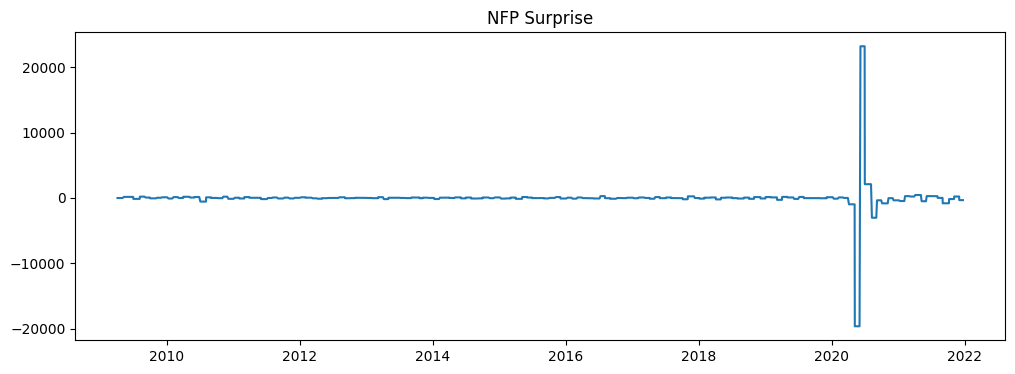

In [147]:
plt.figure(figsize=(12,4))
plt.plot(Dataset["date"], Dataset["NFP_NFP_Surprise"])
plt.title("NFP Surprise")
plt.show()

In [129]:
SUS=['date', 'open', 'high', 'low', 'close','volatility_10d','log_return_1d', 'log_return_10d', 'log_return_21d', 'ema_50',  'UNRATE_Unrate_release_date', 'UNRATE_actual', 'UNRATE_previous',
       'UNRATE_surprise', 'UNRATE_Surprise_Direction',
       'NFP_actual', 'NFP_previous', 'CPI_actual', 'CPI_previous', 'CPI_surprise',
          'CORE_CPI_actual', 'CORE_CPI_previous', 'CORE_CPI_surprise', 'PCE_actual', 
          'PCE_previous', 'PCE_surprise', 'CORE_PCE_actual', 'CORE_PCE_previous', 
          'CORE_PCE_surprise',
       'days_since_NFP', 'days_since_UNRATE', 'days_since_CPI',
       'days_since_CORE_CPI', 'days_since_PCE', 'days_since_CORE_PCE'
    ]


Macro=['date', 'open', 'high', 'low', 'close', 'tick_volume', 'spread',
       'real_volume', 'UNRATE_Unrate_release_date', 'UNRATE_actual',
       'UNRATE_previous', 'UNRATE_surprise', 'UNRATE_Surprise_Direction',
       'NFP_NFP_release_date', 'NFP_actual', 'NFP_previous', 'NFP_Jobs_Added',
       'NFP_Previous_FF', 'NFP_NFP_Surprise', 'NFP_Surprise_Direction',
       'CPI_CPI_release_date', 'CPI_actual', 'CPI_previous', 'CPI_surprise',
       'CPI_CPI_MoM', 'CPI_CPI_YoY', 'CPI_CPI_MoM_Prev', 'CPI_CPI_YoY_Prev',
       'CPI_CPI_MoM_Surprise', 'CPI_CPI_YoY_Surprise', 'CPI_CPI_MoM_Direction',
       'CPI_CPI_YoY_Direction', 'CORE_CPI_Core_CPI_release_date',
       'CORE_CPI_actual', 'CORE_CPI_previous', 'CORE_CPI_surprise',
       'CORE_CPI_Core_CPI_MoM', 'CORE_CPI_Core_CPI_YoY',
       'CORE_CPI_Core_CPI_MoM_Prev', 'CORE_CPI_Core_CPI_YoY_Prev',
       'CORE_CPI_Core_CPI_MoM_Surprise', 'CORE_CPI_Core_CPI_YoY_Surprise',
       'CORE_CPI_Core_CPI_MoM_Direction', 'CORE_CPI_Core_CPI_YoY_Direction',
       'PCE_PCE_release_date', 'PCE_actual', 'PCE_previous', 'PCE_surprise',
       'PCE_PCE_MoM', 'PCE_PCE_YoY', 'PCE_PCE_MoM_Prev', 'PCE_PCE_YoY_Prev',
       'PCE_PCE_MoM_Surprise', 'PCE_PCE_YoY_Surprise', 'PCE_PCE_MoM_Direction',
       'PCE_PCE_YoY_Direction', 'CORE_PCE_Core_PCE_release_date',
       'CORE_PCE_actual', 'CORE_PCE_previous', 'CORE_PCE_surprise',
       'CORE_PCE_Core_PCE_MoM', 'CORE_PCE_Core_PCE_YoY',
       'CORE_PCE_Core_PCE_MoM_Prev', 'CORE_PCE_Core_PCE_YoY_Prev',
       'CORE_PCE_Core_PCE_MoM_Surprise', 'CORE_PCE_Core_PCE_YoY_Surprise',
       'CORE_PCE_Core_PCE_MoM_Direction', 'CORE_PCE_Core_PCE_YoY_Direction',
       'days_since_NFP', 'days_since_UNRATE', 'days_since_CPI',
       'days_since_CORE_CPI', 'days_since_PCE', 'days_since_CORE_PCE']

Tech=['date', 'open', 'high', 'low', 'close', 'tick_volume', 'spread',
       'real_volume', 'rsi_14', 'log_return_1d', 'log_return_10d',
       'log_return_21d', 'volatility_10d', 'dist_to_nearest_support',
       'dist_to_nearest_resistance', 'inside_zone', 'currently_touching_zone',
       'touching_support', 'touching_resistance', 'nearest_support_strength',
       'nearest_resistance_strength', 'nearest_support_age',
       'nearest_resistance_age', 'support_tested_recently',
       'resistance_tested_recently', 'sr_compression',
       'nearest_support_flipped', 'nearest_resistance_flipped', 'ema_50',
       'price_vs_ema', 'ema_slope', 'trend_structure', 'pullback_detected',
       'pullback_depth', 'approaching_support', 'approaching_resistance',
       'approaching_zone', 'trend_direction', 'trend_strength']

Moozy=['date', 'open', 'high', 'low', 'close','volatility_10d','volatility_3d','log_return_1d','log_return_10d','log_return_3d','log_return_21d', 'ema_50',  'UNRATE_Unrate_release_date', 'UNRATE_actual', 'UNRATE_previous',
       'UNRATE_surprise', 'UNRATE_Surprise_Direction', 'NFP_NFP_release_date',
       'NFP_Jobs_Added', 'NFP_Previous_FF', 'NFP_NFP_Surprise',
       'NFP_Surprise_Direction', 'CPI_CPI_release_date', 'CPI_CPI_MoM',
        'CPI_CPI_MoM_Prev',
       'CPI_CPI_MoM_Surprise', 'CPI_CPI_MoM_Direction',
        'CORE_CPI_Core_CPI_release_date',
       'CORE_CPI_Core_CPI_MoM', 
       'CORE_CPI_Core_CPI_MoM_Prev', 
       'CORE_CPI_Core_CPI_MoM_Surprise',
       'CORE_CPI_Core_CPI_MoM_Direction', 
       'PCE_PCE_release_date', 'PCE_PCE_MoM',
       'PCE_PCE_MoM_Prev',  'PCE_PCE_MoM_Surprise',
        'PCE_PCE_MoM_Direction',
        'CORE_PCE_Core_PCE_release_date',
       'CORE_PCE_Core_PCE_MoM',
       'CORE_PCE_Core_PCE_MoM_Prev',
       'CORE_PCE_Core_PCE_MoM_Surprise',
       'CORE_PCE_Core_PCE_MoM_Direction',
       'days_since_NFP', 'days_since_UNRATE', 'days_since_CPI',
       'days_since_CORE_CPI', 'days_since_PCE', 'days_since_CORE_PCE'
    ]

Moozy_Tech=['date', 'open', 'high', 'low', 'close','volatility_10d','volatility_3d','log_return_1d',
            'log_return_10d','log_return_3d','log_return_21d', 'ema_50',   'dist_to_nearest_support',
       'dist_to_nearest_resistance', 'touching_support', 'touching_resistance', 'nearest_support_strength',
       'nearest_resistance_strength', 'nearest_support_age',
       'nearest_resistance_age', 'support_tested_recently',
       'resistance_tested_recently',  'nearest_support_flipped', 'nearest_resistance_flipped',
       'trend_structure', 'pullback_detected',
       'pullback_depth', 'approaching_support', 'approaching_resistance',
       'UNRATE_Unrate_release_date', 'UNRATE_actual', 'UNRATE_previous',
       'UNRATE_surprise', 'UNRATE_Surprise_Direction', 'NFP_NFP_release_date',
       'NFP_Jobs_Added', 'NFP_Previous_FF', 'NFP_NFP_Surprise',
       'NFP_Surprise_Direction', 'CPI_CPI_release_date', 'CPI_CPI_MoM',
        'CPI_CPI_MoM_Prev',
       'CPI_CPI_MoM_Surprise', 'CPI_CPI_MoM_Direction',
        'CORE_CPI_Core_CPI_release_date',
       'CORE_CPI_Core_CPI_MoM', 
       'CORE_CPI_Core_CPI_MoM_Prev', 
       'CORE_CPI_Core_CPI_MoM_Surprise',
       'CORE_CPI_Core_CPI_MoM_Direction', 
       'PCE_PCE_release_date', 'PCE_PCE_MoM',
       'PCE_PCE_MoM_Prev',  'PCE_PCE_MoM_Surprise',
        'PCE_PCE_MoM_Direction',
        'CORE_PCE_Core_PCE_release_date',
       'CORE_PCE_Core_PCE_MoM',
       'CORE_PCE_Core_PCE_MoM_Prev',
       'CORE_PCE_Core_PCE_MoM_Surprise',
       'CORE_PCE_Core_PCE_MoM_Direction',
       'days_since_NFP', 'days_since_UNRATE', 'days_since_CPI',
       'days_since_CORE_CPI', 'days_since_PCE', 'days_since_CORE_PCE'
    ]

In [145]:
len(Moozy_Tech)

65

In [130]:
Dataset=Dataset[Moozy_Tech]
##Dataset[['NFP_NFP_release_date','NFP_Jobs_Added']].tail(40)

##  Label 600 row


In [187]:
"""
Target Labeling — Weekly First-Touch, Monday Open -> Friday Close
============================================================
One label per calendar week, but NOT close-to-close. Within each week,
scans day by day (in order) from Monday's open and checks each day's
HIGH and LOW:

    - If a day's HIGH reaches Monday-open + up%   -> BUY  (1), stop scanning
    - If a day's HIGH reaches Monday-open + down% -> SELL (-1), stop scanning
      (down is negative, so this is checking the LOW against it)
    - Whichever threshold is touched FIRST (earliest day in the week) wins.
    - If neither is touched by the end of the week -> NO TRADE (0).

This means a Wednesday spike to +2% labels the week BUY even if price
closes the week negative — the label reflects "did we ever get the 2%
move," not "where did we end up." This is the standard first-touch /
triple-barrier style of labeling (minus a stop-loss barrier, which
isn't used here since you only asked for the up/down move barriers).

Same-day double touch (both up and down thresholds cleared within one
day's high/low range) is rare but possible — when it happens, this
uses the day's own close-vs-open direction to break the tie (can't
know true intraday sequencing from daily OHLC alone). This edge case
is flagged in the printed summary so you can inspect it if it matters
for your instrument.
"""

import numpy as np
import pandas as pd


def label_weekly_first_touch(
    df: pd.DataFrame,
    date_col: str = "date",
    up: float = 0.02,
    down: float = -0.02,
    min_days_in_week: int = 4,
    keep_only_entry_day: bool = True,
    label_name: str = "Dataset",
) -> pd.DataFrame:
    """
    df   : raw OHLCV dataframe, must contain 'open', 'high', 'low', 'close', date_col
    up   : weekly first-touch threshold for BUY (e.g. 0.02 = +2%), measured off HIGH
    down : weekly first-touch threshold for SELL (e.g. -0.02 = -2%), measured off LOW
    """
    out = df.copy()
    out[date_col] = pd.to_datetime(out[date_col])
    out = out.sort_values(date_col).reset_index(drop=True)

    iso = out[date_col].dt.isocalendar()
    out["_iso_year"] = iso["year"]
    out["_iso_week"] = iso["week"]

    results = []
    same_day_double_touch = 0

    for (yr, wk), grp in out.groupby(["_iso_year", "_iso_week"], sort=False):
        grp = grp.sort_values(date_col)
        n_days = len(grp)
        week_open = grp.iloc[0]["open"]
        entry_date = grp.iloc[0][date_col]
        exit_date = grp.iloc[-1][date_col]

        label = 0
        trigger_date = pd.NaT
        trigger_day_offset = None

        for offset, (_, row) in enumerate(grp.iterrows()):
            up_hit = (row["high"] - week_open) / week_open >= up
            down_hit = (row["low"] - week_open) / week_open <= down

            if up_hit and down_hit:
                same_day_double_touch += 1
                # Tie-break: same-day double touch — use the day's own
                # close-vs-open direction as a proxy for which extreme
                # likely printed first (can't know true intrabar order
                # from daily OHLC alone)
                day_return = row["close"] - row["open"]
                label = 1 if day_return >= 0 else -1
                trigger_date, trigger_day_offset = row[date_col], offset
                break
            elif up_hit:
                label = 1
                trigger_date, trigger_day_offset = row[date_col], offset
                break
            elif down_hit:
                label = -1
                trigger_date, trigger_day_offset = row[date_col], offset
                break

        results.append({
            "_iso_year": yr, "_iso_week": wk,
            "week_open": week_open, "n_days": n_days,
            "entry_date": entry_date, "exit_date": exit_date,
            "target": label, "trigger_date": trigger_date,
            "trigger_day_offset": trigger_day_offset,
        })

    week_summary = pd.DataFrame(results)

    short_weeks = (week_summary["n_days"] < min_days_in_week).sum()
    week_summary = week_summary[week_summary["n_days"] >= min_days_in_week].copy()

    if len(week_summary) > 0:
        last_date_in_df = out[date_col].max()
        if week_summary.iloc[-1]["exit_date"] == last_date_in_df:
            typical_days = week_summary["n_days"].mode().iloc[0]
            if week_summary.iloc[-1]["n_days"] < typical_days:
                week_summary = week_summary.iloc[:-1]

    merge_cols = ["_iso_year", "_iso_week", "week_open", "n_days",
                  "entry_date", "exit_date", "target", "trigger_date", "trigger_day_offset"]
    out = out.merge(week_summary[merge_cols], on=["_iso_year", "_iso_week"], how="inner")

    if keep_only_entry_day:
        out = out[out[date_col] == out["entry_date"]].reset_index(drop=True)

    out = out.drop(columns=["_iso_year", "_iso_week"])

    print(f"  [{label_name}] weeks found: {len(week_summary) + (1 if short_weeks else 0)}  "
          f"| kept: {len(week_summary)}  | dropped (< {min_days_in_week} trading days): {short_weeks}")
    print(f"  [{label_name}] rows in output: {len(out)}  "
          f"({'entry-day only' if keep_only_entry_day else 'all days per week, label broadcast'})")
    print(f"  [{label_name}] threshold: first-touch BUY >= {up:+.1%} (high) | "
          f"first-touch SELL <= {down:+.1%} (low), scanning from Monday open")
    if same_day_double_touch:
        print(f"  [{label_name}] NOTE: {same_day_double_touch} week(s) had both thresholds "
              f"touched on the same day — tie-broken by that day's close-vs-open direction")

    counts = out["target"].value_counts().sort_index()
    total = len(out)
    for cls, cnt in counts.items():
        lbl = {-1: "SELL (-1)", 0: "NO TRADE (0)", 1: "BUY (1)"}[cls]
        print(f"    {lbl:<12}: {cnt:>6}  ({cnt/total*100:.1f}%)")

    # How early in the week triggers tend to fire — useful sanity check
    triggered = week_summary[week_summary["target"] != 0]
    if len(triggered) > 0:
        print(f"\n  [{label_name}] Trigger day distribution (0=entry day, 4=last day of week):")
        for offset, cnt in triggered["trigger_day_offset"].value_counts().sort_index().items():
            print(f"    Day {int(offset)}: {cnt} weeks")

    return out


# ─────────────────────────────────────────────────────────────
# USAGE
# ─────────────────────────────────────────────────────────────
# Dataset      = label_weekly_first_touch(Dataset_raw,      date_col="date", up=0.02, down=-0.02, label_name="Train")
# Dataset_test = label_weekly_first_touch(Dataset_test_raw, date_col="date", up=0.02, down=-0.02, label_name="Test")

Dataset = label_weekly_first_touch(Dataset, date_col="date", up=0.02, down=-0.02, label_name="Dataset")

  [Dataset] weeks found: 625  | kept: 624  | dropped (< 4 trading days): 1
  [Dataset] rows in output: 624  (entry-day only)
  [Dataset] threshold: first-touch BUY >= +2.0% (high) | first-touch SELL <= -2.0% (low), scanning from Monday open
  [Dataset] NOTE: 4 week(s) had both thresholds touched on the same day — tie-broken by that day's close-vs-open direction
    SELL (-1)   :    206  (33.0%)
    NO TRADE (0):    225  (36.1%)
    BUY (1)     :    193  (30.9%)

  [Dataset] Trigger day distribution (0=entry day, 4=last day of week):
    Day 0: 63 weeks
    Day 1: 112 weeks
    Day 2: 91 weeks
    Day 3: 72 weeks
    Day 4: 61 weeks


### Daily Labell weekly target


In [131]:
"""
Target Labeling — Weekly First-Touch, Daily Rows Preserved
============================================================
Same first-touch logic as label_weekly_first_touch(), but instead of
keeping only the Monday (entry-day) row per week, this keeps every
daily row UP TO AND INCLUDING the day the threshold was first touched.

Why not just broadcast the label onto all 5 days of the week:
--------------------------------------------------------------
If a week triggers BUY on Wednesday, then Thursday's and Friday's
daily technical features (moving averages, RSI, zone touches, etc.)
already reflect the price move that CREATED the label. Including
those rows as if they were still valid decision points is leakage —
the outcome already happened and is baked into the feature values.

So the rule here is:
  - Week triggers on day k (0=Monday ... 4=Friday) -> keep days 0..k
    for that week. Day k itself is fine to keep (features on day k
    are computed as of that day's open / prior close, before day k's
    own high/low is known — the label isn't visible to the feature
    set at that point).
  - Week never triggers (NO TRADE) -> keep all days in that week,
    since the "will it touch 2%" question stays genuinely open the
    entire week.

Every kept row within a week carries that SAME week's target — the
reference point (Monday's open) and the outcome (touched / not
touched, and which direction) don't change day to day within a week,
only how many valid decision-point rows you get out of it.
"""

import numpy as np
import pandas as pd

DROP_COLS_WEEKLY = [
    'week_open',
    'n_days',
    'entry_date',
    'exit_date',
    'trigger_date',
    'trigger_day_offset',
]


def label_weekly_first_touch_daily(
    df: pd.DataFrame,
    date_col: str = "date",
    up: float = 0.02,
    down: float = -0.02,
    min_days_in_week: int = 4,
    label_name: str = "Dataset",
) -> pd.DataFrame:
    """
    Returns one row per valid daily decision point (see module docstring
    for the censoring rule), each carrying that week's target label.
    Drop DROP_COLS_WEEKLY (plus your usual OHLCV/date drops) before
    building the feature matrix — do not feed trigger_date or
    trigger_day_offset into the model, they encode the label itself.
    """
    out = df.copy()
    out[date_col] = pd.to_datetime(out[date_col])
    out = out.sort_values(date_col).reset_index(drop=True)

    iso = out[date_col].dt.isocalendar()
    out["_iso_year"] = iso["year"]
    out["_iso_week"] = iso["week"]

    results = []
    kept_rows = []
    same_day_double_touch = 0

    for (yr, wk), grp in out.groupby(["_iso_year", "_iso_week"], sort=False):
        grp = grp.sort_values(date_col).reset_index(drop=True)  # index 0..n-1 within week
        n_days = len(grp)
        week_open = grp.iloc[0]["open"]
        entry_date = grp.iloc[0][date_col]
        exit_date = grp.iloc[-1][date_col]

        label = 0
        trigger_date = pd.NaT
        trigger_day_offset = None

        for offset, row in grp.iterrows():
            up_hit = (row["high"] - week_open) / week_open >= up
            down_hit = (row["low"] - week_open) / week_open <= down

            if up_hit and down_hit:
                same_day_double_touch += 1
                day_return = row["close"] - row["open"]
                label = 1 if day_return >= 0 else -1
                trigger_date, trigger_day_offset = row[date_col], offset
                break
            elif up_hit:
                label = 1
                trigger_date, trigger_day_offset = row[date_col], offset
                break
            elif down_hit:
                label = -1
                trigger_date, trigger_day_offset = row[date_col], offset
                break

        results.append({
            "_iso_year": yr, "_iso_week": wk,
            "week_open": week_open, "n_days": n_days,
            "entry_date": entry_date, "exit_date": exit_date,
            "target": label, "trigger_date": trigger_date,
            "trigger_day_offset": trigger_day_offset,
        })

        if n_days < min_days_in_week:
            continue  # short week — excluded entirely, handled below via week_summary filter too

        # Censoring: keep days 0..trigger_day_offset if triggered, else all days
        cutoff = trigger_day_offset if trigger_day_offset is not None else (n_days - 1)
        week_rows = grp.iloc[: cutoff + 1].copy()
        week_rows["_iso_year"], week_rows["_iso_week"] = yr, wk
        kept_rows.append(week_rows)

    week_summary = pd.DataFrame(results)
    short_weeks = (week_summary["n_days"] < min_days_in_week).sum()
    week_summary_valid = week_summary[week_summary["n_days"] >= min_days_in_week].copy()

    # Drop most recent in-progress week (no Friday close yet), same as daily/weekly versions
    dropped_final_week = False
    if len(week_summary_valid) > 0:
        last_date_in_df = out[date_col].max()
        if week_summary_valid.iloc[-1]["exit_date"] == last_date_in_df:
            typical_days = week_summary_valid["n_days"].mode().iloc[0]
            if week_summary_valid.iloc[-1]["n_days"] < typical_days:
                last_yr, last_wk = week_summary_valid.iloc[-1][["_iso_year", "_iso_week"]]
                week_summary_valid = week_summary_valid.iloc[:-1]
                kept_rows = [r for r in kept_rows
                             if not ((r["_iso_year"].iloc[0] == last_yr) and (r["_iso_week"].iloc[0] == last_wk))]
                dropped_final_week = True

    daily_out = pd.concat(kept_rows, ignore_index=True) if kept_rows else out.iloc[0:0].copy()

    merge_cols = ["_iso_year", "_iso_week", "week_open", "n_days",
                  "entry_date", "exit_date", "target", "trigger_date", "trigger_day_offset"]
    daily_out = daily_out.merge(week_summary_valid[merge_cols], on=["_iso_year", "_iso_week"], how="inner")
    daily_out = daily_out.drop(columns=["_iso_year", "_iso_week"]).reset_index(drop=True)

    print(f"  [{label_name}] weeks found: {len(week_summary)}  "
          f"| kept: {len(week_summary_valid)}  | dropped short weeks: {short_weeks}"
          f"{'  | dropped in-progress final week' if dropped_final_week else ''}")
    print(f"  [{label_name}] daily rows kept (censored at trigger day): {len(daily_out)}  "
          f"(vs {len(week_summary_valid)} if entry-day-only)")
    print(f"  [{label_name}] threshold: first-touch BUY >= {up:+.1%} (high) | "
          f"first-touch SELL <= {down:+.1%} (low), scanning from Monday open")
    if same_day_double_touch:
        print(f"  [{label_name}] NOTE: {same_day_double_touch} week(s) had both thresholds "
              f"touched on the same day — tie-broken by that day's close-vs-open direction")

    counts = daily_out["target"].value_counts().sort_index()
    total = len(daily_out)
    for cls, cnt in counts.items():
        lbl = {-1: "SELL (-1)", 0: "NO TRADE (0)", 1: "BUY (1)"}[cls]
        print(f"    {lbl:<12}: {cnt:>6}  ({cnt/total*100:.1f}%)")

    print(f"\n  IMPORTANT: drop these columns before building your feature matrix "
          f"(on top of your usual date/OHLCV drops): {DROP_COLS_WEEKLY}")

    return daily_out


# ─────────────────────────────────────────────────────────────
# USAGE
# ─────────────────────────────────────────────────────────────
# Dataset      = label_weekly_first_touch_daily(Dataset_raw,      date_col="date", up=0.02, down=-0.02, label_name="Train")
# Dataset_test = label_weekly_first_touch_daily(Dataset_test_raw, date_col="date", up=0.02, down=-0.02, label_name="Test")
#
# Then in your training script:
# DROP_COLS = [
#     'date', 'time', 'open', 'high', 'low', 'close',
#     'tick_volume', 'spread', 'real_volume', 'target',
#     ... your existing drops ...
# ] + DROP_COLS_WEEKLY   # <- from this module

Dataset = label_weekly_first_touch_daily(Dataset, date_col="date", up=0.02, down=-0.02, label_name="Dataset")

  [Dataset] weeks found: 679  | kept: 677  | dropped short weeks: 1  | dropped in-progress final week
  [Dataset] daily rows kept (censored at trigger day): 2584  (vs 677 if entry-day-only)
  [Dataset] threshold: first-touch BUY >= +2.0% (high) | first-touch SELL <= -2.0% (low), scanning from Monday open
  [Dataset] NOTE: 4 week(s) had both thresholds touched on the same day — tie-broken by that day's close-vs-open direction
    SELL (-1)   :    568  (22.0%)
    NO TRADE (0):   1459  (56.5%)
    BUY (1)     :    557  (21.6%)

  IMPORTANT: drop these columns before building your feature matrix (on top of your usual date/OHLCV drops): ['week_open', 'n_days', 'entry_date', 'exit_date', 'trigger_date', 'trigger_day_offset']


In [19]:
drop_col=['NFP_actual', 'NFP_previous', 'CPI_actual', 'CPI_previous', 'CPI_surprise',
          'CORE_CPI_actual', 'CORE_CPI_previous', 'CORE_CPI_surprise', 'PCE_actual', 
          'PCE_previous', 'PCE_surprise', 'CORE_PCE_actual', 'CORE_PCE_previous', 
          'CORE_PCE_surprise']

#Dataset.drop(columns=drop_col ,inplace=True)

## Test Data

In [ ]:
macro_daily_test = build_fundamental_features(
    api_key    = "Enter your FRED API key here",
    start_date = "2022-01-01",
    end_date   = "2025-05-31",
)

  FRED Pull
  Period : 2022-01-01  →  2025-05-31
  Pulling CPIAUCSL     (cpi)...
  Pulling CPILFESL     (core_cpi)...
  Pulling PCEPI        (pce)...
  Pulling PCEPILFE     (core_pce)...
  Pulling PPIACO       (ppi)...
  Pulling PPIFIS       (core_ppi)...
  Pulling PAYEMS       (nfp)...
  Pulling UNRATE       (unrate)...

  Filtering to date window...
  Standardising series...
  Computing MoM, YoY, Surprise, Direction...
  Merging series on observation date...
  Expanding to daily calendar (merge_asof backward)...
  Computing days_since_* columns...

  Done.
  Shape        : (1247, 67)
  Date range   : 2022-01-01 → 2025-05-31
  Columns      : 67

  Lookahead guarantee:
    merge_asof direction='backward' — each day only
    sees values whose release_date <= that day's date.


In [22]:
symbol = "XAUUSD"
timeframe = mt5.TIMEFRAME_D1  # 1 Day candles

# Define date range
start = datetime(2022, 1, 1)
end   = datetime(2025, 5, 31)

# Get data
rates_test = mt5.copy_rates_range(symbol, timeframe, start, end)

# Convert to DataFrame
ttt = pd.DataFrame(rates_test)

# Convert timestamp
ttt['time'] = pd.to_datetime(ttt['time'], unit='s')

# Sort properly
ttt = ttt.sort_values("time").reset_index(drop=True)

ttt = ttt.rename(columns={'time': 'date'})
ttt

print(ttt.head())
print(ttt.tail())
print(ttt.columns)

        date     open     high      low    close  tick_volume  spread  \
0 2022-01-03  1830.63  1831.82  1798.32  1801.20        87227       5   
1 2022-01-04  1802.46  1816.74  1798.51  1814.36        95966       5   
2 2022-01-05  1813.84  1829.60  1808.32  1810.53        91086       5   
3 2022-01-06  1810.06  1811.58  1786.50  1789.72       114463       5   
4 2022-01-07  1791.18  1798.63  1782.64  1796.30        93200       5   

   real_volume  
0            0  
1            0  
2            0  
3            0  
4            0  
          date     open     high      low    close  tick_volume  spread  \
875 2025-05-26  3353.88  3356.76  3323.52  3342.19        59937       5   
876 2025-05-27  3343.87  3349.77  3284.90  3300.56        91570       5   
877 2025-05-28  3301.03  3325.44  3276.94  3288.64        84113       5   
878 2025-05-29  3287.71  3331.23  3245.52  3317.56       105319       5   
879 2025-05-30  3318.43  3322.70  3271.82  3288.72        93320       5   

     rea

In [23]:
data_test = add_all_features(ttt)

  Feature Engineering Pipeline  (event-driven S/R)

[1/4] RSI(14)...
[2/4] Log returns (1d, 10d, 21d)...
[3/4] Volatility (10d annualised)...

[4/4] S/R zone tracking (event-driven)...
      Zone created   : the moment a 2nd equal swing appears
      Zone respected : new swing point forms inside it (resets clock)
      Zone expires   : not respected for 126 bars
      Role reversal  : body close-through flips type (no reset, no delete)
      First active zone appears at bar 66 (not bar 126)
      First LIVE touch signal fires at bar 66 (zero-lag, same bar price enters zone)

[Trend] Computing trend structure, EMA, pullback detection...

  Done. 30 features added to df.
  S/R and trend features activate as soon as real setups
  form — not gated behind a fixed warm-up window.
  RSI/EMA still need their own short warm-up (50 bars) — that part is unavoidable math.



In [24]:
data_test['log_return_3d']

0           NaN
1           NaN
2           NaN
3     -0.006394
4     -0.010004
         ...   
875    0.008135
876    0.001774
877   -0.020842
878   -0.007397
879   -0.003594
Name: log_return_3d, Length: 880, dtype: float64

In [132]:
# ----------------------------
# Ensure dates are datetime
# ----------------------------
data_test['date'] = pd.to_datetime(data_test['date'])
macro_daily_test['date'] = pd.to_datetime(macro_daily_test['date'])

# ----------------------------
# Sort both datasets
# ----------------------------
data_test = data_test.sort_values('date')
macro_daily_test = macro_daily_test.sort_values('date')

# ----------------------------
# Merge onto technical data
# ----------------------------
Dataset_test = data_test.merge(
    macro_daily_test,
    on='date',
    how='left'
)

# ----------------------------
# Carry latest macro values
# forward to trading days
# ----------------------------
Dataset_test = Dataset_test.ffill()

# ----------------------------
# Reset index
# ----------------------------
Dataset_test = Dataset_test.reset_index(drop=True)

print(Dataset_test.shape)
Dataset_test

(880, 107)


,date,open,high,low,close,tick_volume,spread,real_volume,rsi_14,log_return_1d,...,CORE_PCE_Core_PCE_MoM_Surprise,CORE_PCE_Core_PCE_YoY_Surprise,CORE_PCE_Core_PCE_MoM_Direction,CORE_PCE_Core_PCE_YoY_Direction,days_since_NFP,days_since_UNRATE,days_since_CPI,days_since_CORE_CPI,days_since_PCE,days_since_CORE_PCE
0,2022-01-03,1830.63,1831.82,1798.32,1801.20,87227,5,0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2022-01-04,1802.46,1816.74,1798.51,1814.36,95966,5,0,NaN,0.007280,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2022-01-05,1813.84,1829.60,1808.32,1810.53,91086,5,0,NaN,-0.002113,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2022-01-06,1810.06,1811.58,1786.50,1789.72,114463,5,0,NaN,-0.011560,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2022-01-07,1791.18,1798.63,1782.64,1796.30,93200,5,0,NaN,0.003670,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
875,2025-05-26,3353.88,3356.76,3323.52,3342.19,59937,5,0,56.501968,-0.004689,...,-0.2,-0.2,-1.0,-1.0,24.0,24.0,13.0,13.0,26.0,26.0
876,2025-05-27,3343.87,3349.77,3284.90,3300.56,91570,5,0,52.717295,-0.012534,...,-0.2,-0.2,-1.0,-1.0,25.0,25.0,14.0,14.0,27.0,27.0
877,2025-05-28,3301.03,3325.44,3276.94,3288.64,84113,5,0,51.650469,-0.003618,...,-0.2,-0.2,-1.0,-1.0,26.0,26.0,15.0,15.0,28.0,28.0
878,2025-05-29,3287.71,3331.23,3245.52,3317.56,105319,5,0,54.078548,0.008755,...,-0.2,-0.2,-1.0,-1.0,27.0,27.0,16.0,16.0,29.0,29.0


In [ ]:
#Dataset_test.to_csv("Dataset_Test_Dashboard.csv", index=False)

In [133]:
Dataset_test=Dataset_test[Moozy_Tech]
Dataset_test

,date,open,high,low,close,volatility_10d,volatility_3d,log_return_1d,log_return_10d,log_return_3d,...,CORE_PCE_Core_PCE_MoM,CORE_PCE_Core_PCE_MoM_Prev,CORE_PCE_Core_PCE_MoM_Surprise,CORE_PCE_Core_PCE_MoM_Direction,days_since_NFP,days_since_UNRATE,days_since_CPI,days_since_CORE_CPI,days_since_PCE,days_since_CORE_PCE
0,2022-01-03,1830.63,1831.82,1798.32,1801.20,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2022-01-04,1802.46,1816.74,1798.51,1814.36,NaN,NaN,0.007280,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2022-01-05,1813.84,1829.60,1808.32,1810.53,NaN,NaN,-0.002113,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2022-01-06,1810.06,1811.58,1786.50,1789.72,NaN,0.149539,-0.011560,NaN,-0.006394,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2022-01-07,1791.18,1798.63,1782.64,1796.30,NaN,0.122047,0.003670,NaN,-0.010004,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
875,2025-05-26,3353.88,3356.76,3323.52,3342.19,0.227106,0.224202,-0.004689,0.032783,0.008135,...,0.2,0.4,-0.2,-1.0,24.0,24.0,13.0,13.0,26.0,26.0
876,2025-05-27,3343.87,3349.77,3284.90,3300.56,0.240147,0.260593,-0.012534,0.015443,0.001774,...,0.2,0.4,-0.2,-1.0,25.0,25.0,14.0,14.0,27.0,27.0
877,2025-05-28,3301.03,3325.44,3276.94,3288.64,0.202748,0.077277,-0.003618,0.034411,-0.020842,...,0.2,0.4,-0.2,-1.0,26.0,26.0,15.0,15.0,28.0,28.0
878,2025-05-29,3287.71,3331.23,3245.52,3317.56,0.185607,0.169722,0.008755,0.023767,-0.007397,...,0.2,0.4,-0.2,-1.0,27.0,27.0,16.0,16.0,29.0,29.0


In [27]:
#Dataset_test.drop(columns=drop_col ,inplace=True)
Dataset_test.shape

(880, 48)

## Test_Label

In [134]:
##Dataset_test = label_5d_move(Dataset_test, up=0.02, down=-0.02, label_name="Dataset_test")
#Dataset_test = label_weekly_first_touch(Dataset_test, date_col="date", up=0.02, down=-0.02, label_name="Dataset_test")

In [215]:
Dataset.columns

Index(['date', 'open', 'high', 'low', 'close', 'volatility_10d',
       'log_return_1d', 'log_return_21d', 'ema_50',
       'UNRATE_Unrate_release_date', 'UNRATE_actual', 'UNRATE_previous',
       'UNRATE_surprise', 'UNRATE_Surprise_Direction', 'NFP_NFP_release_date',
       'NFP_Jobs_Added', 'NFP_Previous_FF', 'NFP_NFP_Surprise',
       'NFP_Surprise_Direction', 'CPI_CPI_release_date', 'CPI_CPI_MoM',
       'CPI_CPI_MoM_Prev', 'CPI_CPI_MoM_Surprise', 'CPI_CPI_MoM_Direction',
       'CORE_CPI_Core_CPI_release_date', 'CORE_CPI_Core_CPI_MoM',
       'CORE_CPI_Core_CPI_MoM_Prev', 'CORE_CPI_Core_CPI_MoM_Surprise',
       'CORE_CPI_Core_CPI_MoM_Direction', 'PCE_PCE_release_date',
       'PCE_PCE_MoM', 'PCE_PCE_MoM_Prev', 'PCE_PCE_MoM_Surprise',
       'PCE_PCE_MoM_Direction', 'CORE_PCE_Core_PCE_release_date',
       'CORE_PCE_Core_PCE_MoM', 'CORE_PCE_Core_PCE_MoM_Prev',
       'CORE_PCE_Core_PCE_MoM_Surprise', 'CORE_PCE_Core_PCE_MoM_Direction',
       'days_since_NFP', 'days_since_UNRATE', 

In [135]:
Dataset_test  = label_weekly_first_touch_daily(Dataset_test , date_col="date", up=0.02, down=-0.02, label_name="Dataset_test")

  [Dataset_test] weeks found: 178  | kept: 178  | dropped short weeks: 0
  [Dataset_test] daily rows kept (censored at trigger day): 701  (vs 178 if entry-day-only)
  [Dataset_test] threshold: first-touch BUY >= +2.0% (high) | first-touch SELL <= -2.0% (low), scanning from Monday open
  [Dataset_test] NOTE: 1 week(s) had both thresholds touched on the same day — tie-broken by that day's close-vs-open direction
    SELL (-1)   :    119  (17.0%)
    NO TRADE (0):    354  (50.5%)
    BUY (1)     :    228  (32.5%)

  IMPORTANT: drop these columns before building your feature matrix (on top of your usual date/OHLCV drops): ['week_open', 'n_days', 'entry_date', 'exit_date', 'trigger_date', 'trigger_day_offset']


In [29]:
Dataset_test.shape

(701, 55)

In [ ]:
#Dataset_test=Dataset_test[Dataset_test['date']>="2023-03-01"]

## Checking for NFP,PCE Significance

In [125]:
"""
Feature -> Class Breakdown
============================================================
Answers questions like "was NFP_NFP_Surprise > 0 more associated with
SHORT, LONG, or NEUTRAL" — something feature_importances_ CANNOT tell
you. Importance only measures how much a feature helped the model
split data; it says nothing about direction or which specific class
the feature separates.

Two views, both useful:
  1. sign_or_bin_breakdown(): for each bin/sign of the feature, what
     % of rows in that bin belong to each class. Direct answer to
     "when NFP_Surprise is positive, what usually happens next."
  2. class_conditional_stats(): for each class, what's the typical
     value of the feature. Answers "is NFP_Surprise typically higher
     before a LONG week than before a SHORT week."

Also runs a chi-square test of independence (for the binned view) so
you're not eyeballing a pattern that's actually just noise — with a
few hundred rows split three ways, apparent patterns show up by
chance more often than you'd expect.
"""

import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency


CLASS_LABELS = {-1: "SHORT", 0: "NEUTRAL", 1: "LONG"}


def sign_or_bin_breakdown(
    df: pd.DataFrame,
    feature_col: str,
    target_col: str = "target",
    mode: str = "auto",   # "auto", "sign", or "tercile"
    label_name: str = "",
) -> pd.DataFrame:
    """
    mode="sign"    : splits into (<=0) vs (>0) — natural for features
                     like *_Surprise, *_Direction, log_return_* where
                     zero is a meaningful boundary
    mode="tercile" : splits into Low/Mid/High by value — better for
                     features with no natural zero point (e.g. RSI,
                     distance-to-zone, strength counts)
    mode="auto"    : uses "sign" if the feature actually takes both
                     positive and negative values, else "tercile"
    """
    work = df[[feature_col, target_col]].dropna().copy()

    if mode == "auto":
        mode = "sign" if (work[feature_col] < 0).any() and (work[feature_col] > 0).any() else "tercile"

    if mode == "sign":
        work["_bin"] = np.where(work[feature_col] > 0, "Positive (>0)", "Non-positive (<=0)")
    else:
        try:
            work["_bin"] = pd.qcut(work[feature_col], q=3, labels=["Low", "Mid", "High"], duplicates="drop")
        except ValueError:
            print(f"  Could not tercile-bin {feature_col} — too many repeated values.")
            return None

    work["_class"] = work[target_col].map(CLASS_LABELS)

    # % of each class WITHIN each bin — "when feature is X, what usually happens"
    pct_table = pd.crosstab(work["_bin"], work["_class"], normalize="index").round(3) * 100
    pct_table = pct_table[[c for c in ["SHORT", "NEUTRAL", "LONG"] if c in pct_table.columns]]
    count_table = pd.crosstab(work["_bin"], work["_class"])

    print(f"\n  ── {label_name or feature_col}: % of each class within each bin ──\n")
    print(pct_table)
    print(f"\n  ── row counts (n) ──\n")
    print(count_table)

    # Statistical significance — is this pattern real or plausibly noise?
    chi2, p, dof, expected = chi2_contingency(count_table)
    min_expected = expected.min()
    print(f"\n  Chi-square test of independence: p={p:.4f}"
          f"{'  (SIGNIFICANT at 0.05 — pattern likely real)' if p < 0.05 else '  (NOT significant — could plausibly be noise)'}")
    if min_expected < 5:
        print(f"  WARNING — smallest expected cell count is {min_expected:.1f} (<5). "
              f"Chi-square is unreliable this thin; treat the p-value as a rough guide, not proof.")

    return pct_table


def class_conditional_stats(
    df: pd.DataFrame,
    feature_col: str,
    target_col: str = "target",
    label_name: str = "",
) -> pd.DataFrame:
    """
    For each class, the feature's mean/median/std — "is this feature
    typically higher before a LONG week than a SHORT week."
    """
    work = df[[feature_col, target_col]].dropna().copy()
    work["_class"] = work[target_col].map(CLASS_LABELS)

    stats = work.groupby("_class")[feature_col].agg(['count', 'mean', 'median', 'std']).round(4)
    stats = stats.reindex([c for c in ["SHORT", "NEUTRAL", "LONG"] if c in stats.index])

    print(f"\n  ── {label_name or feature_col}: value by class ──\n")
    print(stats)

    return stats


# ─────────────────────────────────────────────────────────────
# USAGE
# ─────────────────────────────────────────────────────────────
# Run BOTH views for any top feature — they answer slightly different
# questions and are worth cross-checking against each other.
#
sign_or_bin_breakdown(Dataset, 'NFP_NFP_Surprise', label_name='NFP Surprise')
class_conditional_stats(Dataset, 'NFP_NFP_Surprise', label_name='NFP Surprise')
#
# sign_or_bin_breakdown(Dataset, 'log_return_3d', label_name='3-day log return')
# class_conditional_stats(Dataset, 'log_return_3d', label_name='3-day log return')
#
# For a feature with no natural zero (e.g. dist_to_nearest_support),
# mode="auto" will correctly fall back to terciles:
# sign_or_bin_breakdown(Dataset, 'dist_to_nearest_support', mode='auto')


  ── NFP Surprise: % of each class within each bin ──

_class              SHORT  NEUTRAL  LONG
_bin                                    
Non-positive (<=0)   24.1     55.6  20.3
Positive (>0)        19.1     58.5  22.4

  ── row counts (n) ──

_class              LONG  NEUTRAL  SHORT
_bin                                    
Non-positive (<=0)   272      744    322
Positive (>0)        274      715    233

  Chi-square test of independence: p=0.0082  (SIGNIFICANT at 0.05 — pattern likely real)

  ── NFP Surprise: value by class ──

         count      mean  median        std
_class                                     
SHORT      555 -284.1387   -28.0  2057.5887
NEUTRAL   1459  122.6285     0.0  2534.6038
LONG       546  -98.5256     3.0  2387.2604


,count,mean,median,std
_class,,,,
SHORT,555,-284.1387,-28.0,2057.5887
NEUTRAL,1459,122.6285,0.0,2534.6038
LONG,546,-98.5256,3.0,2387.2604


In [126]:
sign_or_bin_breakdown(Dataset, 'log_return_3d', label_name='3-day log return')
class_conditional_stats(Dataset, 'log_return_3d', label_name='3-day log return')


  ── 3-day log return: % of each class within each bin ──

_class              SHORT  NEUTRAL  LONG
_bin                                    
Non-positive (<=0)   35.3     56.1   8.6
Positive (>0)        10.6     56.8  32.6

  ── row counts (n) ──

_class              LONG  NEUTRAL  SHORT
_bin                                    
Non-positive (<=0)   102      666    419
Positive (>0)        455      793    148

  Chi-square test of independence: p=0.0000  (SIGNIFICANT at 0.05 — pattern likely real)

  ── 3-day log return: value by class ──

         count    mean  median     std
_class                                
SHORT      567 -0.0094 -0.0088  0.0168
NEUTRAL   1459  0.0009  0.0010  0.0103
LONG       557  0.0116  0.0124  0.0134


,count,mean,median,std
_class,,,,
SHORT,567,-0.0094,-0.0088,0.0168
NEUTRAL,1459,0.0009,0.0010,0.0103
LONG,557,0.0116,0.0124,0.0134


In [124]:
"""
Batch Fundamental Feature Testing — CPI / PPI / PCE
============================================================
Runs the same bin-breakdown + chi-square test from before, but across
a whole group of CPI/PPI/PCE columns at once, then summarizes which
ones show a real (and which show a merely-noisy-looking) association
with the target class.

Multiple-comparisons correction
--------------------------------
Testing many features raises the odds that SOME of them hit p<0.05
purely by chance, even with zero real effect — the more you test, the
more "significant" results you'd expect to see for free. With ~15-20
features tested here, expect roughly 1 false positive around p~0.05
by chance alone.

Bonferroni correction handles this simply (if conservatively): divide
your significance threshold by the number of tests run. With 18 tests
at alpha=0.05, the adjusted threshold is ~0.0028 — only features
below THAT should be trusted as clearly real; anything between the
adjusted threshold and 0.05 is a "maybe, worth another look" result,
not a confirmed one.
"""

import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

CLASS_LABELS = {-1: "SHORT", 0: "NEUTRAL", 1: "LONG"}

# Candidate columns by group — checked against your actual dataframe,
# missing ones are reported rather than silently skipped
FUNDAMENTAL_TEST_GROUPS = {
    "CPI": [
        "CPI_CPI_MoM_Surprise", "CPI_CPI_YoY_Surprise",
        "CPI_CPI_MoM_Direction", "CPI_CPI_YoY_Direction",
        "CORE_CPI_Core_CPI_MoM_Surprise", "CORE_CPI_Core_CPI_YoY_Surprise",
        "CORE_CPI_Core_CPI_MoM_Direction", "CORE_CPI_Core_CPI_YoY_Direction",
    ],
    "PPI": [
        "PPI_PPI_MoM_Surprise", "PPI_PPI_YoY_Surprise",
        "PPI_PPI_MoM_Direction", "PPI_PPI_YoY_Direction",
    ],
    "PCE": [
        "PCE_PCE_MoM_Surprise", "PCE_PCE_YoY_Surprise",
        "PCE_PCE_MoM_Direction", "PCE_PCE_YoY_Direction",
        "CORE_PCE_Core_PCE_MoM_Surprise", "CORE_PCE_Core_PCE_YoY_Surprise",
        "CORE_PCE_Core_PCE_MoM_Direction", "CORE_PCE_Core_PCE_YoY_Direction",
    ],
}


def _bin_and_test(df, feature_col, target_col="target"):
    """Sign-split bin breakdown + chi-square test for one feature. Returns None if unusable."""
    work = df[[feature_col, target_col]].dropna().copy()
    if len(work) < 20:
        return None

    has_pos = (work[feature_col] > 0).any()
    has_nonpos = (work[feature_col] <= 0).any()
    if has_pos and has_nonpos:
        work["_bin"] = np.where(work[feature_col] > 0, "Positive (>0)", "Non-positive (<=0)")
    else:
        try:
            work["_bin"] = pd.qcut(work[feature_col], q=3, labels=["Low", "Mid", "High"], duplicates="drop")
        except ValueError:
            return None

    work["_class"] = work[target_col].map(CLASS_LABELS)
    count_table = pd.crosstab(work["_bin"], work["_class"])
    if count_table.shape[0] < 2 or count_table.shape[1] < 2:
        return None

    pct_table = pd.crosstab(work["_bin"], work["_class"], normalize="index").round(3) * 100
    chi2, p, dof, expected = chi2_contingency(count_table)

    return {
        "pct_table": pct_table,
        "count_table": count_table,
        "p_value": p,
        "min_expected": expected.min(),
        "n": len(work),
    }


def batch_fundamental_test(
    df: pd.DataFrame,
    groups: dict = None,
    target_col: str = "target",
    alpha: float = 0.05,
) -> pd.DataFrame:
    groups = groups or FUNDAMENTAL_TEST_GROUPS
    all_cols = [c for cols in groups.values() for c in cols]
    n_tests = 0
    results = []

    for group_name, cols in groups.items():
        present = [c for c in cols if c in df.columns]
        missing = [c for c in cols if c not in df.columns]

        print(f"\n{'='*60}")
        print(f"  {group_name}")
        print(f"{'='*60}")
        if missing:
            print(f"  NOT FOUND in dataframe (skipped): {missing}")
        if not present:
            print(f"  No {group_name} columns found — nothing to test.")
            continue

        for col in present:
            res = _bin_and_test(df, col, target_col)
            if res is None:
                print(f"\n  {col}: not enough usable data / variation to test — skipped")
                continue

            n_tests += 1
            results.append({
                "group": group_name, "feature": col,
                "p_value": res["p_value"], "n": res["n"],
                "min_expected": res["min_expected"],
            })

            print(f"\n  ── {col} ──")
            print(res["pct_table"])
            flag = "SIGNIFICANT" if res["p_value"] < alpha else "not significant"
            warn = "  (min expected cell < 5 — treat cautiously)" if res["min_expected"] < 5 else ""
            print(f"  p={res['p_value']:.4f}  n={res['n']}  [{flag} at alpha={alpha}]{warn}")

    if not results:
        print("\n  No features were testable.")
        return None

    summary = pd.DataFrame(results).sort_values("p_value").reset_index(drop=True)
    bonferroni_alpha = alpha / n_tests if n_tests > 0 else alpha

    print(f"\n{'='*60}")
    print(f"  SUMMARY — {n_tests} features tested")
    print(f"{'='*60}")
    print(f"  Raw threshold           : p < {alpha}")
    print(f"  Bonferroni-adjusted     : p < {bonferroni_alpha:.5f}  (accounts for testing {n_tests} features at once)")
    print()

    summary["raw_significant"] = summary["p_value"] < alpha
    summary["survives_bonferroni"] = summary["p_value"] < bonferroni_alpha
    print(summary[["group", "feature", "p_value", "n", "raw_significant", "survives_bonferroni"]].to_string(index=False))

    n_survive = summary["survives_bonferroni"].sum()
    print(f"\n  {summary['raw_significant'].sum()} feature(s) clear the raw p<{alpha} bar.")
    print(f"  {n_survive} feature(s) survive the stricter Bonferroni-adjusted bar — "
          f"{'these are the ones worth real confidence in' if n_survive > 0 else 'none do — treat all raw-significant results above as leads to investigate, not confirmed effects'}.")

    return summary


# ─────────────────────────────────────────────────────────────
# USAGE
# ─────────────────────────────────────────────────────────────
summary = batch_fundamental_test(Dataset, target_col='target')
#
# To test a custom set instead of the defaults:
summary = batch_fundamental_test(Dataset, groups={
     "CPI": ["CPI_CPI_YoY_Surprise", "CPI_CPI_MoM_Surprise"],
     "PCE": ["PCE_PCE_YoY_Surprise"],
 })


  CPI
  NOT FOUND in dataframe (skipped): ['CPI_CPI_YoY_Surprise', 'CPI_CPI_YoY_Direction', 'CORE_CPI_Core_CPI_YoY_Surprise', 'CORE_CPI_Core_CPI_YoY_Direction']

  ── CPI_CPI_MoM_Surprise ──
_class              LONG  NEUTRAL  SHORT
_bin                                    
Non-positive (<=0)  22.1     55.6   22.3
Positive (>0)       20.3     59.0   20.7
  p=0.2296  n=2557  [not significant at alpha=0.05]

  ── CPI_CPI_MoM_Direction ──
_class              LONG  NEUTRAL  SHORT
_bin                                    
Non-positive (<=0)  22.1     55.0   22.9
Positive (>0)       20.3     59.0   20.7
  p=0.1291  n=2573  [not significant at alpha=0.05]

  ── CORE_CPI_Core_CPI_MoM_Surprise ──
_class              LONG  NEUTRAL  SHORT
_bin                                    
Non-positive (<=0)  20.4     58.5   21.1
Positive (>0)       23.5     53.8   22.7
  p=0.0696  n=2557  [not significant at alpha=0.05]

  ── CORE_CPI_Core_CPI_MoM_Direction ──
_class              LONG  NEUTRAL  SHORT
_bin   

## XGBOOST

In [20]:
"""
XGBoost Training — 5-Day Movement Classifier
==============================================
Train : Dataset       (100% used for training)
Test  : Dataset_test  (fully separate, pulled independently)

Assumes both DataFrames already exist in your notebook/session with a
'target' column in {-1, 0, 1} (SHORT / NEUTRAL / LONG).

Design notes
------------
1. Chronological internal split (last 15% of Dataset) — used ONLY for
   early stopping. Dataset_test never touches training.
2. Class weights: sample_weight uses an *inverse-frequency* scheme, but
   with an extra multiplier on SHORT/LONG. Plain inverse-frequency
   weighting is usually not aggressive enough to stop softprob from
   defaulting to NEUTRAL when NEUTRAL sits in the middle of the
   probability simplex — bumping SHORT/LONG weight further pushes the
   decision boundary away from NEUTRAL.
3. Decision threshold tuning: instead of naive argmax on predict_proba,
   thresholds for SHORT/LONG are tuned on the internal validation slice
   to maximize F1 for each class. Argmax is what causes "collapse to
   NEUTRAL" when the NEUTRAL class dominates the prior — tuning the
   cutoff directly targets recall on the minority classes.
4. XGBoost handles feature NaN natively — no imputation needed.
"""

import gc
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

from xgboost import XGBClassifier
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_auc_score,
    log_loss,
    average_precision_score,
    f1_score,
)

# ─────────────────────────────────────────────────────────────
# CONFIG
# ─────────────────────────────────────────────────────────────

DROP_COLS = [
    'date', 'time',
    'open', 'high', 'low', 'close',
    'tick_volume', 'spread', 'real_volume',
    'target', 'future_return_5d',
    'entry_price', 'long_tp', 'long_sl', 'short_tp', 'short_sl',
    'UNRATE_Unrate_release_date',
    'NFP_NFP_release_date',
    'CPI_CPI_release_date',
    'CORE_CPI_Core_CPI_release_date',
    'PCE_PCE_release_date',
    'CORE_PCE_Core_PCE_release_date',
    'ema_50',
]

LABEL_MAP     = {-1: 0, 0: 1, 1: 2}
LABEL_MAP_INV = {0: -1, 1: 0, 2: 1}
CLASSES       = [-1, 0, 1]
CLASS_NAMES   = ["SHORT (-1)", "NEUTRAL (0)", "LONG (1)"]

VAL_FRACTION       = 0.15   # tail slice of Dataset, chronological, for early stopping + threshold tuning
EXTREME_WEIGHT_MULT = 1.5   # extra multiplier applied to SHORT/LONG sample weights on top of inverse-frequency


def downcast(df):
    for col in df.select_dtypes('float64').columns:
        df[col] = df[col].astype('float32')
    for col in df.select_dtypes('int64').columns:
        df[col] = df[col].astype('int32')
    return df


def build_sample_weights(y_enc: pd.Series) -> np.ndarray:
    """
    Inverse-frequency weights, with SHORT (enc=0) and LONG (enc=2)
    boosted by EXTREME_WEIGHT_MULT relative to NEUTRAL (enc=1).
    """
    counts = y_enc.value_counts()
    total  = len(y_enc)
    base_w = {c: total / (len(counts) * cnt) for c, cnt in counts.items()}

    mult = {0: EXTREME_WEIGHT_MULT, 1: 1.0, 2: EXTREME_WEIGHT_MULT}
    final_w = {c: base_w[c] * mult.get(c, 1.0) for c in base_w}

    return y_enc.map(final_w).values.astype('float32')


def tune_thresholds(y_val_true: np.ndarray, proba_val: np.ndarray) -> dict:
    """
    For SHORT (col 0) and LONG (col 2), sweep a probability cutoff and
    pick the one maximizing F1 for that class (one-vs-rest on the val
    slice). NEUTRAL is whatever's left after SHORT/LONG cutoffs are
    applied. Returns thresholds keyed by encoded class id.
    """
    thresholds = {}
    grid = np.arange(0.15, 0.60, 0.01)

    for cls_enc, cls_col in [(0, 0), (2, 2)]:
        y_bin = (y_val_true == cls_enc).astype(int)
        best_f1, best_t = -1, 0.33
        for t in grid:
            pred_bin = (proba_val[:, cls_col] >= t).astype(int)
            if pred_bin.sum() == 0:
                continue
            f1 = f1_score(y_bin, pred_bin, zero_division=0)
            if f1 > best_f1:
                best_f1, best_t = f1, t
        thresholds[cls_enc] = best_t

    return thresholds


def predict_with_thresholds(proba: np.ndarray, thresholds: dict) -> np.ndarray:
    """
    Assign SHORT/LONG if their tuned threshold is cleared; otherwise
    fall back to whichever of {SHORT, NEUTRAL, LONG} has highest prob.
    If both SHORT and LONG clear their thresholds (rare), pick the
    higher-probability one.
    """
    n = proba.shape[0]
    preds = np.full(n, 1, dtype=int)  # default NEUTRAL (encoded)

    short_ok = proba[:, 0] >= thresholds[0]
    long_ok  = proba[:, 2] >= thresholds[2]

    argmax_default = proba.argmax(axis=1)
    preds[~short_ok & ~long_ok] = argmax_default[~short_ok & ~long_ok]

    only_short = short_ok & ~long_ok
    only_long  = long_ok & ~short_ok
    both       = short_ok & long_ok

    preds[only_short] = 0
    preds[only_long]  = 2
    preds[both] = np.where(proba[both, 0] >= proba[both, 2], 0, 2)

    return preds


def evaluate(y_true, y_pred, y_prob, y_bin, feature_cols, model, label=""):
    print("\n" + "═" * 60)
    print(f"  EVALUATION — {label}")
    print("═" * 60)

    print("\n  ── Classification Report ──\n")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

    acc = accuracy_score(y_true, y_pred)
    print(f"  Accuracy  : {acc:.4f}")

    try:
        auc = roc_auc_score(y_bin, y_prob, multi_class='ovr', average='macro')
        print(f"  ROC-AUC   : {auc:.4f}")
    except Exception as e:
        auc = float('nan')
        print(f"  ROC-AUC   : could not compute ({e})")

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])
    print(f"\n  Confusion Matrix (rows=actual, cols=predicted)\n")
    print(f"  {'':>14} {'SHORT':>8} {'NEUTRAL':>9} {'LONG':>7}")
    for i, name in enumerate(["SHORT", "NEUTRAL", "LONG"]):
        print(f"  {name:>14} {cm[i,0]:>8} {cm[i,1]:>9} {cm[i,2]:>7}")

    print(f"\n  ── PR AUC per class ──\n")
    for idx, name in enumerate(CLASS_NAMES):
        ap = average_precision_score(y_bin[:, idx], y_prob[:, idx])
        prevalence = y_bin[:, idx].mean()
        lift = ap / prevalence if prevalence > 0 else float('nan')
        print(f"  {name:<14} PR-AUC={ap:.4f}  prevalence={prevalence:.4f}  lift={lift:.2f}x")

    return acc, auc


# ═══════════════════════════════════════════════════════════════
# STEP 1 — PREPARE TRAINING DATA (100% of Dataset)
# ═══════════════════════════════════════════════════════════════

print("=" * 60)
print("  STEP 1 — Training data")
print("=" * 60)

train = Dataset.copy()
before = len(train)
train = train[train['target'].notna()]
train = train[np.isfinite(train['target'].astype(float))]
train = train.reset_index(drop=True)
print(f"  Rows before target NaN drop : {before}")
print(f"  Rows after                  : {len(train)}")

drop_actual  = [c for c in DROP_COLS if c in train.columns]
feature_cols = [c for c in train.columns if c not in drop_actual]

X_train = downcast(train[feature_cols].copy())
y_train = train['target'].astype(int)
del train
gc.collect()

print(f"  Features      : {len(feature_cols)}")
print(f"  Training rows : {len(X_train)}")
print(f"  Class balance:")
for cls, cnt in y_train.value_counts().sort_index().items():
    lbl = {-1: "SHORT", 0: "NEUTRAL", 1: "LONG"}[cls]
    print(f"    {lbl:<8}: {cnt:>6}  ({cnt/len(y_train)*100:.1f}%)")

# ═══════════════════════════════════════════════════════════════
# STEP 2 — PREPARE TEST DATA (Dataset_test, fully separate)
# ═══════════════════════════════════════════════════════════════

print("\n" + "=" * 60)
print("  STEP 2 — Test data")
print("=" * 60)

test = Dataset_test.copy()
test = test[test['target'].notna()]
test = test[np.isfinite(test['target'].astype(float))]
test = test.reset_index(drop=True)

test_feat_cols = [c for c in feature_cols if c in test.columns]
X_test = downcast(test[test_feat_cols].copy())
y_test = test['target'].astype(int)
del test
gc.collect()

print(f"  Test rows : {len(X_test)}")

# ═══════════════════════════════════════════════════════════════
# STEP 3 — LABEL ENCODING (-1/0/1 → 0/1/2 for XGBoost)
# ═══════════════════════════════════════════════════════════════

y_train_enc = y_train.map(LABEL_MAP).astype('int32')
y_test_enc  = y_test.map(LABEL_MAP).astype('int32')

# ═══════════════════════════════════════════════════════════════
# STEP 4 — CHRONOLOGICAL INTERNAL VAL SPLIT
# Used for early stopping AND threshold tuning. Dataset_test is
# never touched here.
# ═══════════════════════════════════════════════════════════════

val_split = int(len(X_train) * (1 - VAL_FRACTION))

X_tr, X_val = X_train.iloc[:val_split], X_train.iloc[val_split:]
y_tr, y_val = y_train_enc.iloc[:val_split], y_train_enc.iloc[val_split:]

sw_tr = build_sample_weights(y_tr)

print(f"\n  Internal train slice : {len(X_tr)} rows")
print(f"  Internal val slice   : {len(X_val)} rows (early stopping + threshold tuning)")

# ═══════════════════════════════════════════════════════════════
# STEP 5 — TRAIN XGBOOST
# ═══════════════════════════════════════════════════════════════

print("\n" + "=" * 60)
print("  STEP 5 — Training XGBoost")
print("=" * 60)

xgb = XGBClassifier(
    n_estimators          = 500,
    max_depth             = 5,
    learning_rate         = 0.02,
    subsample             = 0.8,
    colsample_bytree      = 0.8,
    min_child_weight      = 10,
    gamma                 = 0.5,
    reg_lambda            = 2.0,
    objective             = 'multi:softprob',
    num_class             = 3,
    eval_metric           = 'mlogloss',
    early_stopping_rounds = 30,
    tree_method           = 'hist',
    max_bin               = 256,
    nthread               = 2,
    random_state          = 42,
)

xgb.fit(
    X_tr, y_tr,
    sample_weight = sw_tr,
    eval_set      = [(X_val, y_val)],
    verbose       = False,
)

print(f"  Best iteration : {xgb.best_iteration}")
print(f"  Best val loss  : {xgb.best_score:.4f}")

# ═══════════════════════════════════════════════════════════════
# STEP 6 — TUNE SHORT/LONG DECISION THRESHOLDS ON VAL SLICE
# ═══════════════════════════════════════════════════════════════

proba_val  = xgb.predict_proba(X_val)
thresholds = tune_thresholds(y_val.values, proba_val)

print("\n  Tuned decision thresholds (val slice):")
print(f"    SHORT >= {thresholds[0]:.2f}  |  LONG >= {thresholds[2]:.2f}")
print("    (falls back to argmax when neither is cleared)")

del X_tr, X_val, y_tr, y_val, sw_tr, proba_val
gc.collect()

# ═══════════════════════════════════════════════════════════════
# STEP 7 — PREDICT ON Dataset_test
# ═══════════════════════════════════════════════════════════════

y_prob = xgb.predict_proba(X_test)

# Argmax baseline (what a naive model would output)
y_pred_argmax_enc = y_prob.argmax(axis=1)
y_pred_argmax = np.array([LABEL_MAP_INV[p] for p in y_pred_argmax_enc])

# Threshold-tuned predictions (targets SHORT/LONG recall)
y_pred_tuned_enc = predict_with_thresholds(y_prob, thresholds)
y_pred_tuned = np.array([LABEL_MAP_INV[p] for p in y_pred_tuned_enc])

y_true = y_test.values
y_bin  = label_binarize(y_true, classes=CLASSES)

# ═══════════════════════════════════════════════════════════════
# STEP 8 — EVALUATE BOTH (compare argmax vs tuned)
# ═══════════════════════════════════════════════════════════════

evaluate(y_true, y_pred_argmax, y_prob, y_bin, feature_cols, xgb, label="Argmax (baseline)")
evaluate(y_true, y_pred_tuned,  y_prob, y_bin, feature_cols, xgb, label="Threshold-tuned (SHORT/LONG recall)")

# ═══════════════════════════════════════════════════════════════
# STEP 9 — LOG LOSS + FEATURE IMPORTANCE
# ═══════════════════════════════════════════════════════════════

ll = log_loss(y_test_enc, y_prob)
print(f"\n  Log Loss (probability calibration): {ll:.4f}")

print("\n  ── Top 20 Feature Importances ──\n")
fi = pd.Series(xgb.feature_importances_, index=feature_cols).sort_values(ascending=False).head(20)
max_imp = fi.max()
for feat, imp in fi.items():
    bar = "█" * int((imp / max_imp) * 30)
    print(f"  {feat:<45} {imp:.4f}  {bar}")

del X_test
gc.collect()
print("\n  Done.")

  STEP 1 — Training data
  Rows before target NaN drop : 2310
  Rows after                  : 2310
  Features      : 76
  Training rows : 2310
  Class balance:
    SHORT   :    671  (29.0%)
    NEUTRAL :    841  (36.4%)
    LONG    :    798  (34.5%)

  STEP 2 — Test data
  Test rows : 1693

  Internal train slice : 1963 rows
  Internal val slice   : 347 rows (early stopping + threshold tuning)

  STEP 5 — Training XGBoost
  Best iteration : 8
  Best val loss  : 1.1416

  Tuned decision thresholds (val slice):
    SHORT >= 0.36  |  LONG >= 0.35
    (falls back to argmax when neither is cleared)

════════════════════════════════════════════════════════════
  EVALUATION — Argmax (baseline)
════════════════════════════════════════════════════════════

  ── Classification Report ──

              precision    recall  f1-score   support

  SHORT (-1)     0.2531    0.6510    0.3645       404
 NEUTRAL (0)     0.0000    0.0000    0.0000       792
    LONG (1)     0.2982    0.3924    0.3388     

## Fixed C

In [ ]:
"""
XGBoost Training — 5-Day Movement Classifier (v2, fixed)
============================================================
Train : Dataset       (100% used for training)
Test  : Dataset_test  (fully separate, pulled independently)
A
Assumes both DataFrames already exist in your session with a 'target'
column in {-1, 0, 1} (SHORT / NEUTRAL / LONG).

Fixes vs previous version
--------------------------
1. DROP_COLS no longer references columns that don't exist in this
   pipeline (entry_price/long_tp/long_sl/short_tp/short_sl removed).
2. confusion_matrix() now uses labels=CLASSES ([-1, 0, 1]) instead of
   [0, 1, 2] — previously this mismatch scrambled the printed matrix
   (values didn't sum to the true row/col totals).
3. EXTREME_WEIGHT_MULT defaults to 1.0 (plain inverse-frequency).
   1.5 fully suppressed NEUTRAL predictions — model never chose it,
   on both argmax and threshold-tuned output. Actual class weights
   used are printed before training so this is visible immediately,
   not just discoverable after the fact in final metrics.
"""

import gc
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

from xgboost import XGBClassifier
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_auc_score,
    log_loss,
    average_precision_score,
    f1_score,
)

# ─────────────────────────────────────────────────────────────
# CONFIG
# ─────────────────────────────────────────────────────────────

DROP_COLS = [
    'date', 'time',
    'open', 'high', 'low', 'close',
    'tick_volume', 'spread', 'real_volume',
    'target',
    'log_return_5d',
    'UNRATE_Unrate_release_date',
    'NFP_NFP_release_date',
    'CPI_CPI_release_date',
    'CORE_CPI_Core_CPI_release_date',
    'PCE_PCE_release_date',
    'CORE_PCE_Core_PCE_release_date',
    'week_open',
    'n_days',
    'entry_date',
    'exit_date',
    'trigger_date',
    'trigger_day_offset'
]

LABEL_MAP     = {-1: 0, 0: 1, 1: 2}
LABEL_MAP_INV = {0: -1, 1: 0, 2: 1}
CLASSES       = [-1, 0, 1]
CLASS_NAMES   = ["SHORT (-1)", "NEUTRAL (0)", "LONG (1)"]

VAL_FRACTION        = 0.15  # tail slice of Dataset, chronological — early stopping + threshold tuning only
EXTREME_WEIGHT_MULT  = 1.0  # extra multiplier on SHORT/LONG sample weights on top of inverse-frequency.
                             # 1.0 = plain inverse-frequency (safe default). Raise cautiously in small
                             # steps (e.g. 1.1) and check the printed weights + NEUTRAL recall each time —
                             # 1.5 was enough to fully zero out NEUTRAL predictions.


def downcast(df):
    for col in df.select_dtypes('float64').columns:
        df[col] = df[col].astype('float32')
    for col in df.select_dtypes('int64').columns:
        df[col] = df[col].astype('int32')
    return df


def build_sample_weights(y_enc: pd.Series) -> np.ndarray:
    """
    Inverse-frequency weights, with SHORT (enc=0) and LONG (enc=2)
    optionally boosted by EXTREME_WEIGHT_MULT relative to NEUTRAL (enc=1).
    """
    counts = y_enc.value_counts()
    total  = len(y_enc)
    base_w = {c: total / (len(counts) * cnt) for c, cnt in counts.items()}

    mult = {0: EXTREME_WEIGHT_MULT, 1: 1.0, 2: EXTREME_WEIGHT_MULT}
    final_w = {c: base_w[c] * mult.get(c, 1.0) for c in base_w}

    return y_enc.map(final_w).values.astype('float32'), final_w


def tune_thresholds(y_val_true: np.ndarray, proba_val: np.ndarray) -> dict:
    """
    For SHORT (col 0) and LONG (col 2), sweep a probability cutoff and
    pick the one maximizing F1 for that class (one-vs-rest on the val
    slice). NEUTRAL is whatever's left after SHORT/LONG cutoffs are
    applied. Returns thresholds keyed by encoded class id.
    """
    thresholds = {}
    grid = np.arange(0.15, 0.60, 0.01)

    for cls_enc, cls_col in [(0, 0), (2, 2)]:
        y_bin = (y_val_true == cls_enc).astype(int)
        best_f1, best_t = -1, 0.33
        for t in grid:
            pred_bin = (proba_val[:, cls_col] >= t).astype(int)
            if pred_bin.sum() == 0:
                continue
            f1 = f1_score(y_bin, pred_bin, zero_division=0)
            if f1 > best_f1:
                best_f1, best_t = f1, t
        thresholds[cls_enc] = best_t

    return thresholds


def predict_with_thresholds(proba: np.ndarray, thresholds: dict) -> np.ndarray:
    """
    Assign SHORT/LONG if their tuned threshold is cleared; otherwise
    fall back to whichever of {SHORT, NEUTRAL, LONG} has highest prob.
    If both SHORT and LONG clear their thresholds (rare), pick the
    higher-probability one.
    """
    n = proba.shape[0]
    preds = np.full(n, 1, dtype=int)  # default NEUTRAL (encoded)

    short_ok = proba[:, 0] >= thresholds[0]
    long_ok  = proba[:, 2] >= thresholds[2]

    argmax_default = proba.argmax(axis=1)
    preds[~short_ok & ~long_ok] = argmax_default[~short_ok & ~long_ok]

    only_short = short_ok & ~long_ok
    only_long  = long_ok & ~short_ok
    both       = short_ok & long_ok

    preds[only_short] = 0
    preds[only_long]  = 2
    preds[both] = np.where(proba[both, 0] >= proba[both, 2], 0, 2)

    return preds


def evaluate(y_true, y_pred, y_prob, y_bin, label=""):
    print("\n" + "═" * 60)
    print(f"  EVALUATION — {label}")
    print("═" * 60)

    print("\n  ── Classification Report ──\n")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

    acc = accuracy_score(y_true, y_pred)
    print(f"  Accuracy  : {acc:.4f}")

    try:
        auc = roc_auc_score(y_bin, y_prob, multi_class='ovr', average='macro')
        print(f"  ROC-AUC   : {auc:.4f}")
    except Exception as e:
        auc = float('nan')
        print(f"  ROC-AUC   : could not compute ({e})")

    # labels=CLASSES ([-1, 0, 1]) — must match the actual value domain
    # of y_true/y_pred, NOT the encoded 0/1/2 domain.
    cm = confusion_matrix(y_true, y_pred, labels=CLASSES)
    print(f"\n  Confusion Matrix (rows=actual, cols=predicted)\n")
    print(f"  {'':>14} {'SHORT':>8} {'NEUTRAL':>9} {'LONG':>7}")
    for i, name in enumerate(["SHORT", "NEUTRAL", "LONG"]):
        print(f"  {name:>14} {cm[i,0]:>8} {cm[i,1]:>9} {cm[i,2]:>7}")
    assert cm.sum() == len(y_true), "confusion matrix total mismatch — label domain bug"

    print(f"\n  ── PR AUC per class ──\n")
    for idx, name in enumerate(CLASS_NAMES):
        ap = average_precision_score(y_bin[:, idx], y_prob[:, idx])
        prevalence = y_bin[:, idx].mean()
        lift = ap / prevalence if prevalence > 0 else float('nan')
        print(f"  {name:<14} PR-AUC={ap:.4f}  prevalence={prevalence:.4f}  lift={lift:.2f}x")

    return acc, auc


# ═══════════════════════════════════════════════════════════════
# STEP 1 — PREPARE TRAINING DATA (100% of Dataset)
# ═══════════════════════════════════════════════════════════════

print("=" * 60)
print("  STEP 1 — Training data")
print("=" * 60)

train = Dataset.copy()
before = len(train)
train = train[train['target'].notna()]
train = train[np.isfinite(train['target'].astype(float))]
train = train.reset_index(drop=True)
print(f"  Rows before target NaN drop : {before}")
print(f"  Rows after                  : {len(train)}")

drop_actual  = [c for c in DROP_COLS if c in train.columns]
feature_cols = [c for c in train.columns if c not in drop_actual]

X_train = downcast(train[feature_cols].copy())
y_train = train['target'].astype(int)
del train
gc.collect()

print(f"  Features      : {len(feature_cols)}")
print(f"  Training rows : {len(X_train)}")
print(f"  Class balance:")
for cls, cnt in y_train.value_counts().sort_index().items():
    lbl = {-1: "SHORT", 0: "NEUTRAL", 1: "LONG"}[cls]
    print(f"    {lbl:<8}: {cnt:>6}  ({cnt/len(y_train)*100:.1f}%)")

# ═══════════════════════════════════════════════════════════════
# STEP 2 — PREPARE TEST DATA (Dataset_test, fully separate)
# ═══════════════════════════════════════════════════════════════

print("\n" + "=" * 60)
print("  STEP 2 — Test data")
print("=" * 60)

test = Dataset_test.copy()
test = test[test['target'].notna()]
test = test[np.isfinite(test['target'].astype(float))]
test = test.reset_index(drop=True)

test_feat_cols = [c for c in feature_cols if c in test.columns]
missing_in_test = [c for c in feature_cols if c not in test.columns]
if missing_in_test:
    print(f"  WARNING — features in train but missing from test (will break alignment): {missing_in_test}")

X_test = downcast(test[test_feat_cols].copy())
y_test = test['target'].astype(int) 
del test
gc.collect()

print(f"  Test rows : {len(X_test)}")
print(f"  Class balance:")
for cls, cnt in y_test.value_counts().sort_index().items():
    lbl = {-1: "SHORT", 0: "NEUTRAL", 1: "LONG"}[cls]
    print(f"    {lbl:<8}: {cnt:>6}  ({cnt/len(y_test)*100:.1f}%)")

# ═══════════════════════════════════════════════════════════════
# STEP 3 — LABEL ENCODING (-1/0/1 → 0/1/2 for XGBoost)
# ═══════════════════════════════════════════════════════════════

y_train_enc = y_train.map(LABEL_MAP).astype('int32')
y_test_enc  = y_test.map(LABEL_MAP).astype('int32')

# ═══════════════════════════════════════════════════════════════
# STEP 4 — CHRONOLOGICAL INTERNAL VAL SPLIT
# Used for early stopping AND threshold tuning. Dataset_test is
# never touched here.
# ═══════════════════════════════════════════════════════════════

val_split = int(len(X_train) * (1 - VAL_FRACTION))

X_tr, X_val = X_train.iloc[:val_split], X_train.iloc[val_split:]
y_tr, y_val = y_train_enc.iloc[:val_split], y_train_enc.iloc[val_split:]

sw_tr, weight_map = build_sample_weights(y_tr)

print(f"\n  Internal train slice : {len(X_tr)} rows")
print(f"  Internal val slice   : {len(X_val)} rows (early stopping + threshold tuning)")
print(f"  Sample weights by class (encoded 0=SHORT,1=NEUTRAL,2=LONG): "
      f"{ {k: round(v, 3) for k, v in weight_map.items()} }")

# ═══════════════════════════════════════════════════════════════
# STEP 5 — TRAIN XGBOOST
# ═══════════════════════════════════════════════════════════════

print("\n" + "=" * 60)
print("  STEP 5 — Training XGBoost")
print("=" * 60)

xgb = XGBClassifier(
    n_estimators          = 500,
    max_depth             = 5,
    learning_rate         = 0.02,
    subsample             = 0.8,
    colsample_bytree      = 0.8,
    min_child_weight      = 10,
    gamma                 = 0.5,
    reg_lambda            = 2.0,
    objective             = 'multi:softprob',
    num_class             = 3,
    eval_metric           = 'mlogloss',
    early_stopping_rounds = 30,
    tree_method           = 'hist',
    max_bin               = 256,
    nthread               = 2,
    random_state          = 42,
)

xgb.fit(
    X_tr, y_tr,
    sample_weight = sw_tr,
    eval_set      = [(X_val, y_val)],
    verbose       = False,
)

print(f"  Best iteration : {xgb.best_iteration}")
print(f"  Best val loss  : {xgb.best_score:.4f}")

# ═══════════════════════════════════════════════════════════════
# STEP 6 — TUNE SHORT/LONG DECISION THRESHOLDS ON VAL SLICE
# ═══════════════════════════════════════════════════════════════

proba_val  = xgb.predict_proba(X_val)
thresholds = tune_thresholds(y_val.values, proba_val)

print("\n  Tuned decision thresholds (val slice):")
print(f"    SHORT >= {thresholds[0]:.2f}  |  LONG >= {thresholds[2]:.2f}")
print("    (falls back to argmax when neither is cleared)")

del X_tr, X_val, y_tr, y_val, sw_tr, proba_val
gc.collect()

# ═══════════════════════════════════════════════════════════════
# STEP 7 — PREDICT ON Dataset_test
# ═══════════════════════════════════════════════════════════════

y_prob = xgb.predict_proba(X_test)

# Argmax baseline (what a naive model would output)
y_pred_argmax_enc = y_prob.argmax(axis=1)
y_pred_argmax = np.array([LABEL_MAP_INV[p] for p in y_pred_argmax_enc])

# Threshold-tuned predictions (targets SHORT/LONG recall)
y_pred_tuned_enc = predict_with_thresholds(y_prob, thresholds)
y_pred_tuned = np.array([LABEL_MAP_INV[p] for p in y_pred_tuned_enc])

y_true = y_test.values
y_bin  = label_binarize(y_true, classes=CLASSES)

# ═══════════════════════════════════════════════════════════════
# STEP 8 — EVALUATE BOTH (compare argmax vs tuned)
# ═══════════════════════════════════════════════════════════════

evaluate(y_true, y_pred_argmax, y_prob, y_bin, label="Argmax (baseline)")
evaluate(y_true, y_pred_tuned,  y_prob, y_bin, label="Threshold-tuned (SHORT/LONG recall)")

# ═══════════════════════════════════════════════════════════════
# STEP 9 — LOG LOSS + FEATURE IMPORTANCE
# ═══════════════════════════════════════════════════════════════

ll = log_loss(y_test_enc, y_prob)
print(f"\n  Log Loss (probability calibration): {ll:.4f}")

print("\n  ── Top 20 Feature Importances ──\n")
fi = pd.Series(xgb.feature_importances_, index=feature_cols).sort_values(ascending=False).head(20)
max_imp = fi.max()
for feat, imp in fi.items():
    bar = "█" * int((imp / max_imp) * 30)
    print(f"  {feat:<45} {imp:.4f}  {bar}")

del X_test
gc.collect()
print("\n  Done.")

  STEP 1 — Training data
  Rows before target NaN drop : 2584
  Rows after                  : 2584
  Features      : 54
  Training rows : 2584
  Class balance:
    SHORT   :    568  (22.0%)
    NEUTRAL :   1459  (56.5%)
    LONG    :    557  (21.6%)

  STEP 2 — Test data
  Test rows : 701
  Class balance:
    SHORT   :    119  (17.0%)
    NEUTRAL :    354  (50.5%)
    LONG    :    228  (32.5%)

  Internal train slice : 2196 rows
  Internal val slice   : 388 rows (early stopping + threshold tuning)
  Sample weights by class (encoded 0=SHORT,1=NEUTRAL,2=LONG): {1: 0.592, 0: 1.476, 2: 1.581}

  STEP 5 — Training XGBoost
  Best iteration : 283
  Best val loss  : 0.8679

  Tuned decision thresholds (val slice):
    SHORT >= 0.41  |  LONG >= 0.44
    (falls back to argmax when neither is cleared)

════════════════════════════════════════════════════════════
  EVALUATION — Argmax (baseline)
════════════════════════════════════════════════════════════

  ── Classification Report ──

          

## LightGBM

In [138]:
"""
LightGBM Training — 5-Day Movement Classifier
============================================================
Train : Dataset       (100% used for training)
Test  : Dataset_test  (fully separate, pulled independently)

Same DROP_COLS / label encoding / evaluation setup as the XGBoost
script, swapped to LGBMClassifier. LightGBM handles feature NaN
natively (like XGBoost) — no imputation needed.
"""

import gc
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

import lightgbm as lgb
from lightgbm import LGBMClassifier
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_auc_score,
    log_loss,
    average_precision_score,
    f1_score,
)

# ─────────────────────────────────────────────────────────────
# CONFIG
# ─────────────────────────────────────────────────────────────

DROP_COLS = [
   'date', 'time',
    'open', 'high', 'low', 'close',
    'tick_volume', 'spread', 'real_volume',
    'target',
    'log_return_5d',
    'n_days', 'week_open',
    'UNRATE_Unrate_release_date',
    'NFP_NFP_release_date',
    'CPI_CPI_release_date',
    'CORE_CPI_Core_CPI_release_date',
    'PCE_PCE_release_date',
    'CORE_PCE_Core_PCE_release_date',
     "entry_date",
    "exit_date",
    'week_open',
    'n_days',
    "trigger_date",
    'trigger_day_offset'
]

LABEL_MAP     = {-1: 0, 0: 1, 1: 2}
LABEL_MAP_INV = {0: -1, 1: 0, 2: 1}
CLASSES       = [-1, 0, 1]
CLASS_NAMES   = ["SHORT (-1)", "NEUTRAL (0)", "LONG (1)"]

VAL_FRACTION        = 0.15
EXTREME_WEIGHT_MULT  = 1.0  # 1.0 = plain inverse-frequency. Raise cautiously — see xgboost script notes.


def downcast(df):
    for col in df.select_dtypes('float64').columns:
        df[col] = df[col].astype('float32')
    for col in df.select_dtypes('int64').columns:
        df[col] = df[col].astype('int32')
    return df


def build_sample_weights(y_enc: pd.Series):
    counts = y_enc.value_counts()
    total  = len(y_enc)
    base_w = {c: total / (len(counts) * cnt) for c, cnt in counts.items()}
    mult = {0: EXTREME_WEIGHT_MULT, 1: 1.0, 2: EXTREME_WEIGHT_MULT}
    final_w = {c: base_w[c] * mult.get(c, 1.0) for c in base_w}
    return y_enc.map(final_w).values.astype('float32'), final_w


def tune_thresholds(y_val_true: np.ndarray, proba_val: np.ndarray) -> dict:
    thresholds = {}
    grid = np.arange(0.15, 0.60, 0.01)
    for cls_enc, cls_col in [(0, 0), (2, 2)]:
        y_bin = (y_val_true == cls_enc).astype(int)
        best_f1, best_t = -1, 0.33
        for t in grid:
            pred_bin = (proba_val[:, cls_col] >= t).astype(int)
            if pred_bin.sum() == 0:
                continue
            f1 = f1_score(y_bin, pred_bin, zero_division=0)
            if f1 > best_f1:
                best_f1, best_t = f1, t
        thresholds[cls_enc] = best_t
    return thresholds


def predict_with_thresholds(proba: np.ndarray, thresholds: dict) -> np.ndarray:
    n = proba.shape[0]
    preds = np.full(n, 1, dtype=int)
    short_ok = proba[:, 0] >= thresholds[0]
    long_ok  = proba[:, 2] >= thresholds[2]
    argmax_default = proba.argmax(axis=1)
    preds[~short_ok & ~long_ok] = argmax_default[~short_ok & ~long_ok]
    only_short = short_ok & ~long_ok
    only_long  = long_ok & ~short_ok
    both       = short_ok & long_ok
    preds[only_short] = 0
    preds[only_long]  = 2
    preds[both] = np.where(proba[both, 0] >= proba[both, 2], 0, 2)
    return preds


def evaluate(y_true, y_pred, y_prob, y_bin, label=""):
    print("\n" + "═" * 60)
    print(f"  EVALUATION — {label}")
    print("═" * 60)

    print("\n  ── Classification Report ──\n")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

    acc = accuracy_score(y_true, y_pred)
    print(f"  Accuracy  : {acc:.4f}")

    try:
        auc = roc_auc_score(y_bin, y_prob, multi_class='ovr', average='macro')
        print(f"  ROC-AUC   : {auc:.4f}")
    except Exception as e:
        auc = float('nan')
        print(f"  ROC-AUC   : could not compute ({e})")

    cm = confusion_matrix(y_true, y_pred, labels=CLASSES)
    print(f"\n  Confusion Matrix (rows=actual, cols=predicted)\n")
    print(f"  {'':>14} {'SHORT':>8} {'NEUTRAL':>9} {'LONG':>7}")
    for i, name in enumerate(["SHORT", "NEUTRAL", "LONG"]):
        print(f"  {name:>14} {cm[i,0]:>8} {cm[i,1]:>9} {cm[i,2]:>7}")
    assert cm.sum() == len(y_true), "confusion matrix total mismatch — label domain bug"

    print(f"\n  ── PR AUC per class ──\n")
    for idx, name in enumerate(CLASS_NAMES):
        ap = average_precision_score(y_bin[:, idx], y_prob[:, idx])
        prevalence = y_bin[:, idx].mean()
        lift = ap / prevalence if prevalence > 0 else float('nan')
        print(f"  {name:<14} PR-AUC={ap:.4f}  prevalence={prevalence:.4f}  lift={lift:.2f}x")

    return acc, auc


# ═══════════════════════════════════════════════════════════════
# STEP 1 — PREPARE TRAINING DATA
# ═══════════════════════════════════════════════════════════════

print("=" * 60)
print("  STEP 1 — Training data")
print("=" * 60)

train = Dataset.copy()
before = len(train)
train = train[train['target'].notna()]
train = train[np.isfinite(train['target'].astype(float))]
train = train.reset_index(drop=True)
print(f"  Rows before target NaN drop : {before}")
print(f"  Rows after                  : {len(train)}")

drop_actual  = [c for c in DROP_COLS if c in train.columns]
feature_cols = [c for c in train.columns if c not in drop_actual]

X_train = downcast(train[feature_cols].copy())
y_train = train['target'].astype(int)
del train
gc.collect()

print(f"  Features      : {len(feature_cols)}")
print(f"  Training rows : {len(X_train)}")
print(f"  Class balance:")
for cls, cnt in y_train.value_counts().sort_index().items():
    lbl = {-1: "SHORT", 0: "NEUTRAL", 1: "LONG"}[cls]
    print(f"    {lbl:<8}: {cnt:>6}  ({cnt/len(y_train)*100:.1f}%)")

# ═══════════════════════════════════════════════════════════════
# STEP 2 — PREPARE TEST DATA
# ═══════════════════════════════════════════════════════════════

print("\n" + "=" * 60)
print("  STEP 2 — Test data")
print("=" * 60)

test = Dataset_test.copy()
test = test[test['target'].notna()]
test = test[np.isfinite(test['target'].astype(float))]
test = test.reset_index(drop=True)

test_feat_cols = [c for c in feature_cols if c in test.columns]
missing_in_test = [c for c in feature_cols if c not in test.columns]
if missing_in_test:
    print(f"  WARNING — features in train but missing from test: {missing_in_test}")

X_test = downcast(test[test_feat_cols].copy())
y_test = test['target'].astype(int)
del test
gc.collect()

print(f"  Test rows : {len(X_test)}")
print(f"  Class balance:")
for cls, cnt in y_test.value_counts().sort_index().items():
    lbl = {-1: "SHORT", 0: "NEUTRAL", 1: "LONG"}[cls]
    print(f"    {lbl:<8}: {cnt:>6}  ({cnt/len(y_test)*100:.1f}%)")

# ═══════════════════════════════════════════════════════════════
# STEP 3 — LABEL ENCODING
# ═══════════════════════════════════════════════════════════════

y_train_enc = y_train.map(LABEL_MAP).astype('int32')
y_test_enc  = y_test.map(LABEL_MAP).astype('int32')

# ═══════════════════════════════════════════════════════════════
# STEP 4 — CHRONOLOGICAL INTERNAL VAL SPLIT
# Used for early stopping AND threshold tuning. Dataset_test never
# touches training.
# ═══════════════════════════════════════════════════════════════

val_split = int(len(X_train) * (1 - VAL_FRACTION))

X_tr, X_val = X_train.iloc[:val_split], X_train.iloc[val_split:]
y_tr, y_val = y_train_enc.iloc[:val_split], y_train_enc.iloc[val_split:]

sw_tr, weight_map = build_sample_weights(y_tr)

print(f"\n  Internal train slice : {len(X_tr)} rows")
print(f"  Internal val slice   : {len(X_val)} rows (early stopping + threshold tuning)")
print(f"  Sample weights by class (encoded 0=SHORT,1=NEUTRAL,2=LONG): "
      f"{ {k: round(v, 3) for k, v in weight_map.items()} }")

# ═══════════════════════════════════════════════════════════════
# STEP 5 — TRAIN LIGHTGBM
# ═══════════════════════════════════════════════════════════════

print("\n" + "=" * 60)
print("  STEP 5 — Training LightGBM")
print("=" * 60)

lgbm = LGBMClassifier(
    n_estimators       = 500,
    max_depth          = 6,
    num_leaves         = 31,          # keep <= 2^max_depth to avoid overfitting
    learning_rate      = 0.02,
    subsample          = 0.8,
    colsample_bytree   = 0.8,
    min_child_samples  = 30,
    reg_alpha          = 0.5,
    reg_lambda         = 2.0,
    objective          = 'multiclass',
    num_class          = 3,
    metric             = 'multi_logloss',
    random_state       = 42,
    n_jobs             = 2,
    verbosity          = -1,
)

lgbm.fit(
    X_tr, y_tr,
    sample_weight = sw_tr,
    eval_set      = [(X_val, y_val)],
    callbacks     = [lgb.early_stopping(stopping_rounds=30, verbose=False)],
)

print(f"  Best iteration : {lgbm.best_iteration_}")

# ═══════════════════════════════════════════════════════════════
# STEP 6 — TUNE SHORT/LONG DECISION THRESHOLDS ON VAL SLICE
# ═══════════════════════════════════════════════════════════════

proba_val  = lgbm.predict_proba(X_val)
thresholds = tune_thresholds(y_val.values, proba_val)

print("\n  Tuned decision thresholds (val slice):")
print(f"    SHORT >= {thresholds[0]:.2f}  |  LONG >= {thresholds[2]:.2f}")
print("    (falls back to argmax when neither is cleared)")

del X_tr, X_val, y_tr, y_val, sw_tr, proba_val
gc.collect()

# ═══════════════════════════════════════════════════════════════
# STEP 7 — PREDICT ON Dataset_test
# ═══════════════════════════════════════════════════════════════

y_prob = lgbm.predict_proba(X_test)

y_pred_argmax_enc = y_prob.argmax(axis=1)
y_pred_argmax = np.array([LABEL_MAP_INV[p] for p in y_pred_argmax_enc])

y_pred_tuned_enc = predict_with_thresholds(y_prob, thresholds)
y_pred_tuned = np.array([LABEL_MAP_INV[p] for p in y_pred_tuned_enc])

y_true = y_test.values
y_bin  = label_binarize(y_true, classes=CLASSES)

# ═══════════════════════════════════════════════════════════════
# STEP 8 — EVALUATE BOTH
# ═══════════════════════════════════════════════════════════════

evaluate(y_true, y_pred_argmax, y_prob, y_bin, label="Argmax (baseline)")
evaluate(y_true, y_pred_tuned,  y_prob, y_bin, label="Threshold-tuned (SHORT/LONG recall)")

# ═══════════════════════════════════════════════════════════════
# STEP 9 — LOG LOSS + FEATURE IMPORTANCE
# ═══════════════════════════════════════════════════════════════

ll = log_loss(y_test_enc, y_prob)
print(f"\n  Log Loss (probability calibration): {ll:.4f}")

print("\n  ── Top 20 Feature Importances ──\n")
fi = pd.Series(lgbm.feature_importances_, index=feature_cols).sort_values(ascending=False).head(20)
max_imp = fi.max()
for feat, imp in fi.items():
    bar = "█" * int((imp / max_imp) * 30)
    print(f"  {feat:<45} {imp:.4f}  {bar}")

del X_test
gc.collect()
print("\n  Done.")

  STEP 1 — Training data
  Rows before target NaN drop : 2584
  Rows after                  : 2584
  Features      : 54
  Training rows : 2584
  Class balance:
    SHORT   :    568  (22.0%)
    NEUTRAL :   1459  (56.5%)
    LONG    :    557  (21.6%)

  STEP 2 — Test data
  Test rows : 701
  Class balance:
    SHORT   :    119  (17.0%)
    NEUTRAL :    354  (50.5%)
    LONG    :    228  (32.5%)

  Internal train slice : 2196 rows
  Internal val slice   : 388 rows (early stopping + threshold tuning)
  Sample weights by class (encoded 0=SHORT,1=NEUTRAL,2=LONG): {1: 0.592, 0: 1.476, 2: 1.581}

  STEP 5 — Training LightGBM
  Best iteration : 166

  Tuned decision thresholds (val slice):
    SHORT >= 0.48  |  LONG >= 0.42
    (falls back to argmax when neither is cleared)

════════════════════════════════════════════════════════════
  EVALUATION — Argmax (baseline)
════════════════════════════════════════════════════════════

  ── Classification Report ──

              precision    recall  

## Decision Trees

In [139]:
"""
Decision Tree Training — 5-Day Movement Classifier
============================================================
Train : Dataset       (100% used for training)
Test  : Dataset_test  (fully separate, pulled independently)

Same DROP_COLS / label encoding / evaluation setup as the XGBoost
script, swapped to a single DecisionTreeClassifier.

Important difference from XGBoost/LightGBM
---------------------------------------------
sklearn's DecisionTreeClassifier does NOT handle NaN natively (unlike
XGBoost/LightGBM). Feature NaN is median-imputed here, with the
imputer fit ONLY on training data to avoid leakage into Dataset_test.

A single decision tree is also far more prone to overfitting than a
boosted ensemble — max_depth/min_samples_leaf/ccp_alpha are set
conservatively on purpose. Expect this to underperform XGBoost/LightGBM;
it's useful mainly as an interpretable baseline (you can literally
read the splits) and for feature importance sanity-checking, not as
your production model.
"""

import gc
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

from sklearn.tree import DecisionTreeClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_auc_score,
    log_loss,
    average_precision_score,
    f1_score,
)

# ─────────────────────────────────────────────────────────────
# CONFIG
# ─────────────────────────────────────────────────────────────

DROP_COLS = [
   'date', 'time',
    'open', 'high', 'low', 'close',
    'tick_volume', 'spread', 'real_volume',
    'target','week_open', 'n_days',
    'future_return_5d',
    'UNRATE_Unrate_release_date',
    'NFP_NFP_release_date',
    'CPI_CPI_release_date',
    'CORE_CPI_Core_CPI_release_date',
    'PCE_PCE_release_date',
    'CORE_PCE_Core_PCE_release_date',
     "entry_date",
    "exit_date",
    "trigger_date",
    'trigger_day_offset'
]

LABEL_MAP     = {-1: 0, 0: 1, 1: 2}
LABEL_MAP_INV = {0: -1, 1: 0, 2: 1}
CLASSES       = [-1, 0, 1]
CLASS_NAMES   = ["SHORT (-1)", "NEUTRAL (0)", "LONG (1)"]

VAL_FRACTION        = 0.15
EXTREME_WEIGHT_MULT  = 1.0  # 1.0 = plain inverse-frequency. Raise cautiously — see xgboost script notes.


def downcast(df):
    for col in df.select_dtypes('float64').columns:
        df[col] = df[col].astype('float32')
    for col in df.select_dtypes('int64').columns:
        df[col] = df[col].astype('int32')
    return df


def build_sample_weights(y_enc: pd.Series):
    counts = y_enc.value_counts()
    total  = len(y_enc)
    base_w = {c: total / (len(counts) * cnt) for c, cnt in counts.items()}
    mult = {0: EXTREME_WEIGHT_MULT, 1: 1.0, 2: EXTREME_WEIGHT_MULT}
    final_w = {c: base_w[c] * mult.get(c, 1.0) for c in base_w}
    return y_enc.map(final_w).values.astype('float32'), final_w


def tune_thresholds(y_val_true: np.ndarray, proba_val: np.ndarray) -> dict:
    thresholds = {}
    grid = np.arange(0.15, 0.60, 0.01)
    for cls_enc, cls_col in [(0, 0), (2, 2)]:
        y_bin = (y_val_true == cls_enc).astype(int)
        best_f1, best_t = -1, 0.33
        for t in grid:
            pred_bin = (proba_val[:, cls_col] >= t).astype(int)
            if pred_bin.sum() == 0:
                continue
            f1 = f1_score(y_bin, pred_bin, zero_division=0)
            if f1 > best_f1:
                best_f1, best_t = f1, t
        thresholds[cls_enc] = best_t
    return thresholds


def predict_with_thresholds(proba: np.ndarray, thresholds: dict) -> np.ndarray:
    n = proba.shape[0]
    preds = np.full(n, 1, dtype=int)
    short_ok = proba[:, 0] >= thresholds[0]
    long_ok  = proba[:, 2] >= thresholds[2]
    argmax_default = proba.argmax(axis=1)
    preds[~short_ok & ~long_ok] = argmax_default[~short_ok & ~long_ok]
    only_short = short_ok & ~long_ok
    only_long  = long_ok & ~short_ok
    both       = short_ok & long_ok
    preds[only_short] = 0
    preds[only_long]  = 2
    preds[both] = np.where(proba[both, 0] >= proba[both, 2], 0, 2)
    return preds


def evaluate(y_true, y_pred, y_prob, y_bin, label=""):
    print("\n" + "═" * 60)
    print(f"  EVALUATION — {label}")
    print("═" * 60)

    print("\n  ── Classification Report ──\n")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

    acc = accuracy_score(y_true, y_pred)
    print(f"  Accuracy  : {acc:.4f}")

    try:
        auc = roc_auc_score(y_bin, y_prob, multi_class='ovr', average='macro')
        print(f"  ROC-AUC   : {auc:.4f}")
    except Exception as e:
        auc = float('nan')
        print(f"  ROC-AUC   : could not compute ({e})")

    cm = confusion_matrix(y_true, y_pred, labels=CLASSES)
    print(f"\n  Confusion Matrix (rows=actual, cols=predicted)\n")
    print(f"  {'':>14} {'SHORT':>8} {'NEUTRAL':>9} {'LONG':>7}")
    for i, name in enumerate(["SHORT", "NEUTRAL", "LONG"]):
        print(f"  {name:>14} {cm[i,0]:>8} {cm[i,1]:>9} {cm[i,2]:>7}")
    assert cm.sum() == len(y_true), "confusion matrix total mismatch — label domain bug"

    print(f"\n  ── PR AUC per class ──\n")
    for idx, name in enumerate(CLASS_NAMES):
        ap = average_precision_score(y_bin[:, idx], y_prob[:, idx])
        prevalence = y_bin[:, idx].mean()
        lift = ap / prevalence if prevalence > 0 else float('nan')
        print(f"  {name:<14} PR-AUC={ap:.4f}  prevalence={prevalence:.4f}  lift={lift:.2f}x")

    return acc, auc


# ═══════════════════════════════════════════════════════════════
# STEP 1 — PREPARE TRAINING DATA
# ═══════════════════════════════════════════════════════════════

print("=" * 60)
print("  STEP 1 — Training data")
print("=" * 60)

train = Dataset.copy()
before = len(train)
train = train[train['target'].notna()]
train = train[np.isfinite(train['target'].astype(float))]
train = train.reset_index(drop=True)
print(f"  Rows before target NaN drop : {before}")
print(f"  Rows after                  : {len(train)}")

drop_actual  = [c for c in DROP_COLS if c in train.columns]
feature_cols = [c for c in train.columns if c not in drop_actual]

X_train = downcast(train[feature_cols].copy())
y_train = train['target'].astype(int)
del train
gc.collect()

print(f"  Features      : {len(feature_cols)}")
print(f"  Training rows : {len(X_train)}")
print(f"  Class balance:")
for cls, cnt in y_train.value_counts().sort_index().items():
    lbl = {-1: "SHORT", 0: "NEUTRAL", 1: "LONG"}[cls]
    print(f"    {lbl:<8}: {cnt:>6}  ({cnt/len(y_train)*100:.1f}%)")

# ═══════════════════════════════════════════════════════════════
# STEP 2 — PREPARE TEST DATA
# ═══════════════════════════════════════════════════════════════

print("\n" + "=" * 60)
print("  STEP 2 — Test data")
print("=" * 60)

test = Dataset_test.copy()
test = test[test['target'].notna()]
test = test[np.isfinite(test['target'].astype(float))]
test = test.reset_index(drop=True)

test_feat_cols = [c for c in feature_cols if c in test.columns]
missing_in_test = [c for c in feature_cols if c not in test.columns]
if missing_in_test:
    print(f"  WARNING — features in train but missing from test: {missing_in_test}")

X_test = downcast(test[test_feat_cols].copy())
y_test = test['target'].astype(int)
del test
gc.collect()

print(f"  Test rows : {len(X_test)}")
print(f"  Class balance:")
for cls, cnt in y_test.value_counts().sort_index().items():
    lbl = {-1: "SHORT", 0: "NEUTRAL", 1: "LONG"}[cls]
    print(f"    {lbl:<8}: {cnt:>6}  ({cnt/len(y_test)*100:.1f}%)")

# ═══════════════════════════════════════════════════════════════
# STEP 3 — LABEL ENCODING
# ═══════════════════════════════════════════════════════════════

y_train_enc = y_train.map(LABEL_MAP).astype('int32')
y_test_enc  = y_test.map(LABEL_MAP).astype('int32')

# ═══════════════════════════════════════════════════════════════
# STEP 4 — IMPUTE NaN (fit on train only — decision trees need this,
# unlike XGBoost/LightGBM which handle NaN natively)
# ═══════════════════════════════════════════════════════════════

print("\n" + "=" * 60)
print("  STEP 4 — Median imputation (fit on train only)")
print("=" * 60)

imputer = SimpleImputer(strategy='median')
X_train_imp = pd.DataFrame(
    imputer.fit_transform(X_train), columns=feature_cols, index=X_train.index
)
X_test_imp = pd.DataFrame(
    imputer.transform(X_test), columns=test_feat_cols, index=X_test.index
)
print(f"  Train NaN before: {X_train.isna().sum().sum()}  →  after: {X_train_imp.isna().sum().sum()}")
print(f"  Test  NaN before: {X_test.isna().sum().sum()}  →  after: {X_test_imp.isna().sum().sum()}")

del X_train, X_test
gc.collect()

# ═══════════════════════════════════════════════════════════════
# STEP 5 — CHRONOLOGICAL INTERNAL VAL SPLIT (threshold tuning only —
# a single decision tree has no early stopping)
# ═══════════════════════════════════════════════════════════════

val_split = int(len(X_train_imp) * (1 - VAL_FRACTION))

X_tr, X_val = X_train_imp.iloc[:val_split], X_train_imp.iloc[val_split:]
y_tr, y_val = y_train_enc.iloc[:val_split], y_train_enc.iloc[val_split:]

sw_tr, weight_map = build_sample_weights(y_tr)

print(f"\n  Internal train slice : {len(X_tr)} rows")
print(f"  Internal val slice   : {len(X_val)} rows (threshold tuning)")
print(f"  Sample weights by class (encoded 0=SHORT,1=NEUTRAL,2=LONG): "
      f"{ {k: round(v, 3) for k, v in weight_map.items()} }")

# ═══════════════════════════════════════════════════════════════
# STEP 6 — TRAIN DECISION TREE
# Kept shallow/regularized on purpose — a single tree overfits fast
# on 70+ noisy financial features.
# ═══════════════════════════════════════════════════════════════

print("\n" + "=" * 60)
print("  STEP 6 — Training Decision Tree")
print("=" * 60)

tree = DecisionTreeClassifier(
    max_depth          = 6,
    min_samples_leaf   = 40,
    min_samples_split  = 80,
    max_features        = 'sqrt',
    ccp_alpha          = 0.0005,   # post-pruning — trims weak splits
    class_weight       = None,     # handled via sample_weight instead
    random_state       = 42,
)

tree.fit(X_tr, y_tr, sample_weight=sw_tr)

print(f"  Tree depth        : {tree.get_depth()}")
print(f"  Leaf count        : {tree.get_n_leaves()}")

del X_tr, X_val, y_tr, y_val, sw_tr
gc.collect()

# ═══════════════════════════════════════════════════════════════
# STEP 7 — TUNE SHORT/LONG THRESHOLDS ON VAL SLICE
# ═══════════════════════════════════════════════════════════════

val_slice_X = X_train_imp.iloc[val_split:]
val_slice_y = y_train_enc.iloc[val_split:].values
proba_val   = tree.predict_proba(val_slice_X)
thresholds  = tune_thresholds(val_slice_y, proba_val)

print("\n  Tuned decision thresholds (val slice):")
print(f"    SHORT >= {thresholds[0]:.2f}  |  LONG >= {thresholds[2]:.2f}")

del X_train_imp, val_slice_X, proba_val
gc.collect()

# ═══════════════════════════════════════════════════════════════
# STEP 8 — PREDICT ON Dataset_test
# ═══════════════════════════════════════════════════════════════

y_prob = tree.predict_proba(X_test_imp)

y_pred_argmax_enc = y_prob.argmax(axis=1)
y_pred_argmax = np.array([LABEL_MAP_INV[p] for p in y_pred_argmax_enc])

y_pred_tuned_enc = predict_with_thresholds(y_prob, thresholds)
y_pred_tuned = np.array([LABEL_MAP_INV[p] for p in y_pred_tuned_enc])

y_true = y_test.values
y_bin  = label_binarize(y_true, classes=CLASSES)

# ═══════════════════════════════════════════════════════════════
# STEP 9 — EVALUATE
# ═══════════════════════════════════════════════════════════════

evaluate(y_true, y_pred_argmax, y_prob, y_bin, label="Argmax (baseline)")
evaluate(y_true, y_pred_tuned,  y_prob, y_bin, label="Threshold-tuned (SHORT/LONG recall)")

ll = log_loss(y_test_enc, y_prob)
print(f"\n  Log Loss (probability calibration): {ll:.4f}")

print("\n  ── Top 20 Feature Importances ──\n")
fi = pd.Series(tree.feature_importances_, index=feature_cols).sort_values(ascending=False).head(20)
max_imp = fi.max() if fi.max() > 0 else 1
for feat, imp in fi.items():
    bar = "█" * int((imp / max_imp) * 30)
    print(f"  {feat:<45} {imp:.4f}  {bar}")

del X_test_imp
gc.collect()
print("\n  Done.")

  STEP 1 — Training data
  Rows before target NaN drop : 2584
  Rows after                  : 2584
  Features      : 54
  Training rows : 2584
  Class balance:
    SHORT   :    568  (22.0%)
    NEUTRAL :   1459  (56.5%)
    LONG    :    557  (21.6%)

  STEP 2 — Test data
  Test rows : 701
  Class balance:
    SHORT   :    119  (17.0%)
    NEUTRAL :    354  (50.5%)
    LONG    :    228  (32.5%)

  STEP 4 — Median imputation (fit on train only)
  Train NaN before: 638  →  after: 0
  Test  NaN before: 1688  →  after: 0

  Internal train slice : 2196 rows
  Internal val slice   : 388 rows (threshold tuning)
  Sample weights by class (encoded 0=SHORT,1=NEUTRAL,2=LONG): {1: 0.592, 0: 1.476, 2: 1.581}

  STEP 6 — Training Decision Tree
  Tree depth        : 6
  Leaf count        : 33

  Tuned decision thresholds (val slice):
    SHORT >= 0.54  |  LONG >= 0.16

════════════════════════════════════════════════════════════
  EVALUATION — Argmax (baseline)
════════════════════════════════════════

## Suppose to handle Imbalance

In [140]:
"""
XGBoost Training — 5-Day Movement Classifier (imbalance-aware)
============================================================
Train : Dataset       (100% used for training)
Test  : Dataset_test  (fully separate, pulled independently)

For heavy imbalance (e.g. ~75% NEUTRAL / 12% SHORT / 13% LONG), full
inverse-frequency weighting (power=1.0) tends to overcorrect — it will
push SHORT/LONG weights to several times NEUTRAL's, which can crush
NEUTRAL recall to near zero (this is exactly what happened on a more
moderate 52/24/24 split, so it will very likely also happen here,
probably worse). Instead of guessing a fixed multiplier, this script
sweeps several damping levels on an internal validation slice and
selects the one that keeps all three classes usable before ever
touching Dataset_test.
"""

import gc
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

from xgboost import XGBClassifier
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_auc_score,
    log_loss,
    average_precision_score,
    f1_score,
    recall_score,
)

# ─────────────────────────────────────────────────────────────
# CONFIG
# ─────────────────────────────────────────────────────────────

DROP_COLS = [
 'date', 'time',
    'open', 'high', 'low', 'close',
    'tick_volume', 'spread', 'real_volume',
    'target',
    'log_return_5d',
    'UNRATE_Unrate_release_date',
    'NFP_NFP_release_date',
    'CPI_CPI_release_date',
    'CORE_CPI_Core_CPI_release_date',
    'PCE_PCE_release_date',
    'CORE_PCE_Core_PCE_release_date',
     "entry_date",
     'week_open',
     'n_days',
    "exit_date",
    "trigger_date",
    'trigger_day_offset'
]

LABEL_MAP     = {-1: 0, 0: 1, 1: 2}
LABEL_MAP_INV = {0: -1, 1: 0, 2: 1}
CLASSES       = [-1, 0, 1]
CLASS_NAMES   = ["SHORT (-1)", "NEUTRAL (0)", "LONG (1)"]

VAL_FRACTION = 0.15  # tail slice of Dataset, chronological — sweep + early stopping + threshold tuning

# power=1.0 -> full inverse-frequency (what crushed NEUTRAL before at a
# milder imbalance — very likely too strong here). power=0.0 -> no
# reweighting (majority-class dominance). Sweep in between.
WEIGHT_POWERS_TO_TRY = [0.0, 0.15, 0.25, 0.35, 0.5, 0.65, 0.8, 1.0]

# Reject any sweep config where a class's recall collapses below this —
# forces the selector to keep all three classes usable rather than
# chasing macro-F1 by sacrificing one class entirely.
MIN_ACCEPTABLE_RECALL = 0.10


def downcast(df):
    for col in df.select_dtypes('float64').columns:
        df[col] = df[col].astype('float32')
    for col in df.select_dtypes('int64').columns:
        df[col] = df[col].astype('int32')
    return df


def build_sample_weights(y_enc: pd.Series, power: float = 1.0):
    """
    power=1.0 -> full inverse-frequency (aggressive — can crush the majority class)
    power=0.0 -> no reweighting (all rows weight 1.0 — majority class dominates)
    0 < power < 1 -> damped inverse-frequency, softer pull toward minority classes
    """
    counts = y_enc.value_counts()
    total  = len(y_enc)
    inv_freq = {c: total / (len(counts) * cnt) for c, cnt in counts.items()}
    base_w = {c: w ** power for c, w in inv_freq.items()}
    return y_enc.map(base_w).values.astype('float32'), base_w


def tune_thresholds(y_val_true: np.ndarray, proba_val: np.ndarray) -> dict:
    thresholds = {}
    grid = np.arange(0.15, 0.60, 0.01)
    for cls_enc, cls_col in [(0, 0), (2, 2)]:
        y_bin = (y_val_true == cls_enc).astype(int)
        best_f1, best_t = -1, 0.33
        for t in grid:
            pred_bin = (proba_val[:, cls_col] >= t).astype(int)
            if pred_bin.sum() == 0:
                continue
            f1 = f1_score(y_bin, pred_bin, zero_division=0)
            if f1 > best_f1:
                best_f1, best_t = f1, t
        thresholds[cls_enc] = best_t
    return thresholds


def predict_with_thresholds(proba: np.ndarray, thresholds: dict) -> np.ndarray:
    n = proba.shape[0]
    preds = np.full(n, 1, dtype=int)
    short_ok = proba[:, 0] >= thresholds[0]
    long_ok  = proba[:, 2] >= thresholds[2]
    argmax_default = proba.argmax(axis=1)
    preds[~short_ok & ~long_ok] = argmax_default[~short_ok & ~long_ok]
    only_short = short_ok & ~long_ok
    only_long  = long_ok & ~short_ok
    both       = short_ok & long_ok
    preds[only_short] = 0
    preds[only_long]  = 2
    preds[both] = np.where(proba[both, 0] >= proba[both, 2], 0, 2)
    return preds


def evaluate(y_true, y_pred, y_prob, y_bin, label=""):
    print("\n" + "═" * 60)
    print(f"  EVALUATION — {label}")
    print("═" * 60)

    print("\n  ── Classification Report ──\n")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

    acc = accuracy_score(y_true, y_pred)
    print(f"  Accuracy  : {acc:.4f}")

    try:
        auc = roc_auc_score(y_bin, y_prob, multi_class='ovr', average='macro')
        print(f"  ROC-AUC   : {auc:.4f}")
    except Exception as e:
        auc = float('nan')
        print(f"  ROC-AUC   : could not compute ({e})")

    cm = confusion_matrix(y_true, y_pred, labels=CLASSES)
    print(f"\n  Confusion Matrix (rows=actual, cols=predicted)\n")
    print(f"  {'':>14} {'SHORT':>8} {'NEUTRAL':>9} {'LONG':>7}")
    for i, name in enumerate(["SHORT", "NEUTRAL", "LONG"]):
        print(f"  {name:>14} {cm[i,0]:>8} {cm[i,1]:>9} {cm[i,2]:>7}")
    assert cm.sum() == len(y_true), "confusion matrix total mismatch — label domain bug"

    print(f"\n  ── PR AUC per class ──\n")
    for idx, name in enumerate(CLASS_NAMES):
        ap = average_precision_score(y_bin[:, idx], y_prob[:, idx])
        prevalence = y_bin[:, idx].mean()
        lift = ap / prevalence if prevalence > 0 else float('nan')
        print(f"  {name:<14} PR-AUC={ap:.4f}  prevalence={prevalence:.4f}  lift={lift:.2f}x")

    return acc, auc


# ═══════════════════════════════════════════════════════════════
# STEP 1 — PREPARE TRAINING DATA
# ═══════════════════════════════════════════════════════════════

print("=" * 60)
print("  STEP 1 — Training data")
print("=" * 60)

train = Dataset.copy()
before = len(train)
train = train[train['target'].notna()]
train = train[np.isfinite(train['target'].astype(float))]
train = train.reset_index(drop=True)
print(f"  Rows before target NaN drop : {before}")
print(f"  Rows after                  : {len(train)}")

drop_actual  = [c for c in DROP_COLS if c in train.columns]
feature_cols = [c for c in train.columns if c not in drop_actual]

X_train = downcast(train[feature_cols].copy())
y_train = train['target'].astype(int)
del train
gc.collect()

print(f"  Features      : {len(feature_cols)}")
print(f"  Training rows : {len(X_train)}")
print(f"  Class balance:")
for cls, cnt in y_train.value_counts().sort_index().items():
    lbl = {-1: "SHORT", 0: "NEUTRAL", 1: "LONG"}[cls]
    print(f"    {lbl:<8}: {cnt:>6}  ({cnt/len(y_train)*100:.1f}%)")

# ═══════════════════════════════════════════════════════════════
# STEP 2 — PREPARE TEST DATA
# ═══════════════════════════════════════════════════════════════

print("\n" + "=" * 60)
print("  STEP 2 — Test data")
print("=" * 60)

test = Dataset_test.copy()
test = test[test['target'].notna()]
test = test[np.isfinite(test['target'].astype(float))]
test = test.reset_index(drop=True)

test_feat_cols = [c for c in feature_cols if c in test.columns]
missing_in_test = [c for c in feature_cols if c not in test.columns]
if missing_in_test:
    print(f"  WARNING — features in train but missing from test: {missing_in_test}")

X_test = downcast(test[test_feat_cols].copy())
y_test = test['target'].astype(int)
del test
gc.collect()

print(f"  Test rows : {len(X_test)}")
print(f"  Class balance:")
for cls, cnt in y_test.value_counts().sort_index().items():
    lbl = {-1: "SHORT", 0: "NEUTRAL", 1: "LONG"}[cls]
    print(f"    {lbl:<8}: {cnt:>6}  ({cnt/len(y_test)*100:.1f}%)")

# ═══════════════════════════════════════════════════════════════
# STEP 3 — LABEL ENCODING
# ═══════════════════════════════════════════════════════════════

y_train_enc = y_train.map(LABEL_MAP).astype('int32')
y_test_enc  = y_test.map(LABEL_MAP).astype('int32')

# ═══════════════════════════════════════════════════════════════
# STEP 4 — CHRONOLOGICAL INTERNAL VAL SPLIT
# ═══════════════════════════════════════════════════════════════

val_split = int(len(X_train) * (1 - VAL_FRACTION))

X_tr, X_val = X_train.iloc[:val_split], X_train.iloc[val_split:]
y_tr, y_val = y_train_enc.iloc[:val_split], y_train_enc.iloc[val_split:]

print(f"\n  Internal train slice : {len(X_tr)} rows")
print(f"  Internal val slice   : {len(X_val)} rows (weight sweep + early stopping + threshold tuning)")

# ═══════════════════════════════════════════════════════════════
# STEP 5 — WEIGHT-POWER SWEEP
# ═══════════════════════════════════════════════════════════════

print("\n" + "=" * 60)
print("  STEP 5 — Weight-power sweep (val slice)")
print("=" * 60)
print(f"\n  {'power':>6} {'macroF1':>9} {'SHORT_rec':>10} {'NEUTRAL_rec':>12} {'LONG_rec':>9}")

sweep_results = []
for power in WEIGHT_POWERS_TO_TRY:
    sw_tr_p, weight_map_p = build_sample_weights(y_tr, power=power)

    m = XGBClassifier(
        n_estimators=300, max_depth=5, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8, min_child_weight=10,
        gamma=0.5, reg_lambda=2.0,
        objective='multi:softprob', num_class=3, eval_metric='mlogloss',
        early_stopping_rounds=20, tree_method='hist', max_bin=256,
        nthread=2, random_state=42,
    )
    m.fit(X_tr, y_tr, sample_weight=sw_tr_p, eval_set=[(X_val, y_val)], verbose=False)

    val_pred = m.predict(X_val)
    macro_f1 = f1_score(y_val, val_pred, average='macro', zero_division=0)
    per_class_rec = recall_score(y_val, val_pred, average=None, labels=[0, 1, 2], zero_division=0)

    sweep_results.append({
        'power': power, 'macro_f1': macro_f1,
        'short_rec': per_class_rec[0], 'neutral_rec': per_class_rec[1], 'long_rec': per_class_rec[2],
        'weight_map': weight_map_p,
    })
    print(f"  {power:>6.2f} {macro_f1:>9.4f} {per_class_rec[0]:>10.4f} "
          f"{per_class_rec[1]:>12.4f} {per_class_rec[2]:>9.4f}")

viable = [r for r in sweep_results
          if min(r['short_rec'], r['neutral_rec'], r['long_rec']) >= MIN_ACCEPTABLE_RECALL]
best = max(viable, key=lambda r: r['macro_f1']) if viable else max(sweep_results, key=lambda r: r['macro_f1'])
BEST_POWER = best['power']

if not viable:
    print(f"\n  WARNING — no sweep config kept every class recall >= {MIN_ACCEPTABLE_RECALL}. "
          f"Falling back to best macro-F1 overall. At this imbalance level, consider also:\n"
          f"    - collapsing to a simpler binary task (TRADE vs NO-TRADE, then direction)\n"
          f"    - checking the +/-2% threshold isn't just too wide for this symbol's volatility")

print(f"\n  Selected WEIGHT_POWER = {BEST_POWER}  (macro-F1={best['macro_f1']:.4f}, "
      f"recalls: SHORT={best['short_rec']:.3f} NEUTRAL={best['neutral_rec']:.3f} LONG={best['long_rec']:.3f})")
print(f"  Sample weights used   : { {k: round(v, 3) for k, v in best['weight_map'].items()} }")

# ═══════════════════════════════════════════════════════════════
# STEP 6 — TRAIN FINAL XGBOOST WITH SELECTED WEIGHTING
# ═══════════════════════════════════════════════════════════════

print("\n" + "=" * 60)
print("  STEP 6 — Training final XGBoost")
print("=" * 60)

sw_tr, weight_map = build_sample_weights(y_tr, power=BEST_POWER)

xgb = XGBClassifier(
    n_estimators          = 500,
    max_depth             = 5,
    learning_rate         = 0.02,
    subsample             = 0.8,
    colsample_bytree      = 0.8,
    min_child_weight      = 10,
    gamma                 = 0.5,
    reg_lambda            = 2.0,
    objective             = 'multi:softprob',
    num_class             = 3,
    eval_metric           = 'mlogloss',
    early_stopping_rounds = 30,
    tree_method            = 'hist',
    max_bin                = 256,
    nthread                = 2,
    random_state           = 42,
)

xgb.fit(
    X_tr, y_tr,
    sample_weight = sw_tr,
    eval_set      = [(X_val, y_val)],
    verbose       = False,
)

print(f"  Best iteration : {xgb.best_iteration}")
print(f"  Best val loss  : {xgb.best_score:.4f}")

# ═══════════════════════════════════════════════════════════════
# STEP 7 — TUNE SHORT/LONG DECISION THRESHOLDS ON VAL SLICE
# ═══════════════════════════════════════════════════════════════

proba_val  = xgb.predict_proba(X_val)
thresholds = tune_thresholds(y_val.values, proba_val)

print("\n  Tuned decision thresholds (val slice):")
print(f"    SHORT >= {thresholds[0]:.2f}  |  LONG >= {thresholds[2]:.2f}")
print("    (falls back to argmax when neither is cleared)")

del X_tr, X_val, y_tr, y_val, sw_tr, proba_val
gc.collect()

# ═══════════════════════════════════════════════════════════════
# STEP 8 — PREDICT ON Dataset_test
# ═══════════════════════════════════════════════════════════════

y_prob = xgb.predict_proba(X_test)

y_pred_argmax_enc = y_prob.argmax(axis=1)
y_pred_argmax = np.array([LABEL_MAP_INV[p] for p in y_pred_argmax_enc])

y_pred_tuned_enc = predict_with_thresholds(y_prob, thresholds)
y_pred_tuned = np.array([LABEL_MAP_INV[p] for p in y_pred_tuned_enc])

y_true = y_test.values
y_bin  = label_binarize(y_true, classes=CLASSES)

# ═══════════════════════════════════════════════════════════════
# STEP 9 — EVALUATE BOTH
# ═══════════════════════════════════════════════════════════════

evaluate(y_true, y_pred_argmax, y_prob, y_bin, label="Argmax (baseline)")
evaluate(y_true, y_pred_tuned,  y_prob, y_bin, label="Threshold-tuned (SHORT/LONG recall)")

# ═══════════════════════════════════════════════════════════════
# STEP 10 — LOG LOSS + FEATURE IMPORTANCE
# ═══════════════════════════════════════════════════════════════

ll = log_loss(y_test_enc, y_prob)
print(f"\n  Log Loss (probability calibration): {ll:.4f}")

print("\n  ── Top 20 Feature Importances ──\n")
fi = pd.Series(xgb.feature_importances_, index=feature_cols).sort_values(ascending=False).head(20)
max_imp = fi.max()
for feat, imp in fi.items():
    bar = "█" * int((imp / max_imp) * 30)
    print(f"  {feat:<45} {imp:.4f}  {bar}")

del X_test
gc.collect()
print("\n  Done.")

  STEP 1 — Training data
  Rows before target NaN drop : 2584
  Rows after                  : 2584
  Features      : 54
  Training rows : 2584
  Class balance:
    SHORT   :    568  (22.0%)
    NEUTRAL :   1459  (56.5%)
    LONG    :    557  (21.6%)

  STEP 2 — Test data
  Test rows : 701
  Class balance:
    SHORT   :    119  (17.0%)
    NEUTRAL :    354  (50.5%)
    LONG    :    228  (32.5%)

  Internal train slice : 2196 rows
  Internal val slice   : 388 rows (weight sweep + early stopping + threshold tuning)

  STEP 5 — Weight-power sweep (val slice)

   power   macroF1  SHORT_rec  NEUTRAL_rec  LONG_rec
    0.00    0.5902     0.4028       0.8784    0.4043
    0.15    0.5881     0.4306       0.8423    0.4255
    0.25    0.5838     0.4167       0.8649    0.3936
    0.35    0.5739     0.4167       0.7973    0.4574
    0.50    0.5925     0.4861       0.7613    0.5106
    0.65    0.5918     0.5139       0.7252    0.5319
    0.80    0.5650     0.4861       0.7117    0.4894
    1.00    0.

## Random Forest

In [141]:
"""
Random Forest Training — 5-Day Movement Classifier
============================================================
Train : Dataset       (100% used for training)
Test  : Dataset_test  (fully separate, pulled independently)

Same DROP_COLS / label encoding / evaluation setup as the Decision
Tree script, swapped to RandomForestClassifier (bagged ensemble of
trees instead of a single tree).

Why this should beat the single Decision Tree
------------------------------------------------
A single tree overfits fast and its predictions are high-variance —
small changes in training data produce very different splits. Random
Forest averages many trees, each trained on a bootstrap resample with
a random feature subset per split, which cancels out a lot of that
variance. Expect meaningfully better generalization than the single
tree, though likely still behind XGBoost/LightGBM on this kind of
tabular financial data.

Still requires median imputation (sklearn RandomForestClassifier does
not handle NaN natively, same as DecisionTreeClassifier — unlike
XGBoost/LightGBM).
"""

import gc
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_auc_score,
    log_loss,
    average_precision_score,
    f1_score,
)

# ─────────────────────────────────────────────────────────────
# CONFIG
# ─────────────────────────────────────────────────────────────

DROP_COLS = [
    'date', 'time',
    'open', 'high', 'low', 'close',
    'tick_volume', 'spread', 'real_volume',
    'target',
    'future_return_5d',
    'UNRATE_Unrate_release_date',
    'NFP_NFP_release_date',
    'CPI_CPI_release_date',
    'CORE_CPI_Core_CPI_release_date',
    'PCE_PCE_release_date',
    'week_open',
    'n_days',
    'CORE_PCE_Core_PCE_release_date',
    "entry_date",
    "exit_date",
    "trigger_date",
    "trigger_day_offset",
]

LABEL_MAP     = {-1: 0, 0: 1, 1: 2}
LABEL_MAP_INV = {0: -1, 1: 0, 2: 1}
CLASSES       = [-1, 0, 1]
CLASS_NAMES   = ["SHORT (-1)", "NEUTRAL (0)", "LONG (1)"]

VAL_FRACTION        = 0.15
EXTREME_WEIGHT_MULT  = 1.0  # 1.0 = plain inverse-frequency. Raise cautiously — see xgboost script notes.


def downcast(df):
    for col in df.select_dtypes('float64').columns:
        df[col] = df[col].astype('float32')
    for col in df.select_dtypes('int64').columns:
        df[col] = df[col].astype('int32')
    return df


def build_sample_weights(y_enc: pd.Series):
    counts = y_enc.value_counts()
    total  = len(y_enc)
    base_w = {c: total / (len(counts) * cnt) for c, cnt in counts.items()}
    mult = {0: EXTREME_WEIGHT_MULT, 1: 1.0, 2: EXTREME_WEIGHT_MULT}
    final_w = {c: base_w[c] * mult.get(c, 1.0) for c in base_w}
    return y_enc.map(final_w).values.astype('float32'), final_w


def tune_thresholds(y_val_true: np.ndarray, proba_val: np.ndarray) -> dict:
    thresholds = {}
    grid = np.arange(0.15, 0.60, 0.01)
    for cls_enc, cls_col in [(0, 0), (2, 2)]:
        y_bin = (y_val_true == cls_enc).astype(int)
        best_f1, best_t = -1, 0.33
        for t in grid:
            pred_bin = (proba_val[:, cls_col] >= t).astype(int)
            if pred_bin.sum() == 0:
                continue
            f1 = f1_score(y_bin, pred_bin, zero_division=0)
            if f1 > best_f1:
                best_f1, best_t = f1, t
        thresholds[cls_enc] = best_t
    return thresholds


def predict_with_thresholds(proba: np.ndarray, thresholds: dict) -> np.ndarray:
    n = proba.shape[0]
    preds = np.full(n, 1, dtype=int)
    short_ok = proba[:, 0] >= thresholds[0]
    long_ok  = proba[:, 2] >= thresholds[2]
    argmax_default = proba.argmax(axis=1)
    preds[~short_ok & ~long_ok] = argmax_default[~short_ok & ~long_ok]
    only_short = short_ok & ~long_ok
    only_long  = long_ok & ~short_ok
    both       = short_ok & long_ok
    preds[only_short] = 0
    preds[only_long]  = 2
    preds[both] = np.where(proba[both, 0] >= proba[both, 2], 0, 2)
    return preds


def evaluate(y_true, y_pred, y_prob, y_bin, label=""):
    print("\n" + "═" * 60)
    print(f"  EVALUATION — {label}")
    print("═" * 60)

    print("\n  ── Classification Report ──\n")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

    acc = accuracy_score(y_true, y_pred)
    print(f"  Accuracy  : {acc:.4f}")

    try:
        auc = roc_auc_score(y_bin, y_prob, multi_class='ovr', average='macro')
        print(f"  ROC-AUC   : {auc:.4f}")
    except Exception as e:
        auc = float('nan')
        print(f"  ROC-AUC   : could not compute ({e})")

    cm = confusion_matrix(y_true, y_pred, labels=CLASSES)
    print(f"\n  Confusion Matrix (rows=actual, cols=predicted)\n")
    print(f"  {'':>14} {'SHORT':>8} {'NEUTRAL':>9} {'LONG':>7}")
    for i, name in enumerate(["SHORT", "NEUTRAL", "LONG"]):
        print(f"  {name:>14} {cm[i,0]:>8} {cm[i,1]:>9} {cm[i,2]:>7}")
    assert cm.sum() == len(y_true), "confusion matrix total mismatch — label domain bug"

    print(f"\n  ── PR AUC per class ──\n")
    for idx, name in enumerate(CLASS_NAMES):
        ap = average_precision_score(y_bin[:, idx], y_prob[:, idx])
        prevalence = y_bin[:, idx].mean()
        lift = ap / prevalence if prevalence > 0 else float('nan')
        print(f"  {name:<14} PR-AUC={ap:.4f}  prevalence={prevalence:.4f}  lift={lift:.2f}x")

    return acc, auc


# ═══════════════════════════════════════════════════════════════
# STEP 1 — PREPARE TRAINING DATA
# ═══════════════════════════════════════════════════════════════

print("=" * 60)
print("  STEP 1 — Training data")
print("=" * 60)

train = Dataset.copy()
before = len(train)
train = train[train['target'].notna()]
train = train[np.isfinite(train['target'].astype(float))]
train = train.reset_index(drop=True)
print(f"  Rows before target NaN drop : {before}")
print(f"  Rows after                  : {len(train)}")

drop_actual  = [c for c in DROP_COLS if c in train.columns]
feature_cols = [c for c in train.columns if c not in drop_actual]

X_train = downcast(train[feature_cols].copy())
y_train = train['target'].astype(int)
del train
gc.collect()

print(f"  Features      : {len(feature_cols)}")
print(f"  Training rows : {len(X_train)}")
print(f"  Class balance:")
for cls, cnt in y_train.value_counts().sort_index().items():
    lbl = {-1: "SHORT", 0: "NEUTRAL", 1: "LONG"}[cls]
    print(f"    {lbl:<8}: {cnt:>6}  ({cnt/len(y_train)*100:.1f}%)")

# ═══════════════════════════════════════════════════════════════
# STEP 2 — PREPARE TEST DATA
# ═══════════════════════════════════════════════════════════════

print("\n" + "=" * 60)
print("  STEP 2 — Test data")
print("=" * 60)

test = Dataset_test.copy()
test = test[test['target'].notna()]
test = test[np.isfinite(test['target'].astype(float))]
test = test.reset_index(drop=True)

test_feat_cols = [c for c in feature_cols if c in test.columns]
missing_in_test = [c for c in feature_cols if c not in test.columns]
if missing_in_test:
    print(f"  WARNING — features in train but missing from test: {missing_in_test}")

X_test = downcast(test[test_feat_cols].copy())
y_test = test['target'].astype(int)
del test
gc.collect()

print(f"  Test rows : {len(X_test)}")
print(f"  Class balance:")
for cls, cnt in y_test.value_counts().sort_index().items():
    lbl = {-1: "SHORT", 0: "NEUTRAL", 1: "LONG"}[cls]
    print(f"    {lbl:<8}: {cnt:>6}  ({cnt/len(y_test)*100:.1f}%)")

# ═══════════════════════════════════════════════════════════════
# STEP 3 — LABEL ENCODING
# ═══════════════════════════════════════════════════════════════

y_train_enc = y_train.map(LABEL_MAP).astype('int32')
y_test_enc  = y_test.map(LABEL_MAP).astype('int32')

# ═══════════════════════════════════════════════════════════════
# STEP 4 — IMPUTE NaN (fit on train only)
# ═══════════════════════════════════════════════════════════════

print("\n" + "=" * 60)
print("  STEP 4 — Median imputation (fit on train only)")
print("=" * 60)

imputer = SimpleImputer(strategy='median')
X_train_imp = pd.DataFrame(
    imputer.fit_transform(X_train), columns=feature_cols, index=X_train.index
)
X_test_imp = pd.DataFrame(
    imputer.transform(X_test), columns=test_feat_cols, index=X_test.index
)
print(f"  Train NaN before: {X_train.isna().sum().sum()}  →  after: {X_train_imp.isna().sum().sum()}")
print(f"  Test  NaN before: {X_test.isna().sum().sum()}  →  after: {X_test_imp.isna().sum().sum()}")

del X_train, X_test
gc.collect()

# ═══════════════════════════════════════════════════════════════
# STEP 5 — CHRONOLOGICAL INTERNAL VAL SPLIT (threshold tuning only —
# Random Forest doesn't use early stopping either)
# ═══════════════════════════════════════════════════════════════

val_split = int(len(X_train_imp) * (1 - VAL_FRACTION))

X_tr, X_val = X_train_imp.iloc[:val_split], X_train_imp.iloc[val_split:]
y_tr, y_val = y_train_enc.iloc[:val_split], y_train_enc.iloc[val_split:]

sw_tr, weight_map = build_sample_weights(y_tr)

print(f"\n  Internal train slice : {len(X_tr)} rows")
print(f"  Internal val slice   : {len(X_val)} rows (threshold tuning)")
print(f"  Sample weights by class (encoded 0=SHORT,1=NEUTRAL,2=LONG): "
      f"{ {k: round(v, 3) for k, v in weight_map.items()} }")

# ═══════════════════════════════════════════════════════════════
# STEP 6 — TRAIN RANDOM FOREST
# More trees + bootstrap aggregation than the single tree, but still
# regularized (max_depth/min_samples_leaf) since financial features
# are noisy and a forest of very deep trees will still overfit.
# ═══════════════════════════════════════════════════════════════

print("\n" + "=" * 60)
print("  STEP 6 — Training Random Forest")
print("=" * 60)

rf = RandomForestClassifier(
    n_estimators        = 500,
    max_depth            = 8,
    min_samples_leaf     = 20,
    min_samples_split    = 40,
    max_features          = 'sqrt',
    bootstrap             = True,
    class_weight          = None,   # handled via sample_weight instead
    n_jobs                = 2,
    random_state           = 42,
)

rf.fit(X_tr, y_tr, sample_weight=sw_tr)

print(f"  Trees trained     : {rf.n_estimators}")
print(f"  Avg tree depth    : {np.mean([est.get_depth() for est in rf.estimators_]):.1f}")
print(f"  Avg leaf count    : {np.mean([est.get_n_leaves() for est in rf.estimators_]):.1f}")

del X_tr, X_val, y_tr, y_val, sw_tr
gc.collect()

# ═══════════════════════════════════════════════════════════════
# STEP 7 — TUNE SHORT/LONG THRESHOLDS ON VAL SLICE
# ═══════════════════════════════════════════════════════════════

val_slice_X = X_train_imp.iloc[val_split:]
val_slice_y = y_train_enc.iloc[val_split:].values
proba_val   = rf.predict_proba(val_slice_X)
thresholds  = tune_thresholds(val_slice_y, proba_val)

print("\n  Tuned decision thresholds (val slice):")
print(f"    SHORT >= {thresholds[0]:.2f}  |  LONG >= {thresholds[2]:.2f}")

del X_train_imp, val_slice_X, proba_val
gc.collect()

# ═══════════════════════════════════════════════════════════════
# STEP 8 — PREDICT ON Dataset_test
# ═══════════════════════════════════════════════════════════════

y_prob = rf.predict_proba(X_test_imp)

y_pred_argmax_enc = y_prob.argmax(axis=1)
y_pred_argmax = np.array([LABEL_MAP_INV[p] for p in y_pred_argmax_enc])

y_pred_tuned_enc = predict_with_thresholds(y_prob, thresholds)
y_pred_tuned = np.array([LABEL_MAP_INV[p] for p in y_pred_tuned_enc])

y_true = y_test.values
y_bin  = label_binarize(y_true, classes=CLASSES)

# ═══════════════════════════════════════════════════════════════
# STEP 9 — EVALUATE
# ═══════════════════════════════════════════════════════════════

evaluate(y_true, y_pred_argmax, y_prob, y_bin, label="Argmax (baseline)")
evaluate(y_true, y_pred_tuned,  y_prob, y_bin, label="Threshold-tuned (SHORT/LONG recall)")

ll = log_loss(y_test_enc, y_prob)
print(f"\n  Log Loss (probability calibration): {ll:.4f}")

print("\n  ── Top 20 Feature Importances ──\n")
fi = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False).head(20)
max_imp = fi.max() if fi.max() > 0 else 1
for feat, imp in fi.items():
    bar = "█" * int((imp / max_imp) * 30)
    print(f"  {feat:<45} {imp:.4f}  {bar}")

del X_test_imp
gc.collect()
print("\n  Done.")

  STEP 1 — Training data
  Rows before target NaN drop : 2584
  Rows after                  : 2584
  Features      : 54
  Training rows : 2584
  Class balance:
    SHORT   :    568  (22.0%)
    NEUTRAL :   1459  (56.5%)
    LONG    :    557  (21.6%)

  STEP 2 — Test data
  Test rows : 701
  Class balance:
    SHORT   :    119  (17.0%)
    NEUTRAL :    354  (50.5%)
    LONG    :    228  (32.5%)

  STEP 4 — Median imputation (fit on train only)
  Train NaN before: 638  →  after: 0
  Test  NaN before: 1688  →  after: 0

  Internal train slice : 2196 rows
  Internal val slice   : 388 rows (threshold tuning)
  Sample weights by class (encoded 0=SHORT,1=NEUTRAL,2=LONG): {1: 0.592, 0: 1.476, 2: 1.581}

  STEP 6 — Training Random Forest
  Trees trained     : 500
  Avg tree depth    : 8.0
  Avg leaf count    : 44.9

  Tuned decision thresholds (val slice):
    SHORT >= 0.52  |  LONG >= 0.41

════════════════════════════════════════════════════════════
  EVALUATION — Argmax (baseline)
══════════

In [284]:
import os
import joblib

# Create a models directory in your current Jupyter working directory
os.makedirs("models", exist_ok=True)

# Package everything needed for inference
xgb_package = {
    "model": xgb,
    "feature_cols": feature_cols,
    "thresholds": thresholds,
    "label_map": LABEL_MAP,
    "label_map_inv": LABEL_MAP_INV,
    "classes": CLASSES,
    "class_names": CLASS_NAMES,
}

# Save
model_path = "models/xgboost_gold_classifier.joblib"

joblib.dump(xgb_package, model_path)

print(f"Model saved successfully to: {os.path.abspath(model_path)}")

Model saved successfully to: C:\Users\Admin\Downloads\Economic Dataset\models\xgboost_gold_classifier.joblib
